In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

print("--- Step 1: Initializing EMT Validation Matrix via AnnData ---")

# 1. Read the raw text table from disk
df = pd.read_csv("GSE200981_scRNAseq_processed.tsv", sep="\t", index_col=0)

# 2. Build AnnData and force immediate absolute uniqueness on gene names
adata_filtered = sc.AnnData(df.T)
adata_filtered.var_names_make_unique()

# 3. Pull out the clean cohort time strings at the end of the barcode index
cell_barcodes = adata_filtered.obs_names.values
extracted_stages = [barcode.split("_")[-1] for barcode in cell_barcodes]
adata_filtered.obs['sample'] = extracted_stages

print(f"\n✔ Successfully initialized! Subspace dimensions: {adata_filtered.shape}")
print("Cell counts per verified sequence stage:")
print(adata_filtered.obs['sample'].value_counts())


--- Step 1: Initializing EMT Validation Matrix via AnnData ---

✔ Successfully initialized! Subspace dimensions: (2125, 26364)
Cell counts per verified sequence stage:
sample
T0    383
T6    271
T4    268
T2    259
T7    256
T5    241
T1    240
T3    207
Name: count, dtype: int64


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [2]:
print(df.shape)
print(df.iloc[:5, :5])

values = df.to_numpy()

print("Min:", values.min())
print("Max:", values.max())
print("Mean:", values.mean())
print("Zeros:", np.mean(values == 0))
print("Integer-like:", np.mean(np.isclose(values, np.round(values))))

(26364, 2125)
            V1_T0  V2_T0  V3_T0  V4_T0  V5_T0
Gene.names                                   
DDX11L1         0      0      0      0      0
WASH7P          0      0      0      0      0
MIR6859.3       0      0      0      0      0
MIR6859.2       0      0      0      0      0
MIR6859.4       0      0      0      0      0
Min: 0
Max: 1120
Mean: 0.4917954429837479
Zeros: 0.8640221514186012
Integer-like: 1.0


In [3]:
import scanpy as sc
import numpy as np

# Reset from original raw UMI-count dataframe
adata_filtered = sc.AnnData(df.T)
adata_filtered.var_names_make_unique()
adata_filtered.obs["sample"] = [
    barcode.split("_")[-1]
    for barcode in adata_filtered.obs_names
]

# Fresh leakage-safe split
train_stages = ["T0","T1","T2","T3","T4","T5","T6"]

adata_train = adata_filtered[
    adata_filtered.obs["sample"].isin(train_stages)
].copy()

adata_t7 = adata_filtered[
    adata_filtered.obs["sample"] == "T7"
].copy()

print("Training shape:", adata_train.shape)
print("Blind T7 shape:", adata_t7.shape)



c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Training shape: (1869, 26364)
Blind T7 shape: (256, 26364)


In [4]:
print("Gene names unique:", adata_filtered.var_names.is_unique)
print("T7 present in training:", "T7" in set(adata_train.obs["sample"]))
print("Train/T7 overlap:", len(set(adata_train.obs_names) & set(adata_t7.obs_names)))
print("Gene order identical:", np.array_equal(adata_train.var_names, adata_t7.var_names))

Gene names unique: True
T7 present in training: False
Train/T7 overlap: 0
Gene order identical: True


In [5]:
adata_filtered.var_names_make_unique()

adata_train = adata_filtered[
    adata_filtered.obs["sample"].isin(["T0","T1","T2","T3","T4","T5","T6"])
].copy()

adata_t7 = adata_filtered[
    adata_filtered.obs["sample"] == "T7"
].copy()

In [6]:
# =========================================================
# STEP 2: LEAKAGE-SAFE PREPROCESSING
# =========================================================

print("--- Step 2: Leakage-Safe Preprocessing ---")

# 1. Filter genes using training cohort only
sc.pp.filter_genes(adata_train, min_cells=3)

# Keep the same genes in T7
adata_t7 = adata_t7[:, adata_train.var_names].copy()

# 2. Normalize + log-transform training
sc.pp.normalize_total(adata_train, target_sum=1e4)
sc.pp.log1p(adata_train)

# 3. Normalize + log-transform T7 independently
sc.pp.normalize_total(adata_t7, target_sum=1e4)
sc.pp.log1p(adata_t7)

# 4. Select 2,000 HVGs using training only
sc.pp.highly_variable_genes(
    adata_train,
    n_top_genes=2000,
    flavor="seurat",
    subset=False
)

hvg_names = adata_train.var_names[
    adata_train.var["highly_variable"]
].copy()

# 5. Restrict both objects to same training-selected HVGs
adata_train = adata_train[:, hvg_names].copy()
adata_t7 = adata_t7[:, hvg_names].copy()

# 6. Save log-normalized data as raw biological space
adata_train.raw = adata_train.copy()
adata_t7.raw = adata_t7.copy()

print("\nTraining shape after HVG selection:", adata_train.shape)
print("Blind T7 shape after HVG selection:", adata_t7.shape)

print("\nLeakage checks:")
print("T7 used for gene filtering:", False)
print("T7 used for HVG selection:", False)
print("Gene order identical:", np.array_equal(adata_train.var_names, adata_t7.var_names))
print("Training genes:", adata_train.n_vars)
print("T7 genes:", adata_t7.n_vars)

assert adata_train.n_vars == 2000
assert adata_t7.n_vars == 2000
assert np.array_equal(adata_train.var_names, adata_t7.var_names)
assert "T7" not in set(adata_train.obs["sample"])

print("\n✔ Gene filtering fit on T0-T6 only")
print("✔ HVG selection fit on T0-T6 only")
print("✔ T7 transformed only")
print("✔ Both objects aligned to the same 2,000 HVGs")

--- Step 2: Leakage-Safe Preprocessing ---

Training shape after HVG selection: (1869, 2000)
Blind T7 shape after HVG selection: (256, 2000)

Leakage checks:
T7 used for gene filtering: False
T7 used for HVG selection: False
Gene order identical: True
Training genes: 2000
T7 genes: 2000

✔ Gene filtering fit on T0-T6 only
✔ HVG selection fit on T0-T6 only
✔ T7 transformed only
✔ Both objects aligned to the same 2,000 HVGs


In [7]:
import numpy as np

print("--- Step 3: Training-Derived Z-Standardization Before PCA/OT ---")

# =========================================================
# 1. KEEP FULL T0 POPULATION IN TRAINING COHORT
# =========================================================

adata_processed = adata_train.copy()

control_label = "T0"
endpoint_label = "T7"

print("Pre-standardization training shape:", adata_processed.shape)
print("Held-out T7 shape:", adata_t7.shape)

print("Full T0 cells retained:", np.sum(adata_processed.obs["sample"] == control_label))

# =========================================================
# 2. EXTRACT LOG-NORMALIZED HVG MATRICES
# =========================================================

X_train_log = adata_processed.X.toarray() if hasattr(adata_processed.X, "toarray") else np.asarray(adata_processed.X)
X_t7_log = adata_t7.X.toarray() if hasattr(adata_t7.X, "toarray") else np.asarray(adata_t7.X)

X_train_log = np.asarray(X_train_log, dtype=np.float64)
X_t7_log = np.asarray(X_t7_log, dtype=np.float64)

# =========================================================
# 3. FIT Z-SCORE PARAMETERS USING T0-T6 ONLY
# =========================================================

train_mean = X_train_log.mean(axis=0)
train_std = X_train_log.std(axis=0)

train_std[train_std == 0] = 1.0

# =========================================================
# 4. STANDARDIZE TRAINING + TRANSFORM T7
# =========================================================

adata_processed.X = np.clip((X_train_log - train_mean) / train_std, -10, 10)
adata_t7.X = np.clip((X_t7_log - train_mean) / train_std, -10, 10)

# =========================================================
# 5. SAVE SOURCE CELL INFORMATION
# =========================================================

t0_mask = (adata_processed.obs["sample"] == control_label).values

t0_obs_names = np.asarray(adata_processed.obs_names[t0_mask])
t0_indices = np.where(t0_mask)[0]

print("\nT0 cells available for later OT pairing:", len(t0_indices))

# =========================================================
# 6. ALIGNMENT + LEAKAGE CHECKS
# =========================================================

assert adata_processed.n_vars == 2000
assert adata_t7.n_vars == 2000

assert np.array_equal(
    adata_processed.var_names,
    adata_t7.var_names
)

assert endpoint_label not in set(
    adata_processed.obs["sample"].unique()
)

assert len(
    set(adata_processed.obs_names)
    & set(adata_t7.obs_names)
) == 0

assert len(t0_indices) == 383

assert np.isfinite(adata_processed.X).all()
assert np.isfinite(adata_t7.X).all()
assert np.isfinite(train_mean).all()
assert np.isfinite(train_std).all()

# =========================================================
# 7. FINAL STATUS
# =========================================================

print("\n" + "=" * 70)
print("STEP 3 STANDARDIZATION COMPLETE")
print("=" * 70)

print("Training cohort shape:", adata_processed.shape)
print("Held-out T7 shape:", adata_t7.shape)
print("Selected HVGs:", adata_processed.n_vars)

print("\nStarting population:")
print("Total T0 cells:", len(t0_indices))
print("80/20 T0 split performed:", False)

print("\nLeakage checks:")
print("T7 present in preprocessing cohort:", endpoint_label in set(adata_processed.obs["sample"].unique()))
print("Train/T7 cell overlap:", len(set(adata_processed.obs_names) & set(adata_t7.obs_names)))
print("Gene order identical:", np.array_equal(adata_processed.var_names, adata_t7.var_names))

print("\n✔ Z-score statistics fit using T0-T6 only")
print("✔ T7 transformed using training-derived statistics only")
print("✔ All 383 T0 cells remain available for PCA and OT")
print("✔ No T0 train/test split has occurred yet")
print("✔ T7 remains completely outside preprocessing fitting")
print("✔ Ready for leakage-safe PCA mapping before OT")

--- Step 3: Training-Derived Z-Standardization Before PCA/OT ---
Pre-standardization training shape: (1869, 2000)
Held-out T7 shape: (256, 2000)
Full T0 cells retained: 383

T0 cells available for later OT pairing: 383

STEP 3 STANDARDIZATION COMPLETE
Training cohort shape: (1869, 2000)
Held-out T7 shape: (256, 2000)
Selected HVGs: 2000

Starting population:
Total T0 cells: 383
80/20 T0 split performed: False

Leakage checks:
T7 present in preprocessing cohort: False
Train/T7 cell overlap: 0
Gene order identical: True

✔ Z-score statistics fit using T0-T6 only
✔ T7 transformed using training-derived statistics only
✔ All 383 T0 cells remain available for PCA and OT
✔ No T0 train/test split has occurred yet
✔ T7 remains completely outside preprocessing fitting
✔ Ready for leakage-safe PCA mapping before OT


In [8]:
import numpy as np
from sklearn.decomposition import PCA

print("--- Step 4: Leakage-Safe PCA Mapping Before OT (EMT) ---")

# =========================================================
# 1. SETTINGS
# =========================================================

model_pca_dims = {
    "Ridge Regression": 500,
    "Absolute MLP": 500,
    "XGBoost": 500,
    "Random Forest": 10,
    "Neural ODE": 50,
    "Temporal-Token Transformer": 50
}

ridge_pc_count = 500
mlp_pc_count = 500
xgb_pc_count = 500
rf_pc_count = 10
ode_pc_count = 50
transformer_pc_count = 50

optimal_pc_count = max(model_pca_dims.values())

print("Model-specific PCA dimensions:", model_pca_dims)
print("Shared PCA basis dimensionality:", optimal_pc_count)

# =========================================================
# 2. EXTRACT STANDARDIZED MATRICES
# =========================================================

X_pre_ot_scaled = adata_processed.X.toarray() if hasattr(adata_processed.X, "toarray") else np.asarray(adata_processed.X)
X_t7_scaled = adata_t7.X.toarray() if hasattr(adata_t7.X, "toarray") else np.asarray(adata_t7.X)

X_pre_ot_scaled = np.asarray(X_pre_ot_scaled, dtype=np.float64)
X_t7_scaled = np.asarray(X_t7_scaled, dtype=np.float64)

# =========================================================
# 3. FIT PCA ON T0-T6 ONLY
# =========================================================

pca_model = PCA(n_components=optimal_pc_count, random_state=42)
X_pre_ot_pca = pca_model.fit_transform(X_pre_ot_scaled)

# =========================================================
# 4. TRANSFORM T7 ONLY
# =========================================================

X_t7_pca = pca_model.transform(X_t7_scaled)

# =========================================================
# 5. SAVE PCA REPRESENTATIONS
# =========================================================

adata_processed.obsm["X_pca_clean"] = X_pre_ot_pca
adata_t7.obsm["X_pca_clean"] = X_t7_pca

global_pca_components = pca_model.components_

# =========================================================
# 6. EXTRACT FULL T0 LATENT POPULATION
# =========================================================

t0_mask = (adata_processed.obs["sample"] == "T0").values

X_control_full_latent = np.asarray(X_pre_ot_pca[t0_mask], dtype=np.float64)
control_obs_names = np.asarray(adata_processed.obs_names[t0_mask])

assert X_control_full_latent.shape == (383, optimal_pc_count)
assert len(control_obs_names) == 383

# =========================================================
# 7. REPORT
# =========================================================

print("\n" + "=" * 70)
print("STEP 4 EMT PCA MAPPING COMPLETE")
print("=" * 70)

print("Pre-OT PCA shape:", X_pre_ot_pca.shape)
print("Held-out T7 PCA shape:", X_t7_pca.shape)
print("Full T0 latent shape:", X_control_full_latent.shape)
print("PCA components shape:", global_pca_components.shape)
print("PCA mean shape:", pca_model.mean_.shape)
print("Explained variance captured:", round(float(pca_model.explained_variance_ratio_.sum()), 4))

print("\nModel-specific PCA dimensions:")
for model_name, pc_count in model_pca_dims.items():
    print(f"{model_name}: {pc_count} PCs")

# =========================================================
# 8. SANITY CHECKS
# =========================================================

print("\n--- Step 4 Sanity Checks ---")

print("Pre-OT PCA finite:", np.isfinite(X_pre_ot_pca).all())
print("T7 PCA finite:", np.isfinite(X_t7_pca).all())
print("Pre-OT PCA dimensions:", X_pre_ot_pca.shape)
print("T7 PCA dimensions:", X_t7_pca.shape)
print("PCA fitted components:", pca_model.components_.shape[0])
print("Expected shared PCA dimensions:", optimal_pc_count)

print(
    "PCA gene dimension matches:",
    global_pca_components.shape[1] == adata_processed.n_vars
)

print(
    "Processed / T7 gene order identical:",
    np.array_equal(
        adata_processed.var_names,
        adata_t7.var_names
    )
)

print(
    "All 383 T0 cells still present:",
    X_control_full_latent.shape[0] == 383
)

print(
    "T7 absent from PCA-fitting cohort:",
    "T7" not in set(adata_processed.obs["sample"].unique())
)

print(
    "All model-specific dimensions fit inside shared PCA basis:",
    all(pc_count <= optimal_pc_count for pc_count in model_pca_dims.values())
)

# =========================================================
# 9. ASSERTIONS
# =========================================================

assert X_pre_ot_pca.shape == (1869, optimal_pc_count)
assert X_t7_pca.shape == (256, optimal_pc_count)

assert pca_model.components_.shape == (optimal_pc_count, 2000)
assert global_pca_components.shape[1] == adata_processed.n_vars

assert np.array_equal(adata_processed.var_names, adata_t7.var_names)

assert np.isfinite(X_pre_ot_pca).all()
assert np.isfinite(X_t7_pca).all()

assert "T7" not in set(adata_processed.obs["sample"].unique())

assert ridge_pc_count == 500
assert mlp_pc_count == 500
assert xgb_pc_count == 500
assert rf_pc_count == 10
assert ode_pc_count == 50
assert transformer_pc_count == 50
assert all(pc_count <= optimal_pc_count for pc_count in model_pca_dims.values())

# =========================================================
# 10. FINAL STATUS
# =========================================================

print("\n✔ PCA fit using T0-T6 only")
print("✔ T7 was transform-only")
print("✔ Shared PCA basis = 500 PCs")
print("✔ Ridge = 500 PCs")
print("✔ MLP = 500 PCs")
print("✔ XGBoost = 500 PCs")
print("✔ Random Forest = 10 PCs")
print("✔ Neural ODE = 50 PCs")
print("✔ Temporal-Token Transformer = 50 PCs")
print("✔ PCA completed before T0 train/test split")
print("✔ Full 383-cell T0 population remains available for OT")
print("✔ T7 did not influence PCA components")
print("✔ Ready for T0-anchored OT and random pairing")

--- Step 4: Leakage-Safe PCA Mapping Before OT (EMT) ---
Model-specific PCA dimensions: {'Ridge Regression': 500, 'Absolute MLP': 500, 'XGBoost': 500, 'Random Forest': 10, 'Neural ODE': 50, 'Temporal-Token Transformer': 50}
Shared PCA basis dimensionality: 500

STEP 4 EMT PCA MAPPING COMPLETE
Pre-OT PCA shape: (1869, 500)
Held-out T7 PCA shape: (256, 500)
Full T0 latent shape: (383, 500)
PCA components shape: (500, 2000)
PCA mean shape: (2000,)
Explained variance captured: 0.7406

Model-specific PCA dimensions:
Ridge Regression: 500 PCs
Absolute MLP: 500 PCs
XGBoost: 500 PCs
Random Forest: 10 PCs
Neural ODE: 50 PCs
Temporal-Token Transformer: 50 PCs

--- Step 4 Sanity Checks ---
Pre-OT PCA finite: True
T7 PCA finite: True
Pre-OT PCA dimensions: (1869, 500)
T7 PCA dimensions: (256, 500)
PCA fitted components: 500
Expected shared PCA dimensions: 500
PCA gene dimension matches: True
Processed / T7 gene order identical: True
All 383 T0 cells still present: True
T7 absent from PCA-fitting c

In [9]:
import ot
import numpy as np

print("--- Step 5: T0-Anchored Sinkhorn OT with Deterministic Capped Pairing (EMT) ---")

# =========================================================
# 1. SETTINGS
# =========================================================

source_stage = "T0"

training_targets = [
    "T1",
    "T2",
    "T3",
    "T4",
    "T5",
    "T6"
]

heldout_endpoint = "T7"

time_mapping = {
    "T0": 0.0,
    "T1": 4/24,
    "T2": 1.0,
    "T3": 3.0,
    "T4": 4.0,
    "T5": 5.0,
    "T6": 6.0,
    "T7": 8.0
}

# Independently selected from the EMT OT hyperparameter sweep.
sinkhorn_reg = 0.01
target_cap = 2

print("Fixed OT source:", source_stage)
print("OT training targets:", training_targets)
print("Held-out endpoint:", heldout_endpoint)
print("Sinkhorn regularization:", sinkhorn_reg)
print("Target-use cap:", target_cap)

# =========================================================
# 2. FIXED FULL T0 SOURCE POPULATION
# =========================================================

source_mask = (adata_processed.obs["sample"] == source_stage).values

X_source = np.asarray(
    adata_processed.obsm["X_pca_clean"][source_mask],
    dtype=np.float64
)

source_obs_names = np.asarray(
    adata_processed.obs_names[source_mask]
)

assert X_source.shape == (383, optimal_pc_count)
assert len(source_obs_names) == 383
assert optimal_pc_count == 500

print("Full T0 source shape:", X_source.shape)
print("Shared OT PCA dimensionality:", X_source.shape[1])

# =========================================================
# 3. VERIFY SELECTED EMT TARGET CAP IS FEASIBLE
# =========================================================

target_counts = {
    stage: int(np.sum(adata_processed.obs["sample"] == stage))
    for stage in training_targets
}

minimum_feasible_cap = max(
    int(np.ceil(len(X_source) / target_counts[stage]))
    for stage in training_targets
)

print("\nTarget cell counts:")
for stage in training_targets:
    print(f"{stage}: {target_counts[stage]} cells")

print("\nEMT-selected target cap:", target_cap)
print("Minimum feasible EMT cap:", minimum_feasible_cap)

assert target_cap >= minimum_feasible_cap, (
    f"EMT-selected target cap {target_cap} is infeasible. "
    f"Minimum required cap is {minimum_feasible_cap}."
)

print("Selected EMT target cap is feasible:", target_cap >= minimum_feasible_cap)

# =========================================================
# 4. DETERMINISTIC CAPPED REAL-CELL PAIRING
# =========================================================

def deterministic_capped_pairing(gamma, target_cap):
    gamma = np.asarray(gamma, dtype=np.float64)

    n_source, n_target = gamma.shape

    if n_target * target_cap < n_source:
        raise ValueError(
            f"Target capacity too small: "
            f"{n_target} × {target_cap} < {n_source}"
        )

    assigned_targets = np.full(n_source, -1, dtype=int)
    target_usage = np.zeros(n_target, dtype=int)

    source_confidence = gamma.max(axis=1)
    source_order = np.argsort(source_confidence)[::-1]

    for src_idx in source_order:
        ranked_targets = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in ranked_targets:
            if target_usage[tgt_idx] < target_cap:
                assigned_targets[src_idx] = tgt_idx
                target_usage[tgt_idx] += 1
                break

    if np.any(assigned_targets < 0):
        raise RuntimeError("At least one T0 source cell could not be paired.")

    return assigned_targets, target_usage

# =========================================================
# 5. BUILD T0-ANCHORED OT MAPPINGS
#
# Pairing is performed ONCE in the shared 500-PC space.
# Model-specific PCA truncation happens later.
# =========================================================

ot_transition_info = {}

for target_stage in training_targets:

    target_mask = (adata_processed.obs["sample"] == target_stage).values

    X_target = np.asarray(
        adata_processed.obsm["X_pca_clean"][target_mask],
        dtype=np.float64
    )

    target_obs_names = np.asarray(
        adata_processed.obs_names[target_mask]
    )

    assert X_target.shape[1] == optimal_pc_count

    # -----------------------------------------------------
    # SQUARED EUCLIDEAN TRANSPORT COST
    # -----------------------------------------------------

    M = ot.dist(
        X_source,
        X_target,
        metric="sqeuclidean"
    )

    if M.max() > 0:
        M /= M.max()

    # -----------------------------------------------------
    # BALANCED UNIFORM MARGINALS
    # -----------------------------------------------------

    a = np.ones(
        len(X_source),
        dtype=np.float64
    ) / len(X_source)

    b = np.ones(
        len(X_target),
        dtype=np.float64
    ) / len(X_target)

    # -----------------------------------------------------
    # ENTROPIC SINKHORN OT
    # -----------------------------------------------------

    gamma = ot.sinkhorn(
        a,
        b,
        M,
        reg=sinkhorn_reg,
        numItermax=5000,
        stopThr=1e-9
    )

    # -----------------------------------------------------
    # MARGINAL CONVERGENCE
    # -----------------------------------------------------

    source_error = np.max(
        np.abs(
            gamma.sum(axis=1) - a
        )
    )

    target_error = np.max(
        np.abs(
            gamma.sum(axis=0) - b
        )
    )

    # -----------------------------------------------------
    # REAL-CELL CAPPED PAIRING
    # -----------------------------------------------------

    pair_idx, target_usage = deterministic_capped_pairing(
        gamma,
        target_cap
    )

    paired_targets = X_target[pair_idx]
    paired_target_ids = target_obs_names[pair_idx]

    dt = (
        time_mapping[target_stage]
        - time_mapping[source_stage]
    )

    transition_label = (
        f"{source_stage}->{target_stage}"
    )

    # -----------------------------------------------------
    # STORE MAPPING
    # -----------------------------------------------------

    ot_transition_info[transition_label] = {
        "source_stage": source_stage,
        "target_stage": target_stage,
        "source": X_source.copy(),
        "source_ids": source_obs_names.copy(),
        "target_population": X_target,
        "target_population_ids": target_obs_names,
        "gamma": gamma,
        "paired_targets": paired_targets,
        "paired_target_ids": paired_target_ids,
        "target_indices": pair_idx,
        "target_usage": target_usage,
        "dt": dt,
        "source_error": source_error,
        "target_error": target_error
    }

    print(
        f"{source_stage:3s} -> {target_stage:3s} | "
        f"dT={dt:.3f} | "
        f"Source={X_source.shape} | "
        f"Target={X_target.shape} | "
        f"UsedTargets={np.sum(target_usage > 0)} | "
        f"MaxUse={target_usage.max()} | "
        f"SrcErr={source_error:.2e} | "
        f"TgtErr={target_error:.2e}"
    )

# =========================================================
# 6. STRUCTURAL CHECKS
# =========================================================

expected_transitions = {
    f"T0->{stage}"
    for stage in training_targets
}

assert set(ot_transition_info.keys()) == expected_transitions

for transition, info in ot_transition_info.items():

    assert info["source"].shape == (
        383,
        optimal_pc_count
    )

    assert info["paired_targets"].shape == (
        383,
        optimal_pc_count
    )

    assert len(info["source_ids"]) == 383
    assert len(info["paired_target_ids"]) == 383

    assert np.max(
        info["target_usage"]
    ) <= target_cap

    assert np.isfinite(
        info["gamma"]
    ).all()

    assert np.isfinite(
        info["paired_targets"]
    ).all()

    assert info["source_stage"] == "T0"
    assert info["target_stage"] != "T7"

# =========================================================
# 7. VERIFY SAME T0 SOURCE ORDER ACROSS ALL MAPPINGS
# =========================================================

for transition, info in ot_transition_info.items():
    assert np.array_equal(
        info["source_ids"],
        source_obs_names
    )

    assert np.allclose(
        info["source"],
        X_source
    )

print("\nSame ordered 383-cell T0 source population used for every mapping: True")

# =========================================================
# 8. LEAKAGE CHECKS
# =========================================================

assert "T7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "T7" in transition
    for transition in ot_transition_info.keys()
)

assert len(
    set(source_obs_names)
    & set(adata_t7.obs_names)
) == 0

# =========================================================
# 9. VERIFY MODEL-SPECIFIC DIMENSIONS CAN BE TRUNCATED
# =========================================================

assert ridge_pc_count == 500
assert mlp_pc_count == 500
assert xgb_pc_count == 500
assert rf_pc_count == 10
assert ode_pc_count == 50
assert transformer_pc_count == 50

assert all(
    pc_count <= optimal_pc_count
    for pc_count in model_pca_dims.values()
)

print("\nModel-specific dimensions available from shared OT space:")
print("Ridge Regression:", ridge_pc_count)
print("Absolute MLP:", mlp_pc_count)
print("XGBoost:", xgb_pc_count)
print("Random Forest:", rf_pc_count)
print("Neural ODE:", ode_pc_count)
print("Temporal-Token Transformer:", transformer_pc_count)

# =========================================================
# 10. FINAL REPORT
# =========================================================

print("\n" + "=" * 75)
print("T0-ANCHORED EMT OT PAIRING COMPLETE")
print("=" * 75)

print("T0 cells:", len(X_source))
print("Shared OT PCA dimensions:", optimal_pc_count)
print("OT future training timepoints:", len(training_targets))
print("Sinkhorn regularization:", sinkhorn_reg)
print("Target-use cap:", target_cap)
print("Minimum feasible target-use cap:", minimum_feasible_cap)

print("\nStored OT mappings:")

for transition, info in ot_transition_info.items():
    print(
        f"  {transition}: "
        f"{len(info['paired_targets'])} real-cell pairs | "
        f"unique targets = "
        f"{np.sum(info['target_usage'] > 0)} | "
        f"max target reuse = "
        f"{info['target_usage'].max()}"
    )

print(
    "\nT7 used in OT:",
    any(
        "T7" in transition
        for transition in ot_transition_info
    )
)

# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ EMT-selected Sinkhorn regularization = 0.01")
print("✔ EMT-selected target-use cap = 2")
print("✔ Selected cap verified as feasible rather than automatically changed")
print("✔ OT performed once in shared 500-PC space")
print("✔ T0 used as source for every OT mapping")
print("✔ OT training targets stop at T6")
print("✔ T7 remains completely outside OT")
print("✔ Balanced Sinkhorn gamma computed for every training target")
print("✔ No barycentric synthetic cells created")
print("✔ Every OT target is an actual observed future cell")
print("✔ Same ordered 383 T0 source cells retained across all mappings")
print("✔ Model-specific PCA truncation will occur after pairing")
print("✔ 80/20 T0 split has NOT happened yet")

--- Step 5: T0-Anchored Sinkhorn OT with Deterministic Capped Pairing (EMT) ---
Fixed OT source: T0
OT training targets: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']
Held-out endpoint: T7
Sinkhorn regularization: 0.01
Target-use cap: 2
Full T0 source shape: (383, 500)
Shared OT PCA dimensionality: 500

Target cell counts:
T1: 240 cells
T2: 259 cells
T3: 207 cells
T4: 268 cells
T5: 241 cells
T6: 271 cells

EMT-selected target cap: 2
Minimum feasible EMT cap: 2
Selected EMT target cap is feasible: True
T0  -> T1  | dT=0.167 | Source=(383, 500) | Target=(240, 500) | UsedTargets=215 | MaxUse=2 | SrcErr=8.67e-19 | TgtErr=3.01e-10
T0  -> T2  | dT=1.000 | Source=(383, 500) | Target=(259, 500) | UsedTargets=224 | MaxUse=2 | SrcErr=1.30e-18 | TgtErr=6.21e-11
T0  -> T3  | dT=3.000 | Source=(383, 500) | Target=(207, 500) | UsedTargets=199 | MaxUse=2 | SrcErr=1.73e-18 | TgtErr=6.80e-12
T0  -> T4  | dT=4.000 | Source=(383, 500) | Target=(268, 500) | UsedTargets=224 | MaxUse=2 | SrcErr=1.30e-18 | TgtErr=3.6

In [10]:
import numpy as np

print("--- Step 5B: T0-Anchored Capped Random Pairing Control (EMT) ---")

# =========================================================
# 1. SETTINGS
# =========================================================

source_stage = "T0"

training_targets = [
    "T1",
    "T2",
    "T3",
    "T4",
    "T5",
    "T6"
]

heldout_endpoint = "T7"

# Match the independently selected EMT OT target-use cap.
random_target_cap = target_cap
random_seed = 42

assert random_target_cap == 2
assert optimal_pc_count == 500

print("Fixed random source:", source_stage)
print("Random training targets:", training_targets)
print("Held-out endpoint:", heldout_endpoint)
print("Maximum sources per random target cell:", random_target_cap)
print("Shared random-pairing PCA dimensionality:", optimal_pc_count)

# =========================================================
# 2. FIXED FULL T0 SOURCE POPULATION
# =========================================================

source_mask = (adata_processed.obs["sample"] == source_stage).values

X_source_random = np.asarray(
    adata_processed.obsm["X_pca_clean"][source_mask],
    dtype=np.float64
)

source_obs_names_random = np.asarray(
    adata_processed.obs_names[source_mask]
)

assert X_source_random.shape == (383, optimal_pc_count)
assert len(source_obs_names_random) == 383

print("Full T0 random source shape:", X_source_random.shape)

# =========================================================
# 3. CAPPED RANDOM REAL-CELL PAIRING
# =========================================================

def capped_random_pairing(n_source, n_target, target_cap, rng):

    if n_target * target_cap < n_source:
        raise ValueError(
            f"Random target capacity too small: "
            f"{n_target} × {target_cap} < {n_source}"
        )

    assigned_targets = np.full(n_source, -1, dtype=int)
    target_usage = np.zeros(n_target, dtype=int)

    for src_idx in range(n_source):

        available_targets = np.where(
            target_usage < target_cap
        )[0]

        if len(available_targets) == 0:
            raise RuntimeError(
                "No random targets remain."
            )

        tgt_idx = rng.choice(available_targets)

        assigned_targets[src_idx] = tgt_idx
        target_usage[tgt_idx] += 1

    return assigned_targets, target_usage

# =========================================================
# 4. BUILD T0-ANCHORED RANDOM MAPPINGS
#
# Pairing occurs in the same shared 500-PC space as OT.
# Model-specific truncation occurs later.
# =========================================================

random_pairing_info = {}

rng = np.random.default_rng(random_seed)

for target_stage in training_targets:

    target_mask = (
        adata_processed.obs["sample"]
        == target_stage
    ).values

    X_target = np.asarray(
        adata_processed.obsm["X_pca_clean"][target_mask],
        dtype=np.float64
    )

    target_obs_names = np.asarray(
        adata_processed.obs_names[target_mask]
    )

    assert X_target.shape[1] == optimal_pc_count

    pair_idx, target_usage = capped_random_pairing(
        n_source=len(X_source_random),
        n_target=len(X_target),
        target_cap=random_target_cap,
        rng=rng
    )

    paired_targets = X_target[pair_idx]
    paired_target_ids = target_obs_names[pair_idx]

    dt = time_mapping[target_stage] - time_mapping[source_stage]
    transition_label = f"{source_stage}->{target_stage}"

    random_pairing_info[transition_label] = {
        "source_stage": source_stage,
        "target_stage": target_stage,
        "source": X_source_random.copy(),
        "source_ids": source_obs_names_random.copy(),
        "target_population": X_target,
        "target_population_ids": target_obs_names,
        "paired_targets": paired_targets,
        "paired_target_ids": paired_target_ids,
        "target_indices": pair_idx,
        "target_usage": target_usage,
        "dt": dt
    }

    print(
        f"{source_stage:3s} -> {target_stage:3s} | "
        f"dT={dt:.3f} | "
        f"Source={X_source_random.shape} | "
        f"Target={X_target.shape} | "
        f"UsedTargets={np.sum(target_usage > 0)} | "
        f"MaxUse={target_usage.max()}"
    )

# =========================================================
# 5. STRUCTURAL CHECKS
# =========================================================

expected_transitions = {
    f"T0->{stage}"
    for stage in training_targets
}

assert set(random_pairing_info.keys()) == expected_transitions

for transition, info in random_pairing_info.items():

    assert info["source"].shape == (383, optimal_pc_count)
    assert info["paired_targets"].shape == (383, optimal_pc_count)

    assert len(info["source_ids"]) == 383
    assert len(info["paired_target_ids"]) == 383

    assert np.max(info["target_usage"]) <= random_target_cap
    assert np.isfinite(info["paired_targets"]).all()

    assert info["source_stage"] == "T0"
    assert info["target_stage"] != "T7"

# =========================================================
# 6. MATCH OT SOURCE POPULATION
# =========================================================

assert np.allclose(
    X_source_random,
    X_source
)

assert np.array_equal(
    source_obs_names_random,
    source_obs_names
)

assert random_target_cap == target_cap
assert random_target_cap == 2

print("\nSource alignment with OT verified.")

# =========================================================
# 7. VERIFY SAME SOURCE ORDER ACROSS RANDOM MAPPINGS
# =========================================================

for transition, info in random_pairing_info.items():

    assert np.array_equal(
        info["source_ids"],
        source_obs_names_random
    )

    assert np.allclose(
        info["source"],
        X_source_random
    )

print("Same ordered 383-cell T0 source population used for every random mapping: True")

# =========================================================
# 8. LEAKAGE CHECKS
# =========================================================

assert "T7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "T7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(source_obs_names_random)
    & set(adata_t7.obs_names)
) == 0

# =========================================================
# 9. VERIFY MODEL-SPECIFIC DIMENSIONS
# =========================================================

assert ridge_pc_count == 500
assert mlp_pc_count == 500
assert xgb_pc_count == 500
assert rf_pc_count == 10
assert ode_pc_count == 50
assert transformer_pc_count == 50

assert all(
    pc_count <= optimal_pc_count
    for pc_count in model_pca_dims.values()
)

print("\nModel-specific dimensions available from shared random-pairing space:")
print("Ridge Regression:", ridge_pc_count)
print("Absolute MLP:", mlp_pc_count)
print("XGBoost:", xgb_pc_count)
print("Random Forest:", rf_pc_count)
print("Neural ODE:", ode_pc_count)
print("Temporal-Token Transformer:", transformer_pc_count)

# =========================================================
# 10. FINAL REPORT
# =========================================================

print("\n" + "=" * 75)
print("T0-ANCHORED EMT RANDOM PAIRING COMPLETE")
print("=" * 75)

print("T0 cells:", len(X_source_random))
print("Shared random-pairing PCA dimensions:", optimal_pc_count)
print("Random future training timepoints:", len(training_targets))
print("Random target-use cap:", random_target_cap)
print("Random seed:", random_seed)

print("\nStored random mappings:")

for transition, info in random_pairing_info.items():

    print(
        f"  {transition}: "
        f"{len(info['paired_targets'])} real-cell pairs | "
        f"unique targets = {np.sum(info['target_usage'] > 0)} | "
        f"max target reuse = {info['target_usage'].max()}"
    )

print("\nSource alignment with OT:")

print(
    "Same full T0 latent sources:",
    np.allclose(
        X_source_random,
        X_source
    )
)

print(
    "Same T0 source IDs:",
    np.array_equal(
        source_obs_names_random,
        source_obs_names
    )
)

print(
    "OT and random use same cap:",
    random_target_cap == target_cap
)

print(
    "\nT7 used in random pairing:",
    any(
        "T7" in transition
        for transition in random_pairing_info
    )
)

# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ Random pairing built on all 383 T0 cells")
print("✔ Random pairing constructed BEFORE the 80/20 split")
print("✔ Random pairing performed in shared 500-PC space")
print("✔ Same T0 source population as OT")
print("✔ Same ordered T0 source cells as OT")
print("✔ Same six future target populations as OT")
print("✔ Same EMT-selected target-use cap = 2")
print("✔ Every random target is a real observed future cell")
print("✔ T7 completely excluded")
print("✔ Model-specific PCA truncation will occur after pairing")
print("✔ 80/20 T0 split has NOT happened yet")

--- Step 5B: T0-Anchored Capped Random Pairing Control (EMT) ---
Fixed random source: T0
Random training targets: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']
Held-out endpoint: T7
Maximum sources per random target cell: 2
Shared random-pairing PCA dimensionality: 500
Full T0 random source shape: (383, 500)
T0  -> T1  | dT=0.167 | Source=(383, 500) | Target=(240, 500) | UsedTargets=215 | MaxUse=2
T0  -> T2  | dT=1.000 | Source=(383, 500) | Target=(259, 500) | UsedTargets=224 | MaxUse=2
T0  -> T3  | dT=3.000 | Source=(383, 500) | Target=(207, 500) | UsedTargets=199 | MaxUse=2
T0  -> T4  | dT=4.000 | Source=(383, 500) | Target=(268, 500) | UsedTargets=227 | MaxUse=2
T0  -> T5  | dT=5.000 | Source=(383, 500) | Target=(241, 500) | UsedTargets=214 | MaxUse=2
T0  -> T6  | dT=6.000 | Source=(383, 500) | Target=(271, 500) | UsedTargets=228 | MaxUse=2

Source alignment with OT verified.
Same ordered 383-cell T0 source population used for every random mapping: True

Model-specific dimensions available f

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

print("--- Step 6: Post-Pairing T0 80/20 Split + Model-Specific Training Arrays (EMT) ---")

# =========================================================
# 1. MODEL-SPECIFIC PCA DIMENSIONS
# =========================================================

model_pca_dims = {
    "Ridge Regression": 500,
    "Absolute MLP": 500,
    "XGBoost": 500,
    "Random Forest": 10,
    "Neural ODE": 50,
    "Temporal-Token Transformer": 50
}

ridge_pc_count = 500
mlp_pc_count = 500
xgb_pc_count = 500
rf_pc_count = 10
ode_pc_count = 50
transformer_pc_count = 50

assert optimal_pc_count == 500
assert max(model_pca_dims.values()) == optimal_pc_count

print("Model-specific PCA dimensions:", model_pca_dims)

# =========================================================
# 2. CREATE ONE T0 80/20 SPLIT
# =========================================================

all_source_idx = np.arange(len(X_source))

train_source_idx, test_source_idx = train_test_split(
    all_source_idx,
    test_size=0.20,
    random_state=42
)

train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

control_train_obs_names = source_obs_names[train_source_idx]
control_test_obs_names = source_obs_names[test_source_idx]

print("Total T0 source cells:", len(all_source_idx))
print("Training T0 source cells:", len(train_source_idx))
print("Held-out T0 source cells:", len(test_source_idx))

# =========================================================
# 3. VERIFY SPLIT
# =========================================================

source_overlap = len(set(train_source_idx) & set(test_source_idx))
cell_id_overlap = len(set(control_train_obs_names) & set(control_test_obs_names))

assert len(train_source_idx) + len(test_source_idx) == 383
assert len(train_source_idx) == 306
assert len(test_source_idx) == 77
assert source_overlap == 0
assert cell_id_overlap == 0

# =========================================================
# 4. BUILD FULL 500-PC OT TRAINING ARRAYS
# =========================================================

X_ot_blocks = []
Y_ot_blocks = []
transition_labels = []

for target_stage in training_targets:

    transition = f"T0->{target_stage}"
    info = ot_transition_info[transition]

    source_train = info["source"][train_source_idx]
    target_train = info["paired_targets"][train_source_idx]

    dt = info["dt"]
    dt_column = np.full((len(train_source_idx), 1), dt)

    X_block = np.hstack([source_train, dt_column])

    X_ot_blocks.append(X_block)
    Y_ot_blocks.append(target_train)
    transition_labels.append(np.full(len(train_source_idx), transition, dtype=object))

X_train_final = np.vstack(X_ot_blocks)
Y_train_final = np.vstack(Y_ot_blocks)
transition_labels = np.concatenate(transition_labels)

# =========================================================
# 5. BUILD FULL 500-PC RANDOM TRAINING ARRAYS
# =========================================================

X_random_blocks = []
Y_random_blocks = []
random_transition_labels = []

for target_stage in training_targets:

    transition = f"T0->{target_stage}"
    info = random_pairing_info[transition]

    source_train = info["source"][train_source_idx]
    target_train = info["paired_targets"][train_source_idx]

    dt = info["dt"]
    dt_column = np.full((len(train_source_idx), 1), dt)

    X_block = np.hstack([source_train, dt_column])

    X_random_blocks.append(X_block)
    Y_random_blocks.append(target_train)
    random_transition_labels.append(np.full(len(train_source_idx), transition, dtype=object))

X_train_random_final = np.vstack(X_random_blocks)
Y_train_random_final = np.vstack(Y_random_blocks)
random_transition_labels = np.concatenate(random_transition_labels)

# =========================================================
# 6. HELD-OUT T0 TEST INPUT IN FULL 500-PC SPACE
# =========================================================

X_control_train_latent = X_source[train_source_idx]
X_control_test_latent = X_source[test_source_idx]

t7_dt = time_mapping["T7"] - time_mapping["T0"]

X_test_final = np.hstack([
    X_control_test_latent,
    np.full((len(test_source_idx), 1), t7_dt)
])

# =========================================================
# 7. TRUE T7 BIOLOGICAL ENDPOINT
# =========================================================

hvg_gene_names = list(adata_processed.var_names)

Y_test_true_biological = adata_t7.raw[:, hvg_gene_names].X
Y_test_true_biological = Y_test_true_biological.toarray() if hasattr(Y_test_true_biological, "toarray") else np.asarray(Y_test_true_biological)
Y_test_true_biological = np.asarray(Y_test_true_biological, dtype=np.float64)

# =========================================================
# 8. BUILD MODEL-SPECIFIC ARRAYS
#
# Pairings remain fixed from the shared 500-PC space.
# Only the latent coordinates are truncated here.
# =========================================================

model_training_data = {}

for model_name, pc_count in model_pca_dims.items():

    X_train_ot_model = np.hstack([
        X_train_final[:, :pc_count],
        X_train_final[:, -1:]
    ])

    Y_train_ot_model = Y_train_final[:, :pc_count]

    X_train_random_model = np.hstack([
        X_train_random_final[:, :pc_count],
        X_train_random_final[:, -1:]
    ])

    Y_train_random_model = Y_train_random_final[:, :pc_count]

    X_control_train_model = X_control_train_latent[:, :pc_count]
    X_control_test_model = X_control_test_latent[:, :pc_count]

    X_test_model = np.hstack([
        X_control_test_model,
        np.full((len(test_source_idx), 1), t7_dt)
    ])

    model_training_data[model_name] = {
        "pc_count": pc_count,
        "X_train_ot": X_train_ot_model,
        "Y_train_ot": Y_train_ot_model,
        "X_train_random": X_train_random_model,
        "Y_train_random": Y_train_random_model,
        "X_control_train_latent": X_control_train_model,
        "X_control_test_latent": X_control_test_model,
        "X_test": X_test_model
    }

# =========================================================
# 9. CONVENIENT MODEL ALIASES
# =========================================================

ridge_data = model_training_data["Ridge Regression"]
mlp_data = model_training_data["Absolute MLP"]
xgb_data = model_training_data["XGBoost"]
rf_data = model_training_data["Random Forest"]
ode_data = model_training_data["Neural ODE"]
transformer_data = model_training_data["Temporal-Token Transformer"]

# =========================================================
# 10. REPORT FULL SHARED ARRAYS
# =========================================================

print("\n" + "=" * 80)
print("STEP 6 COMPLETE")
print("=" * 80)

print("\nShared 500-PC OT training:")
print("X_train_final:", X_train_final.shape)
print("Y_train_final:", Y_train_final.shape)

print("\nShared 500-PC random training:")
print("X_train_random_final:", X_train_random_final.shape)
print("Y_train_random_final:", Y_train_random_final.shape)

print("\nHeld-out T0 test input:")
print("X_test_final:", X_test_final.shape)

print("\nTrue T7 endpoint:")
print("Y_test_true_biological:", Y_test_true_biological.shape)

print("\nTiming:")
print("Unique training dT values:", np.unique(X_train_final[:, -1]))
print("Held-out T7 dT:", t7_dt)

print("\nTraining examples by transition:")
for transition in np.unique(transition_labels):
    print(f"  {transition}: {np.sum(transition_labels == transition)} rows")

# =========================================================
# 11. REPORT MODEL-SPECIFIC ARRAYS
# =========================================================

print("\n" + "=" * 80)
print("MODEL-SPECIFIC TRAINING ARRAYS")
print("=" * 80)

for model_name, data in model_training_data.items():

    print(f"\n{model_name} ({data['pc_count']} PCs)")
    print("  OT X:", data["X_train_ot"].shape)
    print("  OT Y:", data["Y_train_ot"].shape)
    print("  Random X:", data["X_train_random"].shape)
    print("  Random Y:", data["Y_train_random"].shape)
    print("  Test X:", data["X_test"].shape)

# =========================================================
# 12. OT / RANDOM ALIGNMENT
# =========================================================

print("\n--- OT / Random Alignment ---")

print(
    "OT and random input matrices identical:",
    np.allclose(X_train_final, X_train_random_final)
)

print(
    "OT and random source PCs identical:",
    np.allclose(
        X_train_final[:, :-1],
        X_train_random_final[:, :-1]
    )
)

print(
    "OT and random dT identical:",
    np.allclose(
        X_train_final[:, -1],
        X_train_random_final[:, -1]
    )
)

print(
    "OT and random transition labels identical:",
    np.array_equal(
        transition_labels,
        random_transition_labels
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_train_final,
        Y_train_random_final
    )
)

# =========================================================
# 13. MODEL-SPECIFIC ALIGNMENT CHECKS
# =========================================================

print("\n--- Model-Specific Alignment ---")

for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]

    inputs_identical = np.allclose(
        data["X_train_ot"],
        data["X_train_random"]
    )

    targets_differ = not np.allclose(
        data["Y_train_ot"],
        data["Y_train_random"]
    )

    print(
        f"{model_name}: "
        f"{pc_count} PCs | "
        f"OT/random inputs identical={inputs_identical} | "
        f"targets differ={targets_differ}"
    )

# =========================================================
# 14. SOURCE SPLIT CHECKS
# =========================================================

print("\n--- Source Split Checks ---")

print("Train/test T0 source overlap:", source_overlap)
print("Train/test T0 cell-ID overlap:", cell_id_overlap)
print("Training T0 cells:", len(train_source_idx))
print("Held-out T0 cells:", len(test_source_idx))

# =========================================================
# 15. ENDPOINT CHECKS
# =========================================================

print("\n--- Endpoint Checks ---")

print("Held-out T7 cells:", adata_t7.n_obs)
print("T7 used in OT:", any("T7" in x for x in ot_transition_info))
print("T7 used in random pairing:", any("T7" in x for x in random_pairing_info))

print(
    "Processed / T7 genes aligned:",
    np.array_equal(
        adata_processed.var_names,
        adata_t7.var_names
    )
)

# =========================================================
# 16. FINAL ASSERTIONS — SHARED ARRAYS
# =========================================================

expected_train_rows = len(train_source_idx) * len(training_targets)

assert expected_train_rows == 1836

assert X_train_final.shape == (1836, 501)
assert Y_train_final.shape == (1836, 500)

assert X_train_random_final.shape == (1836, 501)
assert Y_train_random_final.shape == (1836, 500)

assert X_test_final.shape == (77, 501)
assert Y_test_true_biological.shape == (256, 2000)

assert np.allclose(X_train_final, X_train_random_final)
assert np.array_equal(transition_labels, random_transition_labels)

assert source_overlap == 0
assert cell_id_overlap == 0

# =========================================================
# 17. FINAL ASSERTIONS — MODEL-SPECIFIC ARRAYS
# =========================================================

for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]

    assert data["X_train_ot"].shape == (1836, pc_count + 1)
    assert data["Y_train_ot"].shape == (1836, pc_count)

    assert data["X_train_random"].shape == (1836, pc_count + 1)
    assert data["Y_train_random"].shape == (1836, pc_count)

    assert data["X_control_train_latent"].shape == (306, pc_count)
    assert data["X_control_test_latent"].shape == (77, pc_count)
    assert data["X_test"].shape == (77, pc_count + 1)

    assert np.allclose(
        data["X_train_ot"],
        data["X_train_random"]
    )

    assert np.isfinite(data["X_train_ot"]).all()
    assert np.isfinite(data["Y_train_ot"]).all()
    assert np.isfinite(data["X_train_random"]).all()
    assert np.isfinite(data["Y_train_random"]).all()
    assert np.isfinite(data["X_test"]).all()

assert ridge_data["pc_count"] == 500
assert mlp_data["pc_count"] == 500
assert xgb_data["pc_count"] == 500
assert rf_data["pc_count"] == 10
assert ode_data["pc_count"] == 50
assert transformer_data["pc_count"] == 50

assert np.isfinite(Y_test_true_biological).all()

assert "T7" not in set(
    adata_processed.obs["sample"].unique()
)

# =========================================================
# 18. FINAL STATUS
# =========================================================

print("\n✔ OT and random pairings constructed BEFORE the T0 split")
print("✔ Same 80/20 T0 split applied to OT and random mappings")
print("✔ Same 306 T0 training sources used by every model and both controls")
print("✔ Same 77 held-out T0 starting cells used by every model")
print("✔ Same six future training timepoints used by both controls")
print("✔ Same dT values used by both controls")
print("✔ Pairing established once in the shared 500-PC space")
print("✔ Model-specific PCA truncation performed only AFTER pairing")
print("✔ Ridge uses 500 PCs")
print("✔ MLP uses 500 PCs")
print("✔ XGBoost uses 500 PCs")
print("✔ Random Forest uses 10 PCs")
print("✔ Neural ODE uses 50 PCs")
print("✔ Temporal-Token Transformer uses 50 PCs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ Held-out 77 T0 cells excluded from supervised model training")
print("✔ T7 remains outside preprocessing fitting, pairing, PCA selection, and model training")
print("✔ Final OT, random, and model-specific evaluation arrays passed all sanity checks")

--- Step 6: Post-Pairing T0 80/20 Split + Model-Specific Training Arrays (EMT) ---
Model-specific PCA dimensions: {'Ridge Regression': 500, 'Absolute MLP': 500, 'XGBoost': 500, 'Random Forest': 10, 'Neural ODE': 50, 'Temporal-Token Transformer': 50}
Total T0 source cells: 383
Training T0 source cells: 306
Held-out T0 source cells: 77

STEP 6 COMPLETE

Shared 500-PC OT training:
X_train_final: (1836, 501)
Y_train_final: (1836, 500)

Shared 500-PC random training:
X_train_random_final: (1836, 501)
Y_train_random_final: (1836, 500)

Held-out T0 test input:
X_test_final: (77, 501)

True T7 endpoint:
Y_test_true_biological: (256, 2000)

Timing:
Unique training dT values: [0.16666667 1.         3.         4.         5.         6.        ]
Held-out T7 dT: 8.0

Training examples by transition:
  T0->T1: 306 rows
  T0->T2: 306 rows
  T0->T3: 306 rows
  T0->T4: 306 rows
  T0->T5: 306 rows
  T0->T6: 306 rows

MODEL-SPECIFIC TRAINING ARRAYS

Ridge Regression (500 PCs)
  OT X: (1836, 501)
  OT Y: (

In [21]:
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import ot



from scipy.stats import pearsonr

from sklearn.metrics import r2_score



print("--- Step 7: Leakage-Safe Direct Held-Out T0 -> T7 Evaluation Engine (EMT) ---")



# =========================================================

# GLOBAL FIGURE STYLE

# =========================================================



sns.set_theme(style="ticks")

plt.rcParams["font.sans-serif"] = "Arial"

plt.rcParams["font.family"] = "sans-serif"



# =========================================================

# 1. VERIFY T7 ENDPOINT IS COMPLETELY SEALED

# =========================================================



assert adata_t7.n_obs == 256

assert set(adata_t7.obs["sample"].unique()) == {"T7"}

assert "T7" not in set(adata_processed.obs["sample"].unique())

assert np.array_equal(adata_processed.var_names, adata_t7.var_names)



print("Held-out T7 object verified:", adata_t7.shape)

print("T7 absent from preprocessing/PCA cohort: True")



# =========================================================

# 2. VERIFY FINAL MODEL-SPECIFIC PCA DIMENSIONS

# =========================================================



expected_model_pca_dims = {

    "Ridge Regression": 500,

    "Absolute MLP": 500,

    "XGBoost": 500,

    "Random Forest": 10,

    "Neural ODE": 50,

    "Temporal-Token Transformer": 50

}



assert model_pca_dims == expected_model_pca_dims

assert optimal_pc_count == 500

assert max(model_pca_dims.values()) == optimal_pc_count



ridge_pc_count = model_pca_dims["Ridge Regression"]

mlp_pc_count = model_pca_dims["Absolute MLP"]

xgb_pc_count = model_pca_dims["XGBoost"]

rf_pc_count = model_pca_dims["Random Forest"]

ode_pc_count = model_pca_dims["Neural ODE"]

transformer_pc_count = model_pca_dims["Temporal-Token Transformer"]



print("\nFinal EMT model-specific PCA dimensions:")

for model_name, pc_count in model_pca_dims.items():

    print(f"{model_name}: {pc_count} PCs")



# =========================================================

# 3. RECONSTRUCT HELD-OUT T0 OBJECT

# =========================================================



adata_control_test = adata_processed[control_test_obs_names].copy()



assert adata_control_test.n_obs == 77

assert set(adata_control_test.obs["sample"].unique()) == {"T0"}



print("\nHeld-out T0 cells:", adata_control_test.n_obs)

print("Shared direct test input:", X_test_final.shape)



# =========================================================

# 4. TRUE COMPLETELY HELD-OUT T7 ENDPOINT

# =========================================================



hvg_gene_names = list(adata_processed.var_names)



Y_test_true_biological = adata_t7.raw[:, hvg_gene_names].X

Y_test_true_biological = Y_test_true_biological.toarray() if hasattr(Y_test_true_biological, "toarray") else np.asarray(Y_test_true_biological)

Y_test_true_biological = np.asarray(Y_test_true_biological, dtype=np.float64)



assert Y_test_true_biological.shape == (256, 2000)

assert np.isfinite(Y_test_true_biological).all()



print("True T7 biological matrix:", Y_test_true_biological.shape)



# =========================================================

# 5. TOP-100 MOST VARIABLE TRAINING HVGs

#

# Among the 2,000 training-selected HVGs, rank genes by

# training-only gene variance. T7 is never used.

# =========================================================



X_training_bio = adata_processed.raw[:, hvg_gene_names].X

X_training_bio = X_training_bio.toarray() if hasattr(X_training_bio, "toarray") else np.asarray(X_training_bio)

X_training_bio = np.asarray(X_training_bio, dtype=np.float64)



assert X_training_bio.shape[1] == 2000

assert np.isfinite(X_training_bio).all()



training_gene_variance = np.var(X_training_bio, axis=0)

hvg_variance_order = np.argsort(training_gene_variance)[::-1]



top_100_hvg_indices = hvg_variance_order[:100]

top_5_hvg_indices = hvg_variance_order[:5]



assert len(top_100_hvg_indices) == 100

assert len(np.unique(top_100_hvg_indices)) == 100

assert len(top_5_hvg_indices) == 5



print("\nTop 5 most variable training HVGs:")

for rank, idx in enumerate(top_5_hvg_indices, start=1):

    print(f"{rank}. {hvg_gene_names[idx]} | training variance = {training_gene_variance[idx]:.4f}")



# =========================================================

# 6. MODEL-SPECIFIC INVERSE PCA

#

# Each model predicts only its selected PCA prefix.

# Missing PCs are zero-padded back to the shared 500-PC

# basis before inverse transformation.

# =========================================================



def to_true_biological_gene_space(latent_pred, pc_count=None):



    latent_pred = np.asarray(latent_pred, dtype=np.float64)



    if latent_pred.ndim != 2:

        raise ValueError(f"latent_pred must be 2D, received shape {latent_pred.shape}")



    if pc_count is None:

        pc_count = latent_pred.shape[1]



    if pc_count not in set(model_pca_dims.values()):

        raise ValueError(

            f"Unexpected PCA dimension {pc_count}. "

            f"Expected one of {sorted(set(model_pca_dims.values()))}."

        )



    if latent_pred.shape[1] != pc_count:

        raise ValueError(

            f"Prediction width {latent_pred.shape[1]} does not match "

            f"pc_count={pc_count}."

        )



    if pc_count > optimal_pc_count:

        raise ValueError(

            f"Cannot inverse-transform {pc_count} PCs using a "

            f"{optimal_pc_count}-PC shared PCA basis."

        )



    if pc_count < optimal_pc_count:

        latent_full = np.zeros((latent_pred.shape[0], optimal_pc_count), dtype=np.float64)

        latent_full[:, :pc_count] = latent_pred

    else:

        latent_full = latent_pred



    X_scaled = pca_model.inverse_transform(latent_full)

    X_log = X_scaled * train_std + train_mean

    X_log = np.clip(X_log, 0, None)



    assert X_log.shape == (latent_pred.shape[0], 2000)

    assert np.isfinite(X_log).all()



    return X_log



# =========================================================

# 7. PEARSON r²

# PRIMARY PERFORMANCE METRIC

# =========================================================



def pearson_r2(x, y):

    r = pearsonr(np.asarray(x), np.asarray(y))[0]

    return float(r ** 2)



# =========================================================

# 8. STANDARD ENDPOINT R²

# =========================================================



def endpoint_r2(y_true, y_pred):

    true_profile = np.mean(y_true, axis=0)

    pred_profile = np.mean(y_pred, axis=0)

    return float(r2_score(true_profile, pred_profile))



# =========================================================

# 9. DISTRIBUTION-LEVEL WASSERSTEIN-2

# LOWER = BETTER

# =========================================================



def wasserstein2_gene_space(y_true, y_pred):



    y_true = np.asarray(y_true, dtype=np.float64)

    y_pred = np.asarray(y_pred, dtype=np.float64)



    a = np.ones(len(y_true)) / len(y_true)

    b = np.ones(len(y_pred)) / len(y_pred)



    M = ot.dist(y_true, y_pred, metric="sqeuclidean")

    w2_squared = ot.emd2(a, b, M)



    return np.sqrt(max(float(w2_squared), 0.0))



# =========================================================

# 10. CELL-DIVERSITY DIAGNOSTICS

# =========================================================



def cell_diversity_metrics(X):



    X = np.asarray(X, dtype=np.float64)

    center = X.mean(axis=0)



    return {

        "Mean_Gene_Variance": float(np.mean(np.var(X, axis=0))),

        "Mean_Distance_From_Center": float(np.mean(np.linalg.norm(X - center, axis=1)))

    }



# =========================================================
# 11. COMBINED PUBLICATION SCATTERPLOTS — EMT
# =========================================================

# Match fibroblast Step 7, retaining EMT-specific data and labels.
save_models = {"XGBoost"}
top_5_colors = ["darkorange", "forestgreen", "darkviolet", "goldenrod", "darkcyan"]


def make_scatter(x, y, title, ylabel, plot_max, filename=None, figure_label=None):
    x = np.asarray(x)
    y = np.asarray(y)
    assert x.shape == (len(hvg_gene_names),)
    assert y.shape == (len(hvg_gene_names),)

    fig, ax = plt.subplots(figsize=(8, 6.5))

    top_100_mask = np.zeros(len(hvg_gene_names), dtype=bool)
    top_100_mask[top_100_hvg_indices] = True
    top_5_mask = np.zeros(len(hvg_gene_names), dtype=bool)
    top_5_mask[top_5_hvg_indices] = True

    other_mask = ~top_100_mask
    top_100_regular_mask = top_100_mask & ~top_5_mask

    ax.scatter(x[other_mask], y[other_mask], color="tab:blue", alpha=0.4,
               s=30, edgecolor="none", label="Other HVGs", zorder=2)
    ax.scatter(x[top_100_regular_mask], y[top_100_regular_mask], color="red",
               alpha=0.65, s=30, edgecolor="none", label="Top 100 HVGs", zorder=3)
    ax.plot([0, plot_max], [0, plot_max], "k--", alpha=0.6,
            linewidth=1.8, zorder=1)

    for idx, color in zip(top_5_hvg_indices, top_5_colors):
        ax.scatter(x[idx], y[idx], color=color, s=110, edgecolor="black",
                   linewidth=1.2, label=hvg_gene_names[idx], zorder=5)

    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0.01, 1.02),
        ncol=3,
        title="Highly Variable Genes",
        fontsize=15,
        title_fontsize=16,
        markerscale=1.2,
        frameon=True,
        columnspacing=0.8,
        labelspacing=0.3,
        handletextpad=0.4,
        borderpad=0.5
    )
    ax.set_xlim(-0.05, plot_max)
    ax.set_ylim(-0.05, plot_max)
    ax.set_xlabel("Observed T7 Mean Expression", fontsize=22)
    ax.set_ylabel(ylabel, fontsize=22)
    ax.tick_params(axis="both", which="major", labelsize=20)
    ax.set_title(title, fontweight="bold", fontsize=18, loc="left", pad=120)
    ax.grid(True, linestyle=":", alpha=0.5)

    if figure_label is not None:
        fig.text(
            -0.005, 1.025, figure_label,
            fontsize=18,
            fontweight="bold",
            ha="left",
            va="top",
            clip_on=False
        )

    sns.despine()
    fig.subplots_adjust(left=0.18, right=0.97, bottom=0.15, top=0.68)
    if filename is not None:
        fig.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0.05)
        print("Saved:", filename)
    plt.show()


# =========================================================
# 12. COMBINED PEARSON FIGURES + TOP-FIVE GENE ERRORS — EMT
# =========================================================

def plot_endpoint_pearson_results(y_true, y_pred, y_random, name, top100_indices=None):
    if top100_indices is None:
        top100_indices = top_100_hvg_indices

    true_profile = np.mean(y_true, axis=0)
    pred_profile = np.mean(y_pred, axis=0)
    random_profile = np.mean(y_random, axis=0)

    pearson_all_model = pearson_r2(true_profile, pred_profile)
    pearson_all_random = pearson_r2(true_profile, random_profile)
    pearson_top100_model = pearson_r2(true_profile[top100_indices], pred_profile[top100_indices])
    pearson_top100_random = pearson_r2(true_profile[top100_indices], random_profile[top100_indices])

    plot_max = max(np.max(true_profile), np.max(pred_profile), np.max(random_profile)) * 1.05
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    save = name in save_models

    # Figure B: OT pairing; all 2,000 genes shown together.
    make_scatter(
        true_profile, pred_profile,
        f"{name}: OT Pairing\nAll-HVG Pearson r² = {pearson_all_model:.3f} | Top-100 Pearson r² = {pearson_top100_model:.3f}",
        "Predicted T7 Mean Expression", plot_max,
        f"publication_emt_{safe_name}_OT_combined_HVGs.png" if save else None,
        figure_label=""
    )

    # Figure A: capped-random pairing; identical gene color conventions.
    make_scatter(
        true_profile, random_profile,
        f"{name}: Random Pairing\nAll-HVG Pearson r² = {pearson_all_random:.3f} | Top-100 Pearson r² = {pearson_top100_random:.3f}",
        "Random-Control Predicted Mean Expression", plot_max,
        f"publication_emt_{safe_name}_random_combined_HVGs.png" if save else None,
        figure_label="B"
    )

    ot_top5_errors = np.abs(pred_profile[top_5_hvg_indices] - true_profile[top_5_hvg_indices])
    random_top5_errors = np.abs(random_profile[top_5_hvg_indices] - true_profile[top_5_hvg_indices])
    print(f"\nTop-five HVG absolute mean-expression errors — {name}")
    print(f"{'Gene':<16} {'OT Error':>14} {'Random Error':>16}")
    for idx, ot_error, random_error in zip(top_5_hvg_indices, ot_top5_errors, random_top5_errors):
        print(f"{hvg_gene_names[idx]:<16} {ot_error:>14.6f} {random_error:>16.6f}")
    print(f"{'Average':<16} {np.mean(ot_top5_errors):>14.6f} {np.mean(random_top5_errors):>16.6f}")

    return {
        "Pearson_r2_All": pearson_all_model,
        "Pearson_r2_Top100": pearson_top100_model,
        "Random_Pearson_r2_All": pearson_all_random,
        "Random_Pearson_r2_Top100": pearson_top100_random,
        "Top5_Mean_Absolute_Error": float(np.mean(ot_top5_errors)),
        "Random_Top5_Mean_Absolute_Error": float(np.mean(random_top5_errors))
    }


# =========================================================

# 13. MODEL EVALUATION

#

# All four figures display for every model.

# No individual model figures are saved.

# =========================================================



model_results = {}



def evaluate_endpoint_model(

    y_pred,

    y_random,

    model_name,

    pc_count=None

):



    y_pred = np.asarray(y_pred, dtype=np.float64)

    y_random = np.asarray(y_random, dtype=np.float64)



    if model_name not in model_pca_dims:

        raise ValueError(

            f"Unknown model name: {model_name}"

        )



    expected_pc_count = model_pca_dims[model_name]



    if pc_count is None:

        pc_count = expected_pc_count



    if pc_count != expected_pc_count:

        raise ValueError(

            f"{model_name} should use {expected_pc_count} PCs, "

            f"not {pc_count}."

        )



    assert y_pred.shape == (77, 2000)

    assert y_random.shape == (77, 2000)

    assert np.isfinite(y_pred).all()

    assert np.isfinite(y_random).all()



    pearson_results = plot_endpoint_pearson_results(

        Y_test_true_biological,

        y_pred,

        y_random,

        model_name,

        top_100_hvg_indices

    )



    endpoint_r2_model = endpoint_r2(

        Y_test_true_biological,

        y_pred

    )



    endpoint_r2_random = endpoint_r2(

        Y_test_true_biological,

        y_random

    )



    w2_model = wasserstein2_gene_space(

        Y_test_true_biological,

        y_pred

    )



    w2_random = wasserstein2_gene_space(

        Y_test_true_biological,

        y_random

    )



    diversity_true = cell_diversity_metrics(

        Y_test_true_biological

    )



    diversity_model = cell_diversity_metrics(

        y_pred

    )



    diversity_random = cell_diversity_metrics(

        y_random

    )



    print("\n" + "=" * 75)

    print(f"T7 FORECAST REPORT: {model_name.upper()}")

    print("=" * 75)



    print("PCA dimensions:", pc_count)



    print("\nPrimary metric:")

    print(

        "Pearson r² — All HVGs | OT:",

        round(

            pearson_results["Pearson_r2_All"],

            4

        )

    )



    print(

        "Pearson r² — All HVGs | Random:",

        round(

            pearson_results["Random_Pearson_r2_All"],

            4

        )

    )



    print(

        "Pearson r² — Top 100 HVGs | OT:",

        round(

            pearson_results["Pearson_r2_Top100"],

            4

        )

    )



    print(

        "Pearson r² — Top 100 HVGs | Random:",

        round(

            pearson_results["Random_Pearson_r2_Top100"],

            4

        )

    )



    print("\nSecondary metrics:")



    print(

        "Endpoint R² | OT:",

        round(

            endpoint_r2_model,

            4

        )

    )



    print(

        "Endpoint R² | Random:",

        round(

            endpoint_r2_random,

            4

        )

    )



    print(

        "Wasserstein-2 | OT:",

        round(

            w2_model,

            4

        )

    )



    print(

        "Wasserstein-2 | Random:",

        round(

            w2_random,

            4

        )

    )



    print("\nCell-diversity diagnostics:")



    print(

        "True T7 mean gene variance:",

        diversity_true["Mean_Gene_Variance"]

    )



    print(

        "OT mean gene variance:",

        diversity_model["Mean_Gene_Variance"]

    )



    print(

        "Random mean gene variance:",

        diversity_random["Mean_Gene_Variance"]

    )



    print(

        "True T7 mean distance from center:",

        diversity_true["Mean_Distance_From_Center"]

    )



    print(

        "OT mean distance from center:",

        diversity_model["Mean_Distance_From_Center"]

    )



    print(

        "Random mean distance from center:",

        diversity_random["Mean_Distance_From_Center"]

    )



    model_results[model_name] = {

        "PC_Count": pc_count,

        **pearson_results,

        "Endpoint_R2": endpoint_r2_model,

        "Random_Endpoint_R2": endpoint_r2_random,

        "W2": w2_model,

        "Random_W2": w2_random,

        "Mean_Gene_Variance": diversity_model["Mean_Gene_Variance"],

        "Random_Mean_Gene_Variance": diversity_random["Mean_Gene_Variance"],

        "Mean_Distance_From_Center": diversity_model["Mean_Distance_From_Center"],

        "Random_Mean_Distance_From_Center": diversity_random["Mean_Distance_From_Center"]

    }



    return model_results[model_name]



# =========================================================

# 14. T0 PERSISTENCE BASELINE

# =========================================================



control_test_bio = adata_control_test.raw[:, hvg_gene_names].X

control_test_bio = control_test_bio.toarray() if hasattr(control_test_bio, "toarray") else np.asarray(control_test_bio)

control_test_bio = np.asarray(control_test_bio, dtype=np.float64)



assert control_test_bio.shape == (77, 2000)

assert np.isfinite(control_test_bio).all()



true_t7_mean = np.mean(

    Y_test_true_biological,

    axis=0

)



control_test_mean = np.mean(

    control_test_bio,

    axis=0

)



baseline_pearson_r2 = pearson_r2(

    true_t7_mean,

    control_test_mean

)



baseline_top100_pearson_r2 = pearson_r2(

    true_t7_mean[top_100_hvg_indices],

    control_test_mean[top_100_hvg_indices]

)



baseline_r2 = endpoint_r2(

    Y_test_true_biological,

    control_test_bio

)



baseline_w2 = wasserstein2_gene_space(

    Y_test_true_biological,

    control_test_bio

)



baseline_diversity = cell_diversity_metrics(

    control_test_bio

)



true_diversity = cell_diversity_metrics(

    Y_test_true_biological

)



print("\n" + "=" * 75)

print("T0 PERSISTENCE BASELINE")

print("=" * 75)



print(

    "Pearson r² — All HVGs:",

    round(

        baseline_pearson_r2,

        4

    )

)



print(

    "Pearson r² — Top 100 HVGs:",

    round(

        baseline_top100_pearson_r2,

        4

    )

)



print(

    "Endpoint R²:",

    round(

        baseline_r2,

        4

    )

)



print(

    "Wasserstein-2:",

    round(

        baseline_w2,

        4

    )

)



print(

    "T0 mean gene variance:",

    baseline_diversity["Mean_Gene_Variance"]

)



print(

    "T0 mean distance from center:",

    baseline_diversity["Mean_Distance_From_Center"]

)



print(

    "True T7 mean gene variance:",

    true_diversity["Mean_Gene_Variance"]

)



print(

    "True T7 mean distance from center:",

    true_diversity["Mean_Distance_From_Center"]

)



# =========================================================

# 15. MODEL-SPECIFIC TEST INPUT CHECKS

# =========================================================



print("\n" + "=" * 75)

print("MODEL-SPECIFIC TEST INPUTS")

print("=" * 75)



for model_name, data in model_training_data.items():



    pc_count = data["pc_count"]



    print(

        f"{model_name}: "

        f"{data['X_test'].shape} | "

        f"{pc_count} PCs + dT"

    )



    assert data["X_test"].shape == (

        77,

        pc_count + 1

    )



    assert np.allclose(

        data["X_test"][:, -1],

        8.0

    )



    assert np.isfinite(

        data["X_test"]

    ).all()



# =========================================================

# 16. TEST INVERSE TRANSFORMATION FOR EVERY PCA DIMENSION

# =========================================================



print("\n--- Inverse PCA Sanity Checks ---")



for pc_count in sorted(

    set(

        model_pca_dims.values()

    )

):



    test_latent = np.zeros(

        (2, pc_count),

        dtype=np.float64

    )



    test_gene_space = to_true_biological_gene_space(

        test_latent,

        pc_count

    )



    assert test_gene_space.shape == (

        2,

        2000

    )



    assert np.isfinite(

        test_gene_space

    ).all()



    print(

        f"{pc_count}-PC inverse transformation: passed"

    )



# =========================================================

# 17. FINAL SANITY CHECKS

# =========================================================



print("\n" + "=" * 75)

print("STEP 7 EMT EVALUATION SETUP COMPLETE")

print("=" * 75)



print(

    "Held-out T0 cells:",

    X_control_test_latent.shape

)



print(

    "Shared direct T7 test input:",

    X_test_final.shape

)



print(

    "True T7 biological matrix:",

    Y_test_true_biological.shape

)



print(

    "Direct test dT:",

    np.unique(

        X_test_final[:, -1]

    )

)



print("\nLeakage checks:")



print(

    "T7 present in preprocessing/PCA cohort:",

    "T7" in set(

        adata_processed.obs["sample"].unique()

    )

)



print(

    "T7 used in OT:",

    any(

        "T7" in transition

        for transition in ot_transition_info.keys()

    )

)



print(

    "T7 used in random pairing:",

    any(

        "T7" in transition

        for transition in random_pairing_info.keys()

    )

)



print(

    "T7 used for Top-100 HVG ranking:",

    False

)



print(

    "Held-out T0 cells used in model training:",

    len(

        set(control_test_obs_names)

        & set(control_train_obs_names)

    ) > 0

)



# =========================================================

# 18. FINAL ASSERTIONS

# =========================================================



assert adata_t7.n_obs == 256

assert Y_test_true_biological.shape == (256, 2000)



assert X_control_test_latent.shape == (77, optimal_pc_count)

assert X_test_final.shape == (77, optimal_pc_count + 1)

assert np.allclose(X_test_final[:, -1], 8.0)



assert ridge_data["X_test"].shape == (77, 501)

assert mlp_data["X_test"].shape == (77, 501)

assert xgb_data["X_test"].shape == (77, 501)

assert rf_data["X_test"].shape == (77, 11)

assert ode_data["X_test"].shape == (77, 51)

assert transformer_data["X_test"].shape == (77, 51)



assert "T7" not in set(

    adata_processed.obs["sample"].unique()

)



assert not any(

    "T7" in transition

    for transition in ot_transition_info.keys()

)



assert not any(

    "T7" in transition

    for transition in random_pairing_info.keys()

)



assert len(

    set(control_test_obs_names)

    & set(control_train_obs_names)

) == 0



assert len(top_100_hvg_indices) == 100

assert len(np.unique(top_100_hvg_indices)) == 100



assert np.isfinite(training_gene_variance).all()

assert np.isfinite(Y_test_true_biological).all()

assert np.isfinite(X_test_final).all()



# =========================================================

# 19. FINAL STATUS

# =========================================================



print("\n✔ Direct held-out T0 -> T7 evaluation configured")

print("✔ 77 unseen T0 cells used as forecasting starting states")

print("✔ T7 used only as the final evaluation endpoint")

print("✔ No recursive rollout is used")

print("✔ Pearson r² is the primary model metric")

print("✔ 2,000 HVGs were selected using training-only preprocessing")

print("✔ Top-100 HVGs ranked by training-only gene variance")

print("✔ T7 excluded from Top-100 HVG ranking")

print("✔ Shared inverse PCA basis = 500 PCs")

print("✔ Model-specific predictions zero-pad omitted PCs before inverse PCA")

print("✔ Ridge / MLP / XGBoost use 500 PCs")

print("✔ Random Forest uses 10 PCs")

print("✔ Neural ODE uses 50 PCs")

print("✔ Temporal-Token Transformer uses 50 PCs")

print("✔ All-HVG and Top-100-HVG T0 persistence baselines calculated")

print("✔ Two combined endpoint prediction figures display for every model (A = OT, B = random)")

print("✔ Only XGBoost combined endpoint figures are automatically saved")
print("✔ Top-five absolute mean-expression errors printed for OT and random pairing")

print("✔ Final six-model framework figure will be saved after all models are evaluated")

print("✔ Additional best-model figures can be saved after the winner is identified")

print("✔ T7 excluded from preprocessing and PCA fitting")

print("✔ T7 excluded from OT pairing")

print("✔ T7 excluded from random pairing")

print("✔ T7 excluded from model training")

print("✔ Diversity diagnostics retained for later cell-to-cell heterogeneity analysis")

--- Step 7: Leakage-Safe Direct Held-Out T0 -> T7 Evaluation Engine (EMT) ---
Held-out T7 object verified: (256, 2000)
T7 absent from preprocessing/PCA cohort: True

Final EMT model-specific PCA dimensions:
Ridge Regression: 500 PCs
Absolute MLP: 500 PCs
XGBoost: 500 PCs
Random Forest: 10 PCs
Neural ODE: 50 PCs
Temporal-Token Transformer: 50 PCs

Held-out T0 cells: 77
Shared direct test input: (77, 501)
True T7 biological matrix: (256, 2000)

Top 5 most variable training HVGs:
1. KRT15 | training variance = 3.8140
2. SERPINE1 | training variance = 2.8524
3. KRT81 | training variance = 2.3498
4. FN1 | training variance = 1.9616
5. KRT16 | training variance = 1.8242

T0 PERSISTENCE BASELINE
Pearson r² — All HVGs: 0.5316
Pearson r² — Top 100 HVGs: 0.0656
Endpoint R²: 0.4787
Wasserstein-2: 23.393
T0 mean gene variance: 0.11611974800440475
T0 mean distance from center: 14.9194787122436
True T7 mean gene variance: 0.1643607035020713
True T7 mean distance from center: 17.618517495052668

MODE

-> Checking exact Step 5 / Step 5B pairings: T0->T1
OT pair count: 383
Random pair count: 383


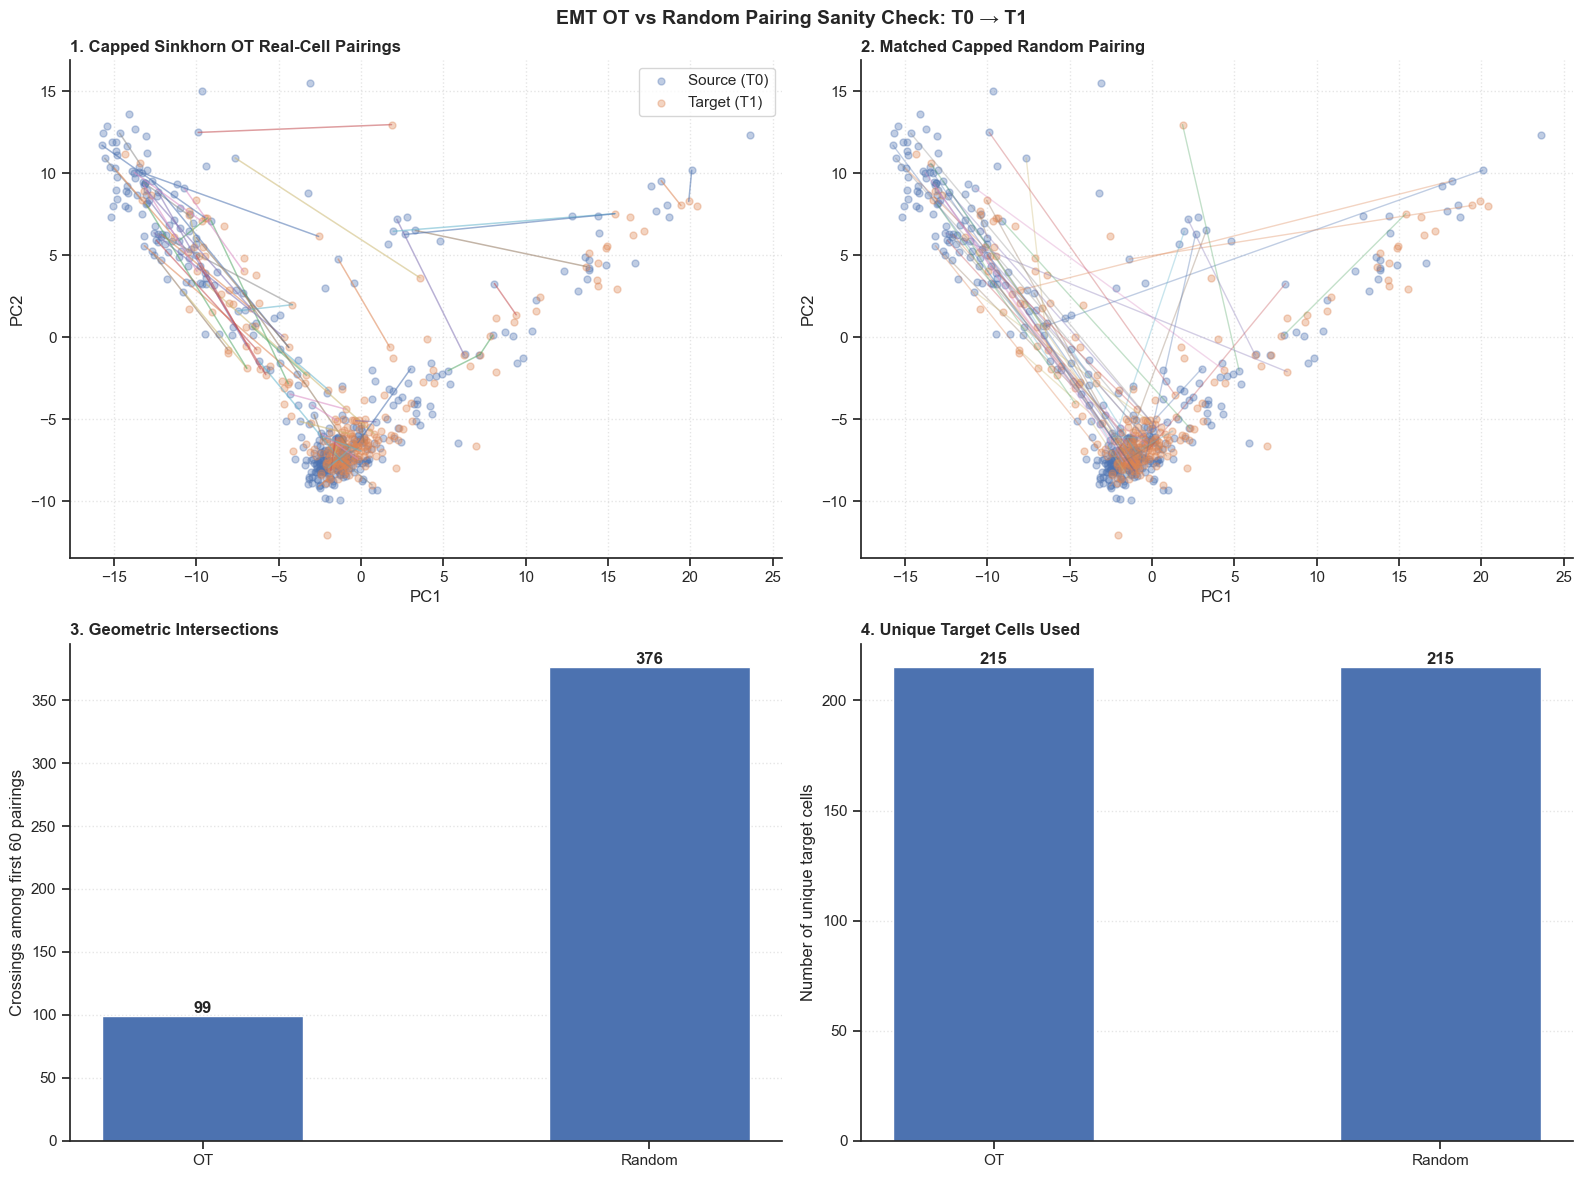


MATCHED CAPPED OT VS RANDOM SANITY REPORT
Transition: T0->T1
Current PCA dimensions: 500
Source cells: 383
Target cells: 240

Pair-count alignment:
OT pair count: 383
Random pair count: 383

Source alignment:
OT and random source PCs identical: True
OT and random source IDs identical: True

Sinkhorn marginal convergence:
Source marginal error: 8.673617379884035e-19
Target marginal error: 3.0144937501058733e-10

2D line diagnostic:
OT crossing count: 99
Random crossing count: 376

Target usage:
OT unique targets used: 215
Random unique targets used: 215
OT maximum target reuse: 2
Random maximum target reuse: 2
OT unused target cells: 25
Random unused target cells: 25

Cap checks:
OT target cap: 2
Random target cap: 2
OT pairings respect cap: True
Random pairings respect cap: True

Leakage checks:
T7 present in preprocessing/PCA cohort: False
T7 used in OT: False
T7 used in random pairing: False

✔ OT and random pairings use the same 383 T0 source cells
✔ OT and random use the same targ

In [27]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.clf()
plt.close("all")

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# =========================================================
# 1. CHOOSE TRANSITION
# =========================================================

stage_0 = "T0"
stage_1 = "T1"
transition_key = f"{stage_0}->{stage_1}"

print(f"-> Checking exact Step 5 / Step 5B pairings: {transition_key}")

# =========================================================
# 2. LOAD EXACT STORED OT + RANDOM MAPPINGS
# =========================================================

ot_info = ot_transition_info[transition_key]
random_info = random_pairing_info[transition_key]

L_t0 = np.asarray(ot_info["source"], dtype=np.float64)
L_t1 = np.asarray(ot_info["target_population"], dtype=np.float64)

ot_pair_indices = np.asarray(ot_info["target_indices"], dtype=int)
rand_pair_indices = np.asarray(random_info["target_indices"], dtype=int)

gamma = np.asarray(ot_info["gamma"], dtype=np.float64)

source_error = ot_info["source_error"]
target_error = ot_info["target_error"]

ot_target_usage = np.asarray(ot_info["target_usage"], dtype=int)
rand_target_usage = np.asarray(random_info["target_usage"], dtype=int)

L_t0_pc = L_t0[:, :2]
L_t1_pc = L_t1[:, :2]

print("OT pair count:", len(ot_pair_indices))
print("Random pair count:", len(rand_pair_indices))

# =========================================================
# 3. VERIFY MATCHED SOURCE / TARGET SETUP
# =========================================================

assert np.allclose(
    ot_info["source"],
    random_info["source"]
)

assert np.array_equal(
    ot_info["source_ids"],
    random_info["source_ids"]
)

assert np.allclose(
    ot_info["target_population"],
    random_info["target_population"]
)

assert target_cap == random_target_cap

# =========================================================
# 4. LINE-CROSSING FUNCTIONS
# =========================================================

def ccw(A, B, C):
    return (C[1] - A[1]) * (B[0] - A[0]) > (B[1] - A[1]) * (C[0] - A[0])

def do_lines_intersect(p1, q1, p2, q2):
    return ccw(p1, p2, q2) != ccw(q1, p2, q2) and ccw(p1, q1, p2) != ccw(p1, q1, q2)

def calculate_total_intersections(src_coords, tgt_coords, matching_indices, max_check=60):
    n_lines = min(len(src_coords), max_check)
    intersections = 0

    for i in range(n_lines):
        p1 = src_coords[i]
        q1 = tgt_coords[matching_indices[i]]

        for j in range(i + 1, n_lines):
            p2 = src_coords[j]
            q2 = tgt_coords[matching_indices[j]]

            if do_lines_intersect(p1, q1, p2, q2):
                intersections += 1

    return intersections

max_sample = 60

ot_crossings = calculate_total_intersections(
    L_t0_pc,
    L_t1_pc,
    ot_pair_indices,
    max_check=max_sample
)

rand_crossings = calculate_total_intersections(
    L_t0_pc,
    L_t1_pc,
    rand_pair_indices,
    max_check=max_sample
)

# =========================================================
# 5. TARGET-USAGE DIAGNOSTICS
# =========================================================

ot_unique_targets = np.sum(ot_target_usage > 0)
rand_unique_targets = np.sum(rand_target_usage > 0)

ot_max_reuse = ot_target_usage.max()
rand_max_reuse = rand_target_usage.max()

ot_unused_targets = np.sum(ot_target_usage == 0)
rand_unused_targets = np.sum(rand_target_usage == 0)

# =========================================================
# 6. FOUR-PANEL DASHBOARD
# =========================================================

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
ax1, ax2, ax3, ax4 = axs.flatten()

# ---------------------------------------------------------
# PANEL 1 — EXACT OT PAIRINGS
# ---------------------------------------------------------

ax1.scatter(
    L_t0_pc[:, 0],
    L_t0_pc[:, 1],
    alpha=0.35,
    s=25,
    label=f"Source ({stage_0})"
)

ax1.scatter(
    L_t1_pc[:, 0],
    L_t1_pc[:, 1],
    alpha=0.35,
    s=25,
    label=f"Target ({stage_1})"
)

for i in range(min(max_sample, len(L_t0_pc))):
    src = L_t0_pc[i]
    tgt = L_t1_pc[ot_pair_indices[i]]

    ax1.plot(
        [src[0], tgt[0]],
        [src[1], tgt[1]],
        alpha=0.55,
        linewidth=1.1
    )

ax1.set_title(
    "1. Capped Sinkhorn OT Real-Cell Pairings",
    loc="left",
    fontweight="bold"
)

ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend()

# ---------------------------------------------------------
# PANEL 2 — EXACT RANDOM PAIRINGS
# ---------------------------------------------------------

ax2.scatter(
    L_t0_pc[:, 0],
    L_t0_pc[:, 1],
    alpha=0.35,
    s=25
)

ax2.scatter(
    L_t1_pc[:, 0],
    L_t1_pc[:, 1],
    alpha=0.35,
    s=25
)

for i in range(min(max_sample, len(L_t0_pc))):
    src = L_t0_pc[i]
    tgt = L_t1_pc[rand_pair_indices[i]]

    ax2.plot(
        [src[0], tgt[0]],
        [src[1], tgt[1]],
        alpha=0.35,
        linewidth=1.0
    )

ax2.set_title(
    "2. Matched Capped Random Pairing",
    loc="left",
    fontweight="bold"
)

ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.grid(True, linestyle=":", alpha=0.5)

# ---------------------------------------------------------
# PANEL 3 — GEOMETRIC INTERSECTIONS
# ---------------------------------------------------------

bars_cross = ax3.bar(
    ["OT", "Random"],
    [ot_crossings, rand_crossings],
    width=0.45
)

ax3.set_title(
    "3. Geometric Intersections",
    loc="left",
    fontweight="bold"
)

ax3.set_ylabel(
    f"Crossings among first {max_sample} pairings"
)

ax3.grid(axis="y", linestyle=":", alpha=0.5)

for bar, value in zip(
    bars_cross,
    [ot_crossings, rand_crossings]
):
    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# ---------------------------------------------------------
# PANEL 4 — UNIQUE TARGET USAGE
# ---------------------------------------------------------

bars_usage = ax4.bar(
    ["OT", "Random"],
    [ot_unique_targets, rand_unique_targets],
    width=0.45
)

ax4.set_title(
    "4. Unique Target Cells Used",
    loc="left",
    fontweight="bold"
)

ax4.set_ylabel("Number of unique target cells")
ax4.grid(axis="y", linestyle=":", alpha=0.5)

for bar, value in zip(
    bars_usage,
    [ot_unique_targets, rand_unique_targets]
):
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# =========================================================
# 7. FINAL FIGURE
# =========================================================

plt.suptitle(
    f"EMT OT vs Random Pairing Sanity Check: {stage_0} → {stage_1}",
    fontweight="bold",
    fontsize=14
)

sns.despine(trim=False)
plt.tight_layout()
plt.show()

# =========================================================
# 8. NUMERIC REPORT
# =========================================================

print("\n" + "=" * 75)
print("MATCHED CAPPED OT VS RANDOM SANITY REPORT")
print("=" * 75)

print("Transition:", transition_key)
print("Current PCA dimensions:", L_t0.shape[1])
print("Source cells:", len(L_t0))
print("Target cells:", len(L_t1))

print("\nPair-count alignment:")
print("OT pair count:", len(ot_pair_indices))
print("Random pair count:", len(rand_pair_indices))

print("\nSource alignment:")
print(
    "OT and random source PCs identical:",
    np.allclose(
        ot_info["source"],
        random_info["source"]
    )
)

print(
    "OT and random source IDs identical:",
    np.array_equal(
        ot_info["source_ids"],
        random_info["source_ids"]
    )
)

print("\nSinkhorn marginal convergence:")
print("Source marginal error:", source_error)
print("Target marginal error:", target_error)

print("\n2D line diagnostic:")
print("OT crossing count:", ot_crossings)
print("Random crossing count:", rand_crossings)

print("\nTarget usage:")
print("OT unique targets used:", ot_unique_targets)
print("Random unique targets used:", rand_unique_targets)

print("OT maximum target reuse:", ot_max_reuse)
print("Random maximum target reuse:", rand_max_reuse)

print("OT unused target cells:", ot_unused_targets)
print("Random unused target cells:", rand_unused_targets)

print("\nCap checks:")
print("OT target cap:", target_cap)
print("Random target cap:", random_target_cap)

print(
    "OT pairings respect cap:",
    ot_max_reuse <= target_cap
)

print(
    "Random pairings respect cap:",
    rand_max_reuse <= random_target_cap
)

print("\nLeakage checks:")

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "T7 used in OT:",
    any(
        "T7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "T7 used in random pairing:",
    any(
        "T7" in transition
        for transition in random_pairing_info.keys()
    )
)

# =========================================================
# 9. ASSERTIONS
# =========================================================

assert len(ot_pair_indices) == 383
assert len(rand_pair_indices) == 383

assert np.allclose(
    ot_info["source"],
    random_info["source"]
)

assert np.array_equal(
    ot_info["source_ids"],
    random_info["source_ids"]
)

assert ot_max_reuse <= target_cap
assert rand_max_reuse <= random_target_cap

assert not any(
    "T7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "T7" in transition
    for transition in random_pairing_info.keys()
)

print("\n✔ OT and random pairings use the same 383 T0 source cells")
print("✔ OT and random use the same target population")
print("✔ OT and random use the same target-use cap")
print("✔ OT lines show the actual real-cell pairings used in training")
print("✔ Random lines show the actual capped-random pairings")
print("✔ OT was computed in the full 500-PC space")
print("✔ PC1/PC2 are used only for visualization")
print("✔ No barycentric synthetic targets are used")
print("✔ T7 remains completely excluded")
print("✔ These plots validate pairing structure, not forecasting performance")

-> Training Ridge Regression (EMT): OT vs Random Pairing...
Ridge alpha: 10.0
Ridge PCA dimensions: 500

Ridge OT X: (1836, 501)
Ridge OT Y: (1836, 500)
Ridge random X: (1836, 501)
Ridge random Y: (1836, 500)
Ridge test X: (77, 501)

OT latent prediction shape: (77, 500)
Random latent prediction shape: (77, 500)
OT biological prediction shape: (77, 2000)
Random biological prediction shape: (77, 2000)


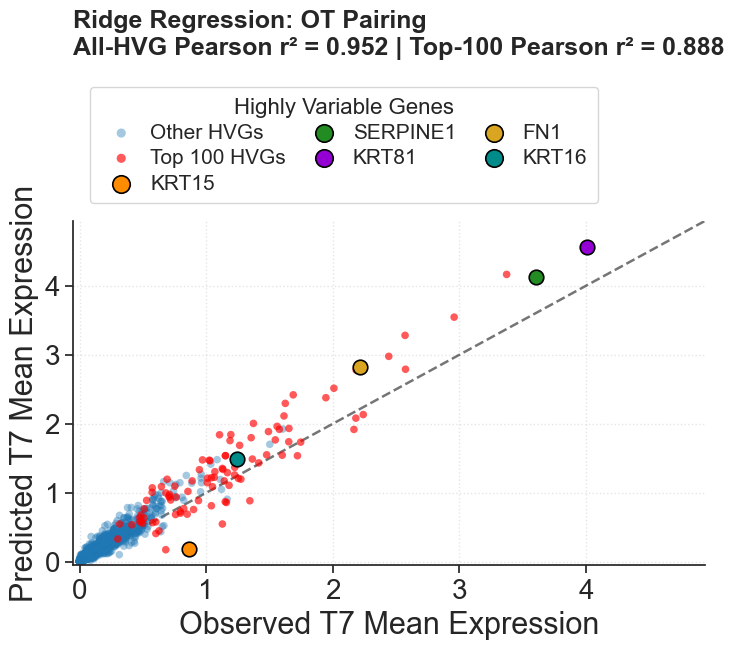

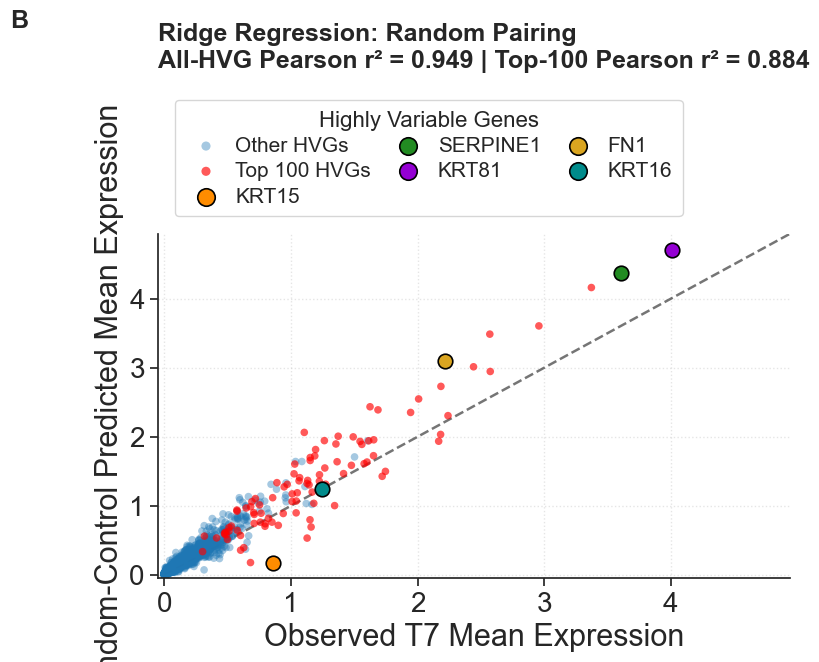


Top-five HVG absolute mean-expression errors — Ridge Regression
Gene                   OT Error     Random Error
KRT15                  0.671242         0.684384
SERPINE1               0.517905         0.764161
KRT81                  0.556957         0.697898
FN1                    0.606126         0.875877
KRT16                  0.239181         0.002143
Average                0.518282         0.604893

T7 FORECAST REPORT: RIDGE REGRESSION
PCA dimensions: 500

Primary metric:
Pearson r² — All HVGs | OT: 0.9516
Pearson r² — All HVGs | Random: 0.9489
Pearson r² — Top 100 HVGs | OT: 0.8878
Pearson r² — Top 100 HVGs | Random: 0.8838

Secondary metrics:
Endpoint R² | OT: 0.8891
Endpoint R² | Random: 0.8733
Wasserstein-2 | OT: 18.0658
Wasserstein-2 | Random: 18.6859

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.04529551997050379
Random mean gene variance: 0.02748176557554304
True T7 mean distance from center: 17.618517495052668
OT mean

In [26]:
from sklearn.linear_model import Ridge
import numpy as np

print("-> Training Ridge Regression (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same hyperparameter as primary fibroblast dataset
# =========================================================

ridge_alpha = 10.0
ridge_pc_count = ridge_data["pc_count"]

print("Ridge alpha:", ridge_alpha)
print("Ridge PCA dimensions:", ridge_pc_count)

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_ridge_ot = ridge_data["X_train_ot"]
Y_ridge_ot = ridge_data["Y_train_ot"]

X_ridge_random = ridge_data["X_train_random"]
Y_ridge_random = ridge_data["Y_train_random"]

X_ridge_test = ridge_data["X_test"]

print("\nRidge OT X:", X_ridge_ot.shape)
print("Ridge OT Y:", Y_ridge_ot.shape)
print("Ridge random X:", X_ridge_random.shape)
print("Ridge random Y:", Y_ridge_random.shape)
print("Ridge test X:", X_ridge_test.shape)

# =========================================================
# 3. OT-PAIRED RIDGE
# =========================================================

ridge_ot = Ridge(alpha=ridge_alpha)
ridge_ot.fit(X_ridge_ot, Y_ridge_ot)

# =========================================================
# 4. RANDOM-PAIRED RIDGE
# =========================================================

ridge_random = Ridge(alpha=ridge_alpha)
ridge_random.fit(X_ridge_random, Y_ridge_random)

# =========================================================
# 5. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

pred_latent_ridge_ot = ridge_ot.predict(X_ridge_test)
pred_latent_ridge_random = ridge_random.predict(X_ridge_test)

print("\nOT latent prediction shape:", pred_latent_ridge_ot.shape)
print("Random latent prediction shape:", pred_latent_ridge_random.shape)

# =========================================================
# 6. INVERSE PCA + INVERSE Z-STANDARDIZATION
# =========================================================

pred_genes_ridge_ot = to_true_biological_gene_space(pred_latent_ridge_ot, ridge_pc_count)
pred_genes_ridge_random = to_true_biological_gene_space(pred_latent_ridge_random, ridge_pc_count)

print("OT biological prediction shape:", pred_genes_ridge_ot.shape)
print("Random biological prediction shape:", pred_genes_ridge_random.shape)

# =========================================================
# 7. FINAL ENDPOINT EVALUATION
#
# Displays the same four endpoint figures as before:
# A = OT All HVGs
# B = Random All HVGs
# C = OT Top 100 HVGs
# D = Random Top 100 HVGs
#
# Individual model figures are not automatically saved.
# =========================================================

evaluate_endpoint_model(
    pred_genes_ridge_ot,
    pred_genes_ridge_random,
    "Ridge Regression",
    ridge_pc_count
)

# =========================================================
# 8. RETRIEVE RIDGE RESULTS
# =========================================================

ridge_results = model_results["Ridge Regression"]

# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("RIDGE REGRESSION EMT FINAL SUMMARY")
print("=" * 80)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", ridge_pc_count)
print("Total model input features:", X_ridge_ot.shape[1])
print("Predicted PCA dimensions:", Y_ridge_ot.shape[1])
print("Direct forecast dT:", np.unique(X_ridge_test[:, -1]))
print("Ridge alpha:", ridge_alpha)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_ridge_ot.shape[0])
print("Random training rows:", X_ridge_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_ridge_ot, X_ridge_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_ridge_ot, Y_ridge_random)
)

print("\nRidge endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(ridge_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(ridge_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(ridge_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(ridge_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(ridge_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(ridge_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(ridge_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(ridge_results["Random_W2"], 4)
)

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    ridge_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    ridge_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    ridge_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    ridge_results["Random_Mean_Distance_From_Center"]
)

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 10. FINAL ASSERTIONS
# =========================================================

assert ridge_alpha == 10.0
assert ridge_pc_count == 500

assert X_ridge_ot.shape == (1836, 501)
assert Y_ridge_ot.shape == (1836, 500)
assert X_ridge_random.shape == (1836, 501)
assert Y_ridge_random.shape == (1836, 500)
assert X_ridge_test.shape == (77, 501)

assert pred_latent_ridge_ot.shape == (77, ridge_pc_count)
assert pred_latent_ridge_random.shape == (77, ridge_pc_count)

assert pred_genes_ridge_ot.shape == (77, 2000)
assert pred_genes_ridge_random.shape == (77, 2000)

assert np.isfinite(pred_latent_ridge_ot).all()
assert np.isfinite(pred_latent_ridge_random).all()

assert np.isfinite(pred_genes_ridge_ot).all()
assert np.isfinite(pred_genes_ridge_random).all()

assert X_ridge_ot.shape == X_ridge_random.shape
assert Y_ridge_ot.shape == Y_ridge_random.shape

assert np.allclose(X_ridge_ot, X_ridge_random)
assert not np.allclose(Y_ridge_ot, Y_ridge_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())

assert not any(
    "T7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "T7" in transition
    for transition in random_pairing_info.keys()
)

assert np.allclose(X_ridge_test[:, -1], 8.0)

# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ Ridge EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ Ridge uses its selected 500-dimensional PCA state")
print("✔ Ridge alpha = 10.0, matching the primary fibroblast benchmark")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual Ridge figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

-> Training MLP (EMT): OT vs Random Pairing...
MLP PCA dimensions: 500
Input width: 501
Output width: 500

MLP OT X: (1836, 501)
MLP OT Y: (1836, 500)
MLP random X: (1836, 501)
MLP random Y: (1836, 500)
MLP test X: (77, 501)

Training OT MLP...
Epoch  20/120 | MSE = 2.563554
Epoch  40/120 | MSE = 2.434167
Epoch  60/120 | MSE = 2.384582
Epoch  80/120 | MSE = 2.343845
Epoch 100/120 | MSE = 2.320578
Epoch 120/120 | MSE = 2.301210

Training Random-Pairing MLP...
Epoch  20/120 | MSE = 2.457660
Epoch  40/120 | MSE = 2.366621
Epoch  60/120 | MSE = 2.314521
Epoch  80/120 | MSE = 2.269065
Epoch 100/120 | MSE = 2.235865
Epoch 120/120 | MSE = 2.204535

Final OT training MSE: 2.30121
Final random training MSE: 2.204535

OT latent prediction shape: (77, 500)
Random latent prediction shape: (77, 500)
OT biological prediction shape: (77, 2000)
Random biological prediction shape: (77, 2000)


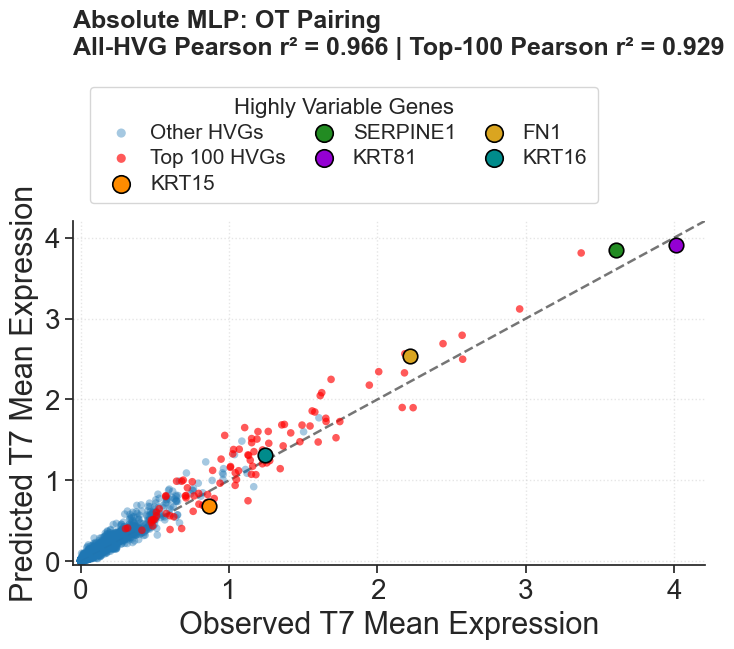

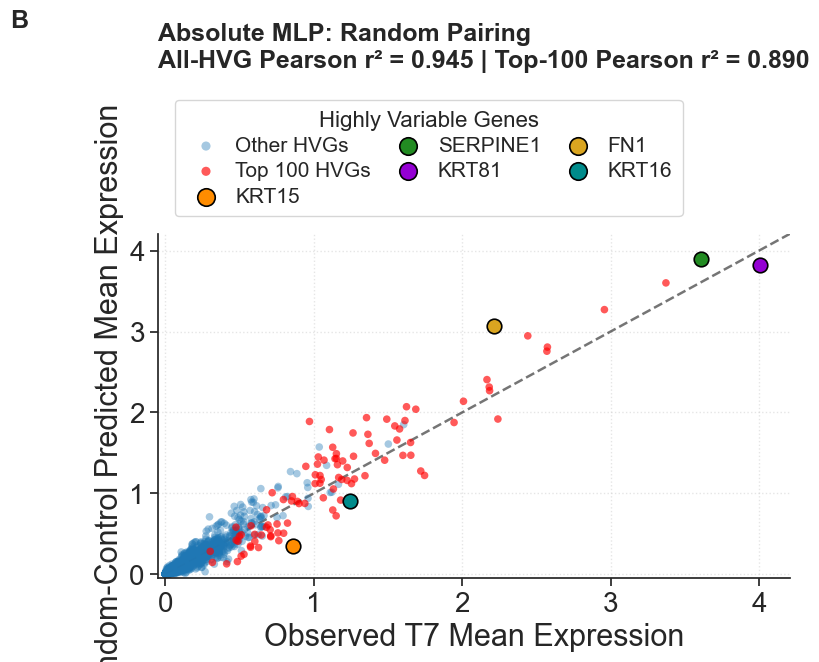


Top-five HVG absolute mean-expression errors — Absolute MLP
Gene                   OT Error     Random Error
KRT15                  0.185558         0.511445
SERPINE1               0.243963         0.285319
KRT81                  0.095751         0.185140
FN1                    0.319706         0.849771
KRT16                  0.067304         0.339144
Average                0.182457         0.434164

T7 FORECAST REPORT: ABSOLUTE MLP
PCA dimensions: 500

Primary metric:
Pearson r² — All HVGs | OT: 0.9661
Pearson r² — All HVGs | Random: 0.9446
Pearson r² — Top 100 HVGs | OT: 0.9292
Pearson r² — Top 100 HVGs | Random: 0.8896

Secondary metrics:
Endpoint R² | OT: 0.9457
Endpoint R² | Random: 0.9286
Wasserstein-2 | OT: 17.0055
Wasserstein-2 | Random: 17.5547

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.02605162533782344
Random mean gene variance: 0.01166260427354565
True T7 mean distance from center: 17.618517495052668
OT mean distanc

In [28]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training MLP (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same architecture/hyperparameters as fibroblast dataset
# =========================================================

mlp_pc_count = mlp_data["pc_count"]

hidden_width = 128
dropout = 0.2
learning_rate = 0.003
epochs = 120
seed = 42

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_mlp_ot = mlp_data["X_train_ot"]
Y_mlp_ot = mlp_data["Y_train_ot"]

X_mlp_random = mlp_data["X_train_random"]
Y_mlp_random = mlp_data["Y_train_random"]

X_mlp_test = mlp_data["X_test"]

input_dim = X_mlp_ot.shape[1]
output_dim = Y_mlp_ot.shape[1]

print("MLP PCA dimensions:", mlp_pc_count)
print("Input width:", input_dim)
print("Output width:", output_dim)

print("\nMLP OT X:", X_mlp_ot.shape)
print("MLP OT Y:", Y_mlp_ot.shape)
print("MLP random X:", X_mlp_random.shape)
print("MLP random Y:", Y_mlp_random.shape)
print("MLP test X:", X_mlp_test.shape)

# =========================================================
# 3. MODEL
# =========================================================

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_width),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_width, hidden_width),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_width, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# =========================================================
# 4. TRAINING FUNCTION
# =========================================================

def train_mlp(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = MLP()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    X_train = torch.tensor(np.asarray(X_train), dtype=torch.float32)
    Y_train = torch.tensor(np.asarray(Y_train), dtype=torch.float32)

    model.train()
    final_loss = None

    for epoch in range(epochs):
        optimizer.zero_grad()

        pred = model(X_train)
        loss = loss_fn(pred, Y_train)

        loss.backward()
        optimizer.step()

        final_loss = loss.item()

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1:3d}/{epochs} | MSE = {final_loss:.6f}")

    return model, final_loss

# =========================================================
# 5. TRAIN OT MODEL
# =========================================================

print("\nTraining OT MLP...")

mlp_ot, final_loss_ot = train_mlp(
    X_mlp_ot,
    Y_mlp_ot,
    seed=seed
)

# =========================================================
# 6. TRAIN RANDOM MODEL
# =========================================================

print("\nTraining Random-Pairing MLP...")

mlp_random, final_loss_random = train_mlp(
    X_mlp_random,
    Y_mlp_random,
    seed=seed
)

print("\nFinal OT training MSE:", round(final_loss_ot, 6))
print("Final random training MSE:", round(final_loss_random, 6))

# =========================================================
# 7. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

mlp_ot.eval()
mlp_random.eval()

X_mlp_test_tensor = torch.tensor(
    np.asarray(X_mlp_test),
    dtype=torch.float32
)

with torch.no_grad():
    pred_latent_mlp_ot = mlp_ot(X_mlp_test_tensor).cpu().numpy()
    pred_latent_mlp_random = mlp_random(X_mlp_test_tensor).cpu().numpy()

print("\nOT latent prediction shape:", pred_latent_mlp_ot.shape)
print("Random latent prediction shape:", pred_latent_mlp_random.shape)

# =========================================================
# 8. INVERSE PCA + INVERSE Z-STANDARDIZATION
# =========================================================

pred_genes_mlp_ot = to_true_biological_gene_space(
    pred_latent_mlp_ot,
    mlp_pc_count
)

pred_genes_mlp_random = to_true_biological_gene_space(
    pred_latent_mlp_random,
    mlp_pc_count
)

print("OT biological prediction shape:", pred_genes_mlp_ot.shape)
print("Random biological prediction shape:", pred_genes_mlp_random.shape)

# =========================================================
# 9. FINAL ENDPOINT EVALUATION
#
# Displays:
# A = OT All HVGs
# B = Random All HVGs
# C = OT Top 100 HVGs
# D = Random Top 100 HVGs
# =========================================================

evaluate_endpoint_model(
    pred_genes_mlp_ot,
    pred_genes_mlp_random,
    "Absolute MLP",
    mlp_pc_count
)

# =========================================================
# 10. RETRIEVE MLP RESULTS
# =========================================================

mlp_results = model_results["Absolute MLP"]

# =========================================================
# 11. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("ABSOLUTE MLP EMT FINAL SUMMARY")
print("=" * 75)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", mlp_pc_count)
print("Total model input features:", input_dim)
print("Predicted PCA dimensions:", output_dim)
print("Direct forecast dT:", np.unique(X_mlp_test[:, -1]))

print("\nMLP architecture:")
print("Hidden width:", hidden_width)
print("Hidden layers:", 2)
print("Activation: GELU")
print("Dropout:", dropout)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)
print("Seed:", seed)

print("\nFinal training MSE:")
print("OT:", round(final_loss_ot, 6))
print("Random:", round(final_loss_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_mlp_ot.shape[0])
print("Random training rows:", X_mlp_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_mlp_ot, X_mlp_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_mlp_ot, Y_mlp_random)
)

print("\nMLP endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(mlp_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(mlp_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(mlp_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(mlp_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(mlp_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(mlp_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(mlp_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(mlp_results["Random_W2"], 4)
)

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    mlp_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    mlp_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    mlp_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    mlp_results["Random_Mean_Distance_From_Center"]
)

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 12. FINAL ASSERTIONS
# =========================================================

assert mlp_pc_count == 500
assert hidden_width == 128
assert dropout == 0.2
assert learning_rate == 0.003
assert epochs == 120
assert seed == 42

assert X_mlp_ot.shape == (1836, 501)
assert Y_mlp_ot.shape == (1836, 500)
assert X_mlp_random.shape == (1836, 501)
assert Y_mlp_random.shape == (1836, 500)
assert X_mlp_test.shape == (77, 501)

assert pred_latent_mlp_ot.shape == (77, mlp_pc_count)
assert pred_latent_mlp_random.shape == (77, mlp_pc_count)

assert pred_genes_mlp_ot.shape == (77, 2000)
assert pred_genes_mlp_random.shape == (77, 2000)

assert np.isfinite(pred_latent_mlp_ot).all()
assert np.isfinite(pred_latent_mlp_random).all()
assert np.isfinite(pred_genes_mlp_ot).all()
assert np.isfinite(pred_genes_mlp_random).all()

assert X_mlp_ot.shape == X_mlp_random.shape
assert Y_mlp_ot.shape == Y_mlp_random.shape

assert np.allclose(X_mlp_ot, X_mlp_random)
assert not np.allclose(Y_mlp_ot, Y_mlp_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())
assert not any("T7" in transition for transition in ot_transition_info.keys())
assert not any("T7" in transition for transition in random_pairing_info.keys())

assert np.allclose(X_mlp_test[:, -1], 8.0)

# =========================================================
# 13. FINAL STATUS
# =========================================================

print("\n✔ MLP EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ MLP uses its selected 500-dimensional PCA state")
print("✔ 2 x 128 GELU architecture matches fibroblast benchmark")
print("✔ Dropout = 0.2")
print("✔ Adam learning rate = 0.003")
print("✔ 120 training epochs")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual MLP figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

-> Training Random Forest (EMT): OT vs Random Pairing...
Random Forest PCA dimensions: 10
Number of trees: 20
Maximum depth: 4
Max features: 0.5
Random state: 42
n_jobs: 2

RF OT X: (1836, 11)
RF OT Y: (1836, 10)
RF random X: (1836, 11)
RF random Y: (1836, 10)
RF test X: (77, 11)

OT latent prediction shape: (77, 10)
Random latent prediction shape: (77, 10)
OT biological prediction shape: (77, 2000)
Random biological prediction shape: (77, 2000)


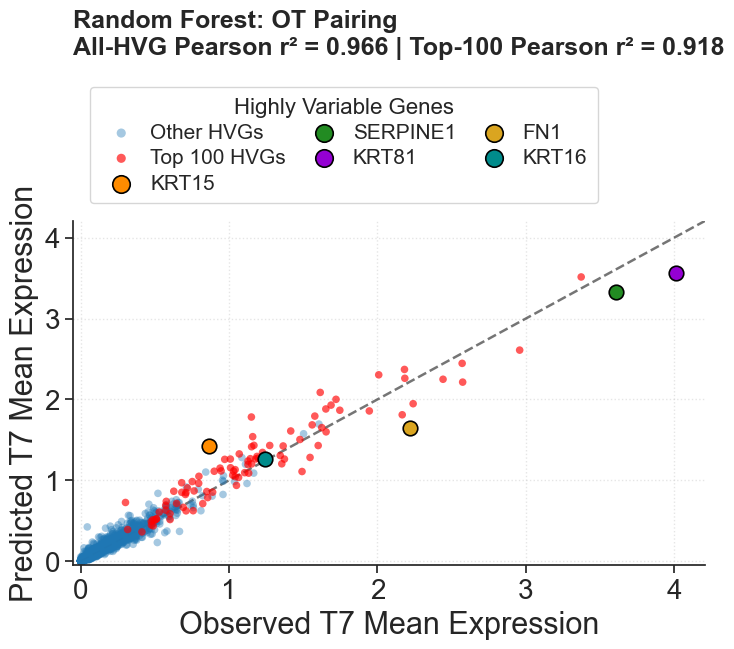

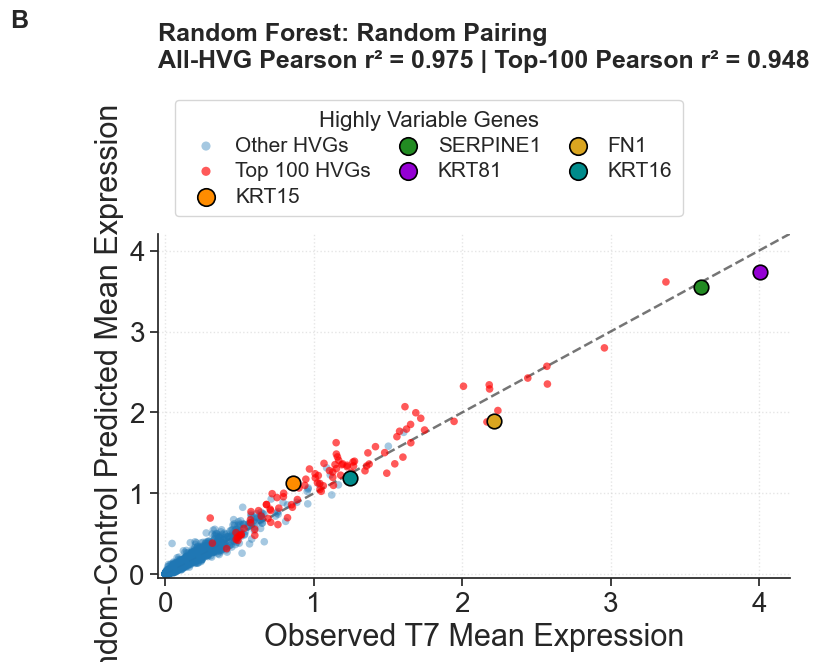


Top-five HVG absolute mean-expression errors — Random Forest
Gene                   OT Error     Random Error
KRT15                  0.562751         0.262977
SERPINE1               0.272862         0.057669
KRT81                  0.445307         0.266660
FN1                    0.565635         0.327339
KRT16                  0.017670         0.049260
Average                0.372845         0.192781

T7 FORECAST REPORT: RANDOM FOREST
PCA dimensions: 10

Primary metric:
Pearson r² — All HVGs | OT: 0.9659
Pearson r² — All HVGs | Random: 0.9745
Pearson r² — Top 100 HVGs | OT: 0.9182
Pearson r² — Top 100 HVGs | Random: 0.9479

Secondary metrics:
Endpoint R² | OT: 0.9635
Endpoint R² | Random: 0.9695
Wasserstein-2 | OT: 16.9836
Wasserstein-2 | Random: 18.147

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.020501971104336367
Random mean gene variance: 0.00011855184766693026
True T7 mean distance from center: 17.618517495052668
OT mean dis

In [30]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np

print("-> Training Random Forest (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same architecture/hyperparameters as fibroblast dataset
# =========================================================

rf_pc_count = rf_data["pc_count"]

rf_n_estimators = 20
rf_max_depth = 4
rf_max_features = 0.5
rf_random_state = 42
rf_n_jobs = 2

print("Random Forest PCA dimensions:", rf_pc_count)
print("Number of trees:", rf_n_estimators)
print("Maximum depth:", rf_max_depth)
print("Max features:", rf_max_features)
print("Random state:", rf_random_state)
print("n_jobs:", rf_n_jobs)

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_rf_ot = rf_data["X_train_ot"]
Y_rf_ot = rf_data["Y_train_ot"]

X_rf_random = rf_data["X_train_random"]
Y_rf_random = rf_data["Y_train_random"]

X_rf_test = rf_data["X_test"]

print("\nRF OT X:", X_rf_ot.shape)
print("RF OT Y:", Y_rf_ot.shape)
print("RF random X:", X_rf_random.shape)
print("RF random Y:", Y_rf_random.shape)
print("RF test X:", X_rf_test.shape)

# =========================================================
# 3. OT-PAIRED RANDOM FOREST
# =========================================================

rf_ot = RandomForestRegressor(
    n_estimators=rf_n_estimators,
    max_depth=rf_max_depth,
    max_features=rf_max_features,
    random_state=rf_random_state,
    n_jobs=rf_n_jobs
)

rf_ot.fit(X_rf_ot, Y_rf_ot)

# =========================================================
# 4. RANDOM-PAIRED RANDOM FOREST
# =========================================================

rf_random = RandomForestRegressor(
    n_estimators=rf_n_estimators,
    max_depth=rf_max_depth,
    max_features=rf_max_features,
    random_state=rf_random_state,
    n_jobs=rf_n_jobs
)

rf_random.fit(X_rf_random, Y_rf_random)

# =========================================================
# 5. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

pred_latent_rf_ot = rf_ot.predict(X_rf_test)
pred_latent_rf_random = rf_random.predict(X_rf_test)

print("\nOT latent prediction shape:", pred_latent_rf_ot.shape)
print("Random latent prediction shape:", pred_latent_rf_random.shape)

# =========================================================
# 6. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# RF predicts only 10 PCs. Step 7 zero-pads PCs 11-500
# before inverse transformation through the common PCA basis.
# =========================================================

pred_genes_rf_ot = to_true_biological_gene_space(
    pred_latent_rf_ot,
    rf_pc_count
)

pred_genes_rf_random = to_true_biological_gene_space(
    pred_latent_rf_random,
    rf_pc_count
)

print("OT biological prediction shape:", pred_genes_rf_ot.shape)
print("Random biological prediction shape:", pred_genes_rf_random.shape)

# =========================================================
# 7. FINAL ENDPOINT EVALUATION
#
# Displays:
# A = OT All HVGs
# B = Random All HVGs
# C = OT Top 100 HVGs
# D = Random Top 100 HVGs
# =========================================================

evaluate_endpoint_model(
    pred_genes_rf_ot,
    pred_genes_rf_random,
    "Random Forest",
    rf_pc_count
)

# =========================================================
# 8. RETRIEVE RANDOM FOREST RESULTS
# =========================================================

rf_results = model_results["Random Forest"]

# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("RANDOM FOREST EMT FINAL SUMMARY")
print("=" * 80)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", rf_pc_count)
print("Total model input features:", X_rf_ot.shape[1])
print("Predicted PCA dimensions:", Y_rf_ot.shape[1])
print("Direct forecast dT:", np.unique(X_rf_test[:, -1]))

print("\nModel settings:")
print("Number of trees:", rf_n_estimators)
print("Maximum depth:", rf_max_depth)
print("Max features:", rf_max_features)
print("Random state:", rf_random_state)
print("n_jobs:", rf_n_jobs)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_rf_ot.shape[0])
print("Random training rows:", X_rf_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_rf_ot, X_rf_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_rf_ot, Y_rf_random)
)

# =========================================================
# 10. RANDOM FOREST PERFORMANCE
# =========================================================

print("\nRandom Forest endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(rf_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(rf_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(rf_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(rf_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(rf_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(rf_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(rf_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(rf_results["Random_W2"], 4)
)

# =========================================================
# 11. CELL-DIVERSITY DIAGNOSTICS
# =========================================================

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    rf_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    rf_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    rf_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    rf_results["Random_Mean_Distance_From_Center"]
)

# =========================================================
# 12. T0 PERSISTENCE BASELINE
# =========================================================

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

# =========================================================
# 13. LEAKAGE CHECKS
# =========================================================

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 14. FINAL ASSERTIONS
# =========================================================

assert rf_pc_count == 10
assert rf_n_estimators == 20
assert rf_max_depth == 4
assert rf_max_features == 0.5
assert rf_random_state == 42
assert rf_n_jobs == 2

assert X_rf_ot.shape == (1836, 11)
assert Y_rf_ot.shape == (1836, 10)
assert X_rf_random.shape == (1836, 11)
assert Y_rf_random.shape == (1836, 10)
assert X_rf_test.shape == (77, 11)

assert pred_latent_rf_ot.shape == (77, rf_pc_count)
assert pred_latent_rf_random.shape == (77, rf_pc_count)

assert pred_genes_rf_ot.shape == (77, 2000)
assert pred_genes_rf_random.shape == (77, 2000)

assert np.isfinite(pred_latent_rf_ot).all()
assert np.isfinite(pred_latent_rf_random).all()

assert np.isfinite(pred_genes_rf_ot).all()
assert np.isfinite(pred_genes_rf_random).all()

assert X_rf_ot.shape == X_rf_random.shape
assert Y_rf_ot.shape == Y_rf_random.shape

assert np.allclose(X_rf_ot, X_rf_random)
assert not np.allclose(Y_rf_ot, Y_rf_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())

assert not any(
    "T7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "T7" in transition
    for transition in random_pairing_info.keys()
)

assert np.allclose(X_rf_test[:, -1], 8.0)

# =========================================================
# 15. FINAL STATUS
# =========================================================

print("\n✔ Random Forest EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ Random Forest uses its selected 10-dimensional PCA state")
print("✔ 20 trees match fibroblast benchmark")
print("✔ Maximum depth = 4")
print("✔ max_features = 0.5")
print("✔ random_state = 42")
print("✔ n_jobs = 2")
print("✔ 10-PC predictions zero-padded to common 500-PC basis before inverse PCA")
print("✔ OT and random Random Forest models trained separately")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual Random Forest figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

-> Training XGBoost (EMT): OT vs Random Pairing...
XGBoost PCA dimensions: 500
Number of trees: 30
Maximum depth: 3
Learning rate: 0.05
Subsample: 0.8
Column sample by tree: 0.8
Tree method: hist
Random state: 42

XGBoost OT X: (1836, 501)
XGBoost OT Y: (1836, 500)
XGBoost random X: (1836, 501)
XGBoost random Y: (1836, 500)
XGBoost test X: (77, 501)

-> Fitting OT-paired XGBoost...
✔ OT-paired XGBoost finished

-> Fitting capped-random XGBoost...
✔ Random-paired XGBoost finished

OT latent prediction shape: (77, 500)
Random latent prediction shape: (77, 500)
OT biological prediction shape: (77, 2000)
Random biological prediction shape: (77, 2000)
Saved: publication_emt_xgboost_OT_combined_HVGs.png


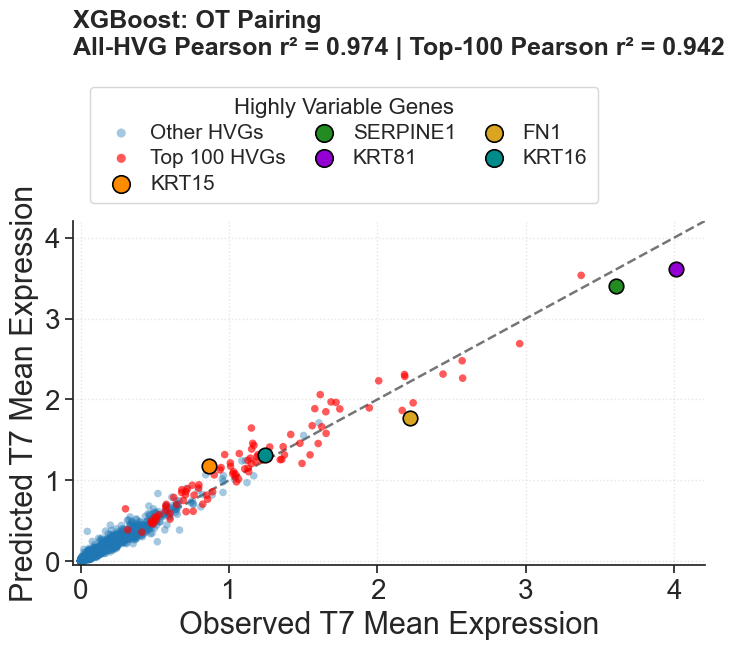

Saved: publication_emt_xgboost_random_combined_HVGs.png


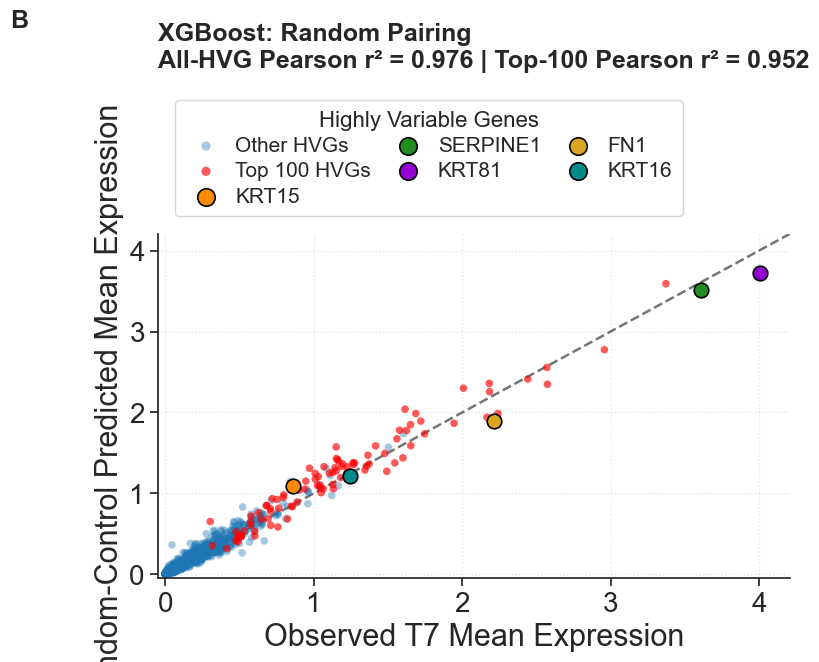


Top-five HVG absolute mean-expression errors — XGBoost
Gene                   OT Error     Random Error
KRT15                  0.317243         0.229368
SERPINE1               0.208561         0.099525
KRT81                  0.398901         0.289942
FN1                    0.446885         0.326894
KRT16                  0.074265         0.031266
Average                0.289171         0.195399

T7 FORECAST REPORT: XGBOOST
PCA dimensions: 500

Primary metric:
Pearson r² — All HVGs | OT: 0.9737
Pearson r² — All HVGs | Random: 0.9761
Pearson r² — Top 100 HVGs | OT: 0.9419
Pearson r² — Top 100 HVGs | Random: 0.9517

Secondary metrics:
Endpoint R² | OT: 0.9718
Endpoint R² | Random: 0.9728
Wasserstein-2 | OT: 16.8709
Wasserstein-2 | Random: 18.0613

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.01608336658237043
Random mean gene variance: 0.0007274344567257427
True T7 mean distance from center: 17.618517495052668
OT mean distance from c

In [31]:
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
import numpy as np

print("-> Training XGBoost (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same architecture/hyperparameters as fibroblast dataset
# =========================================================

xgb_pc_count = xgb_data["pc_count"]

xgb_n_estimators = 30
xgb_max_depth = 3
xgb_learning_rate = 0.05
xgb_subsample = 0.8
xgb_colsample_bytree = 0.8
xgb_random_state = 42
xgb_tree_method = "hist"

print("XGBoost PCA dimensions:", xgb_pc_count)
print("Number of trees:", xgb_n_estimators)
print("Maximum depth:", xgb_max_depth)
print("Learning rate:", xgb_learning_rate)
print("Subsample:", xgb_subsample)
print("Column sample by tree:", xgb_colsample_bytree)
print("Tree method:", xgb_tree_method)
print("Random state:", xgb_random_state)

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_xgb_ot = xgb_data["X_train_ot"]
Y_xgb_ot = xgb_data["Y_train_ot"]

X_xgb_random = xgb_data["X_train_random"]
Y_xgb_random = xgb_data["Y_train_random"]

X_xgb_test = xgb_data["X_test"]

print("\nXGBoost OT X:", X_xgb_ot.shape)
print("XGBoost OT Y:", Y_xgb_ot.shape)
print("XGBoost random X:", X_xgb_random.shape)
print("XGBoost random Y:", Y_xgb_random.shape)
print("XGBoost test X:", X_xgb_test.shape)

# =========================================================
# 3. XGBOOST MODEL FACTORY
# =========================================================

def make_xgb_model():
    return MultiOutputRegressor(
        XGBRegressor(
            n_estimators=xgb_n_estimators,
            max_depth=xgb_max_depth,
            learning_rate=xgb_learning_rate,
            subsample=xgb_subsample,
            colsample_bytree=xgb_colsample_bytree,
            tree_method=xgb_tree_method,
            random_state=xgb_random_state,
            n_jobs=1,
            verbosity=0
        ),
        n_jobs=-1
    )

# =========================================================
# 4. OT-PAIRED XGBOOST
# =========================================================

print("\n-> Fitting OT-paired XGBoost...")

xgb_ot = make_xgb_model()
xgb_ot.fit(X_xgb_ot, Y_xgb_ot)

print("✔ OT-paired XGBoost finished")

# =========================================================
# 5. RANDOM-PAIRED XGBOOST
# =========================================================

print("\n-> Fitting capped-random XGBoost...")

xgb_random = make_xgb_model()
xgb_random.fit(X_xgb_random, Y_xgb_random)

print("✔ Random-paired XGBoost finished")

# =========================================================
# 6. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

pred_latent_xgb_ot = xgb_ot.predict(X_xgb_test)
pred_latent_xgb_random = xgb_random.predict(X_xgb_test)

print("\nOT latent prediction shape:", pred_latent_xgb_ot.shape)
print("Random latent prediction shape:", pred_latent_xgb_random.shape)

# =========================================================
# 7. INVERSE PCA + INVERSE Z-STANDARDIZATION
# =========================================================

pred_genes_xgb_ot = to_true_biological_gene_space(
    pred_latent_xgb_ot,
    xgb_pc_count
)

pred_genes_xgb_random = to_true_biological_gene_space(
    pred_latent_xgb_random,
    xgb_pc_count
)

print("OT biological prediction shape:", pred_genes_xgb_ot.shape)
print("Random biological prediction shape:", pred_genes_xgb_random.shape)

# =========================================================
# 8. FINAL ENDPOINT EVALUATION
#
# Displays:
# A = OT All HVGs
# B = Random All HVGs
# C = OT Top 100 HVGs
# D = Random Top 100 HVGs
# =========================================================

evaluate_endpoint_model(
    pred_genes_xgb_ot,
    pred_genes_xgb_random,
    "XGBoost",
    xgb_pc_count
)

# =========================================================
# 9. RETRIEVE XGBOOST RESULTS
# =========================================================

xgb_results = model_results["XGBoost"]

# =========================================================
# 10. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("XGBOOST EMT FINAL SUMMARY")
print("=" * 80)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", xgb_pc_count)
print("Total model input features:", X_xgb_ot.shape[1])
print("Predicted PCA dimensions:", Y_xgb_ot.shape[1])
print("Direct forecast dT:", np.unique(X_xgb_test[:, -1]))

print("\nModel settings:")
print("Number of trees:", xgb_n_estimators)
print("Maximum depth:", xgb_max_depth)
print("Learning rate:", xgb_learning_rate)
print("Subsample:", xgb_subsample)
print("Column sample by tree:", xgb_colsample_bytree)
print("Tree method:", xgb_tree_method)
print("Random state:", xgb_random_state)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_xgb_ot.shape[0])
print("Random training rows:", X_xgb_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_xgb_ot, X_xgb_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_xgb_ot, Y_xgb_random)
)

# =========================================================
# 11. XGBOOST PERFORMANCE
# =========================================================

print("\nXGBoost endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(xgb_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(xgb_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(xgb_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(xgb_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(xgb_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(xgb_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(xgb_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(xgb_results["Random_W2"], 4)
)

# =========================================================
# 12. CELL-DIVERSITY DIAGNOSTICS
# =========================================================

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    xgb_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    xgb_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    xgb_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    xgb_results["Random_Mean_Distance_From_Center"]
)

# =========================================================
# 13. T0 PERSISTENCE BASELINE
# =========================================================

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

# =========================================================
# 14. LEAKAGE CHECKS
# =========================================================

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 15. FINAL ASSERTIONS
# =========================================================

assert xgb_pc_count == 500
assert xgb_n_estimators == 30
assert xgb_max_depth == 3
assert xgb_learning_rate == 0.05
assert xgb_subsample == 0.8
assert xgb_colsample_bytree == 0.8
assert xgb_random_state == 42
assert xgb_tree_method == "hist"

assert X_xgb_ot.shape == (1836, 501)
assert Y_xgb_ot.shape == (1836, 500)
assert X_xgb_random.shape == (1836, 501)
assert Y_xgb_random.shape == (1836, 500)
assert X_xgb_test.shape == (77, 501)

assert pred_latent_xgb_ot.shape == (77, xgb_pc_count)
assert pred_latent_xgb_random.shape == (77, xgb_pc_count)

assert pred_genes_xgb_ot.shape == (77, 2000)
assert pred_genes_xgb_random.shape == (77, 2000)

assert np.isfinite(pred_latent_xgb_ot).all()
assert np.isfinite(pred_latent_xgb_random).all()
assert np.isfinite(pred_genes_xgb_ot).all()
assert np.isfinite(pred_genes_xgb_random).all()

assert X_xgb_ot.shape == X_xgb_random.shape
assert Y_xgb_ot.shape == Y_xgb_random.shape

assert np.allclose(X_xgb_ot, X_xgb_random)
assert not np.allclose(Y_xgb_ot, Y_xgb_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())

assert not any(
    "T7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "T7" in transition
    for transition in random_pairing_info.keys()
)

assert np.allclose(X_xgb_test[:, -1], 8.0)

# =========================================================
# 16. FINAL STATUS
# =========================================================

print("\n✔ XGBoost EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ XGBoost uses its selected 500-dimensional PCA state")
print("✔ 30 trees match fibroblast benchmark")
print("✔ Maximum depth = 3")
print("✔ Learning rate = 0.05")
print("✔ Subsample = 0.8")
print("✔ colsample_bytree = 0.8")
print("✔ Tree method = hist")
print("✔ random_state = 42")
print("✔ OT and random XGBoost models trained separately")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual XGBoost figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

-> Training Time-Conditioned Neural ODE (EMT): OT vs Random Pairing...
PCA dimensions: 50
Hidden dimensions: 128
Hidden layers: 2
Activation: GELU
Output activation: Tanh
Output scale: 2.0
Euler steps: 6
Epochs: 60
Batch size: 512
Learning rate: 0.002
Weight decay: 0.001
Random state: 42

Neural ODE OT X: (1836, 51)
Neural ODE OT Y: (1836, 50)
Neural ODE random X: (1836, 51)
Neural ODE random Y: (1836, 50)
Neural ODE test X: (77, 51)

-> Training Neural ODE on OT-paired targets...
Epoch  10/60 | MSE = 7.413943
Epoch  20/60 | MSE = 6.990567
Epoch  30/60 | MSE = 6.755831
Epoch  40/60 | MSE = 6.598242
Epoch  50/60 | MSE = 6.491645
Epoch  60/60 | MSE = 6.356485

-> Training Neural ODE on capped-random targets...
Epoch  10/60 | MSE = 10.172592
Epoch  20/60 | MSE = 9.755395
Epoch  30/60 | MSE = 9.537607
Epoch  40/60 | MSE = 9.347280
Epoch  50/60 | MSE = 9.131092
Epoch  60/60 | MSE = 9.017908

Final OT training MSE: 6.356485
Final random training MSE: 9.017908

OT latent prediction shape: (77

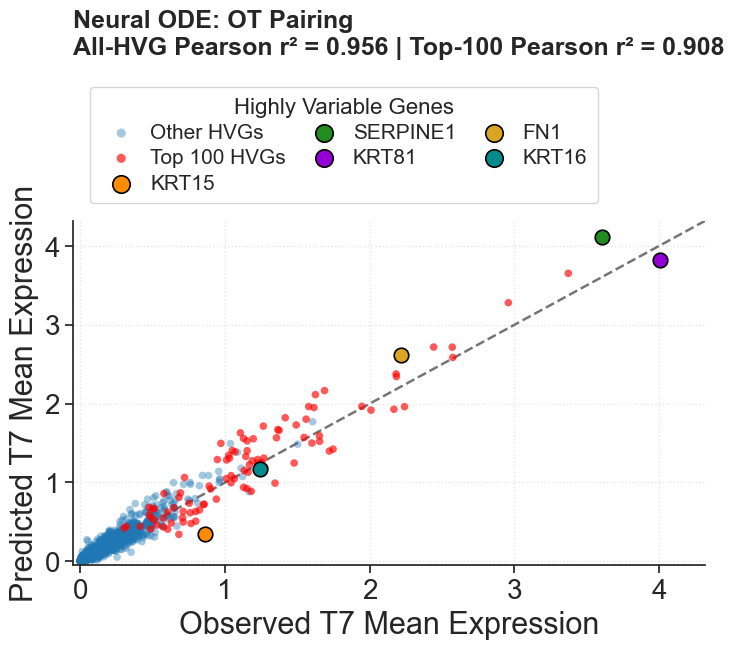

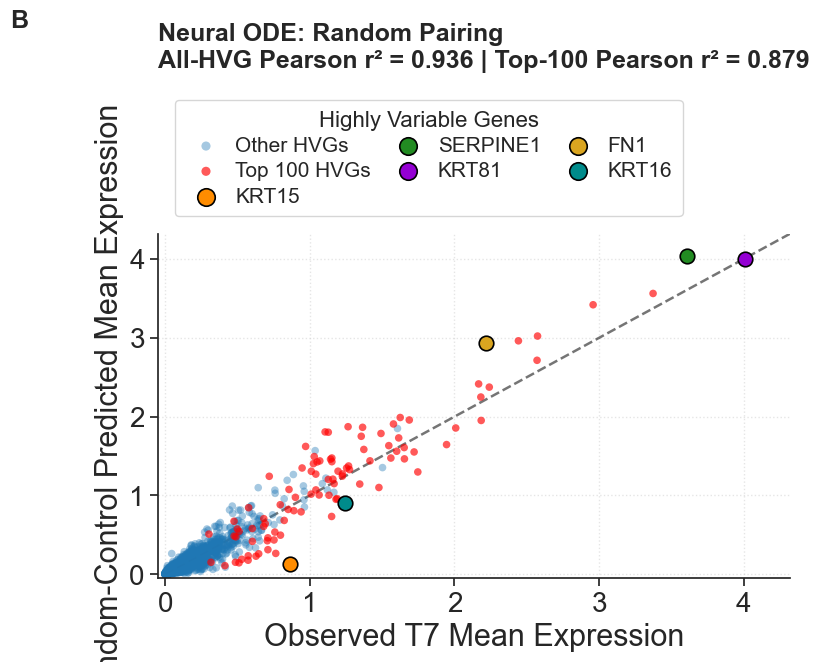


Top-five HVG absolute mean-expression errors — Neural ODE
Gene                   OT Error     Random Error
KRT15                  0.510744         0.730628
SERPINE1               0.507072         0.433718
KRT81                  0.186832         0.014945
FN1                    0.397358         0.714768
KRT16                  0.068516         0.342178
Average                0.334104         0.447247

T7 FORECAST REPORT: NEURAL ODE
PCA dimensions: 50

Primary metric:
Pearson r² — All HVGs | OT: 0.9562
Pearson r² — All HVGs | Random: 0.9361
Pearson r² — Top 100 HVGs | OT: 0.9082
Pearson r² — Top 100 HVGs | Random: 0.8786

Secondary metrics:
Endpoint R² | OT: 0.9431
Endpoint R² | Random: 0.9213
Wasserstein-2 | OT: 17.1199
Wasserstein-2 | Random: 17.638

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.04980962601929755
Random mean gene variance: 0.010961512778499192
True T7 mean distance from center: 17.618517495052668
OT mean distance fro

In [32]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training Time-Conditioned Neural ODE (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same architecture/hyperparameters as fibroblast dataset
# =========================================================

node_pc_dim = ode_data["pc_count"]

node_hidden_dim = 128
node_epochs = 60
node_learning_rate = 0.002
node_weight_decay = 1e-3
node_batch_size = 512
node_euler_steps = 6
node_output_scale = 2.0
node_random_state = 42

print("PCA dimensions:", node_pc_dim)
print("Hidden dimensions:", node_hidden_dim)
print("Hidden layers:", 2)
print("Activation: GELU")
print("Output activation: Tanh")
print("Output scale:", node_output_scale)
print("Euler steps:", node_euler_steps)
print("Epochs:", node_epochs)
print("Batch size:", node_batch_size)
print("Learning rate:", node_learning_rate)
print("Weight decay:", node_weight_decay)
print("Random state:", node_random_state)

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_node_ot = ode_data["X_train_ot"]
Y_node_ot = ode_data["Y_train_ot"]

X_node_random = ode_data["X_train_random"]
Y_node_random = ode_data["Y_train_random"]

X_node_test = ode_data["X_test"]

print("\nNeural ODE OT X:", X_node_ot.shape)
print("Neural ODE OT Y:", Y_node_ot.shape)
print("Neural ODE random X:", X_node_random.shape)
print("Neural ODE random Y:", Y_node_random.shape)
print("Neural ODE test X:", X_node_test.shape)

# =========================================================
# 3. TIME-CONDITIONED VECTOR FIELD
# =========================================================

class ODEFunc(nn.Module):
    def __init__(self, pc_dim, hidden_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(pc_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, pc_dim),
            nn.Tanh()
        )

    def forward(self, t, x):
        tx = torch.cat([x, t], dim=1)
        return node_output_scale * self.net(tx)

# =========================================================
# 4. NEURAL ODE MODEL
# Six explicit Euler integration steps
# =========================================================

class NeuralODEModel(nn.Module):
    def __init__(self, pc_dim, hidden_dim, euler_steps):
        super().__init__()
        self.func = ODEFunc(pc_dim, hidden_dim)
        self.euler_steps = euler_steps

    def forward(self, x_init, dt):
        x = x_init
        h = dt / self.euler_steps

        for step in range(self.euler_steps):
            t = h * step
            x = x + h * self.func(t, x)

        return x

# =========================================================
# 5. TRAINING FUNCTION
# =========================================================

def train_neural_ode(X_train, Y_train, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

    X_tensor = torch.tensor(np.asarray(X_train), dtype=torch.float32)
    Y_tensor = torch.tensor(np.asarray(Y_train), dtype=torch.float32)

    model = NeuralODEModel(node_pc_dim, node_hidden_dim, node_euler_steps)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=node_learning_rate,
        weight_decay=node_weight_decay
    )

    loss_fn = nn.MSELoss()
    n_samples = X_tensor.shape[0]
    final_loss = None

    model.train()

    for epoch in range(node_epochs):
        generator = torch.Generator()
        generator.manual_seed(seed + epoch)
        permutation = torch.randperm(n_samples, generator=generator)

        epoch_loss = 0.0
        epoch_samples = 0

        for start in range(0, n_samples, node_batch_size):
            idx = permutation[start:start + node_batch_size]

            X_batch = X_tensor[idx]
            Y_batch = Y_tensor[idx]

            x_init = X_batch[:, :node_pc_dim]
            dt = X_batch[:, node_pc_dim:node_pc_dim + 1]

            optimizer.zero_grad()

            pred = model(x_init, dt)
            loss = loss_fn(pred, Y_batch)

            loss.backward()
            optimizer.step()

            batch_n = len(idx)
            epoch_loss += loss.item() * batch_n
            epoch_samples += batch_n

        final_loss = epoch_loss / epoch_samples

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:3d}/{node_epochs} | "
                f"MSE = {final_loss:.6f}"
            )

    return model, final_loss

# =========================================================
# 6. TRAIN OT MODEL
# =========================================================

print("\n-> Training Neural ODE on OT-paired targets...")

node_ot, final_loss_node_ot = train_neural_ode(
    X_node_ot,
    Y_node_ot,
    seed=node_random_state
)

# =========================================================
# 7. TRAIN RANDOM MODEL
# =========================================================

print("\n-> Training Neural ODE on capped-random targets...")

node_random, final_loss_node_random = train_neural_ode(
    X_node_random,
    Y_node_random,
    seed=node_random_state
)

print("\nFinal OT training MSE:", round(final_loss_node_ot, 6))
print("Final random training MSE:", round(final_loss_node_random, 6))

# =========================================================
# 8. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

node_ot.eval()
node_random.eval()

X_test_node = torch.tensor(
    np.asarray(X_node_test),
    dtype=torch.float32
)

with torch.no_grad():
    pred_latent_node_ot = node_ot(
        X_test_node[:, :node_pc_dim],
        X_test_node[:, node_pc_dim:node_pc_dim + 1]
    ).cpu().numpy()

    pred_latent_node_random = node_random(
        X_test_node[:, :node_pc_dim],
        X_test_node[:, node_pc_dim:node_pc_dim + 1]
    ).cpu().numpy()

print("\nOT latent prediction shape:", pred_latent_node_ot.shape)
print("Random latent prediction shape:", pred_latent_node_random.shape)

# =========================================================
# 9. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# Neural ODE predicts 50 PCs. Step 7 zero-pads PCs 51-500
# before inverse transformation through the common PCA basis.
# =========================================================

pred_genes_node_ot = to_true_biological_gene_space(
    pred_latent_node_ot,
    node_pc_dim
)

pred_genes_node_random = to_true_biological_gene_space(
    pred_latent_node_random,
    node_pc_dim
)

print("OT biological prediction shape:", pred_genes_node_ot.shape)
print("Random biological prediction shape:", pred_genes_node_random.shape)

# =========================================================
# 10. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_node_ot,
    pred_genes_node_random,
    "Neural ODE",
    node_pc_dim
)

# =========================================================
# 11. RETRIEVE SAVED RESULTS
# =========================================================

node_results = model_results["Neural ODE"]

# =========================================================
# 12. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("NEURAL ODE EMT FINAL SUMMARY")
print("=" * 80)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", node_pc_dim)
print("Total model input features:", X_node_ot.shape[1])
print("Predicted PCA dimensions:", Y_node_ot.shape[1])
print("Direct forecast dT:", np.unique(X_node_test[:, -1]))

print("\nModel settings:")
print("Hidden dimensions:", node_hidden_dim)
print("Hidden layers:", 2)
print("Activation: GELU")
print("Output activation: Tanh")
print("Output scale:", node_output_scale)
print("Euler steps:", node_euler_steps)
print("Epochs:", node_epochs)
print("Batch size:", node_batch_size)
print("Learning rate:", node_learning_rate)
print("Weight decay:", node_weight_decay)
print("Random state:", node_random_state)

print("\nFinal training MSE:")
print("OT:", round(final_loss_node_ot, 6))
print("Random:", round(final_loss_node_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_node_ot.shape[0])
print("Random training rows:", X_node_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_node_ot, X_node_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_node_ot, Y_node_random)
)

# =========================================================
# 13. NEURAL ODE PERFORMANCE
# =========================================================

print("\nNeural ODE endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(node_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(node_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(node_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(node_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(node_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(node_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(node_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(node_results["Random_W2"], 4)
)

# =========================================================
# 14. CELL-DIVERSITY DIAGNOSTICS
# =========================================================

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    node_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    node_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    node_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    node_results["Random_Mean_Distance_From_Center"]
)

# =========================================================
# 15. T0 PERSISTENCE BASELINE
# =========================================================

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

# =========================================================
# 16. LEAKAGE CHECKS
# =========================================================

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 17. FINAL ASSERTIONS
# =========================================================

assert node_pc_dim == 50
assert node_hidden_dim == 128
assert node_epochs == 60
assert node_learning_rate == 0.002
assert node_weight_decay == 1e-3
assert node_batch_size == 512
assert node_euler_steps == 6
assert node_output_scale == 2.0
assert node_random_state == 42

assert X_node_ot.shape == (1836, 51)
assert Y_node_ot.shape == (1836, 50)
assert X_node_random.shape == (1836, 51)
assert Y_node_random.shape == (1836, 50)
assert X_node_test.shape == (77, 51)

assert pred_latent_node_ot.shape == (77, node_pc_dim)
assert pred_latent_node_random.shape == (77, node_pc_dim)

assert pred_genes_node_ot.shape == (77, 2000)
assert pred_genes_node_random.shape == (77, 2000)

assert np.isfinite(pred_latent_node_ot).all()
assert np.isfinite(pred_latent_node_random).all()
assert np.isfinite(pred_genes_node_ot).all()
assert np.isfinite(pred_genes_node_random).all()

assert X_node_ot.shape == X_node_random.shape
assert Y_node_ot.shape == Y_node_random.shape

assert np.allclose(X_node_ot, X_node_random)
assert not np.allclose(Y_node_ot, Y_node_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())
assert not any("T7" in transition for transition in ot_transition_info.keys())
assert not any("T7" in transition for transition in random_pairing_info.keys())

assert np.allclose(X_node_test[:, -1], 8.0)

# =========================================================
# 18. FINAL STATUS
# =========================================================

print("\n✔ Neural ODE EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ Neural ODE uses its selected 50-dimensional PCA state")
print("✔ Two 128-unit GELU hidden layers match fibroblast benchmark")
print("✔ Tanh output with scale 2 matches fibroblast benchmark")
print("✔ Six Euler integration steps match fibroblast benchmark")
print("✔ Adam learning rate = 0.002")
print("✔ Weight decay = 1e-3")
print("✔ 60 training epochs")
print("✔ Batch size = 512")
print("✔ 50-PC predictions zero-padded to common 500-PC basis before inverse PCA")
print("✔ OT and random Neural ODE models trained separately")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual Neural ODE figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

-> Training Temporal-Token Transformer (EMT): OT vs Random Pairing...
PCA dimensions: 50
Token size: 5
PCA tokens: 10
Total tokens including time: 11
Embedding dimensions: 32
Attention heads: 4
Feedforward dimensions: 128
Transformer layers: 1
Dropout: 0.1
Epochs: 30
Batch size: 512
Learning rate: 0.002
Weight decay: 1e-05
Random state: 42

Transformer OT X: (1836, 51)
Transformer OT Y: (1836, 50)
Transformer random X: (1836, 51)
Transformer random Y: (1836, 50)
Transformer test X: (77, 51)

-> Training Transformer on OT-paired targets...
Epoch   5/30 | MSE = 7.889706
Epoch  10/30 | MSE = 7.149868
Epoch  15/30 | MSE = 6.863746
Epoch  20/30 | MSE = 6.711170
Epoch  25/30 | MSE = 6.592172
Epoch  30/30 | MSE = 6.515524

-> Training Transformer on capped-random targets...
Epoch   5/30 | MSE = 8.267542
Epoch  10/30 | MSE = 7.973862
Epoch  15/30 | MSE = 7.870136
Epoch  20/30 | MSE = 7.818203
Epoch  25/30 | MSE = 7.730945
Epoch  30/30 | MSE = 7.664788

Final OT training MSE: 6.515524
Final ran

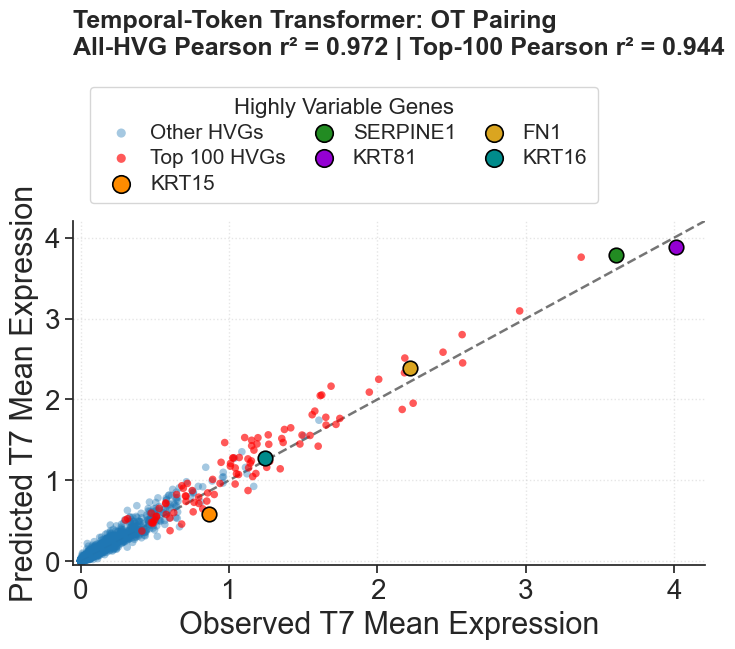

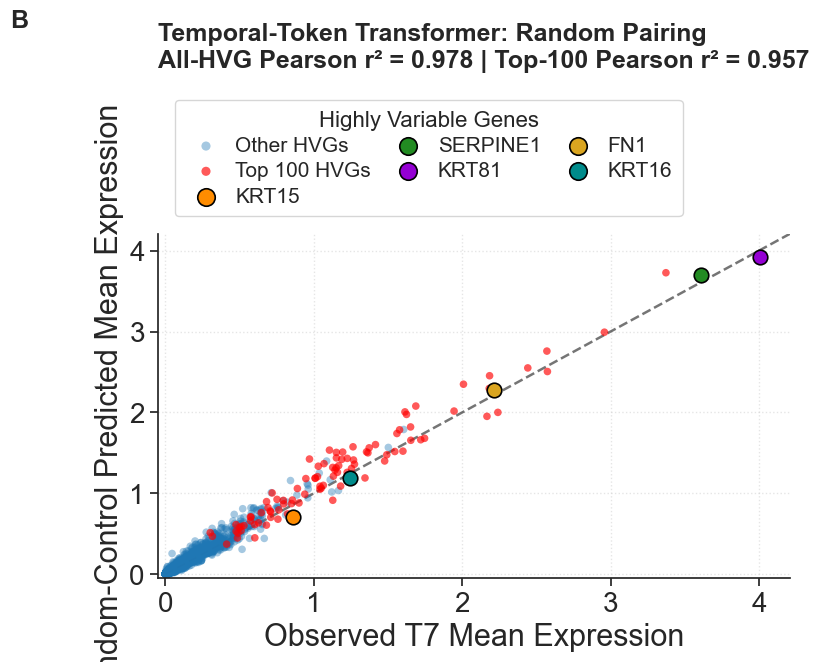


Top-five HVG absolute mean-expression errors — Temporal-Token Transformer
Gene                   OT Error     Random Error
KRT15                  0.284443         0.158734
SERPINE1               0.176342         0.092079
KRT81                  0.123999         0.086371
FN1                    0.167155         0.065479
KRT16                  0.030214         0.057924
Average                0.156431         0.092118

T7 FORECAST REPORT: TEMPORAL-TOKEN TRANSFORMER
PCA dimensions: 50

Primary metric:
Pearson r² — All HVGs | OT: 0.9724
Pearson r² — All HVGs | Random: 0.9777
Pearson r² — Top 100 HVGs | OT: 0.9436
Pearson r² — Top 100 HVGs | Random: 0.9573

Secondary metrics:
Endpoint R² | OT: 0.9609
Endpoint R² | Random: 0.9659
Wasserstein-2 | OT: 16.7172
Wasserstein-2 | Random: 17.8658

Cell-diversity diagnostics:
True T7 mean gene variance: 0.1643607035020713
OT mean gene variance: 0.03091819719845541
Random mean gene variance: 0.0019374608638961382
True T7 mean distance from center: 17.61

In [33]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training Temporal-Token Transformer (EMT): OT vs Random Pairing...")

# =========================================================
# 1. SETTINGS
# Same architecture/hyperparameters as fibroblast dataset
# =========================================================

transformer_pc_dim = transformer_data["pc_count"]

transformer_token_size = 5
transformer_embedding_dim = 32
transformer_heads = 4
transformer_ff_dim = 128
transformer_layers = 1
transformer_dropout = 0.1
transformer_epochs = 30
transformer_batch_size = 512
transformer_learning_rate = 0.002
transformer_weight_decay = 1e-5
transformer_random_state = 42

assert transformer_pc_dim % transformer_token_size == 0

transformer_num_pc_tokens = transformer_pc_dim // transformer_token_size
transformer_num_tokens = transformer_num_pc_tokens + 1

print("PCA dimensions:", transformer_pc_dim)
print("Token size:", transformer_token_size)
print("PCA tokens:", transformer_num_pc_tokens)
print("Total tokens including time:", transformer_num_tokens)
print("Embedding dimensions:", transformer_embedding_dim)
print("Attention heads:", transformer_heads)
print("Feedforward dimensions:", transformer_ff_dim)
print("Transformer layers:", transformer_layers)
print("Dropout:", transformer_dropout)
print("Epochs:", transformer_epochs)
print("Batch size:", transformer_batch_size)
print("Learning rate:", transformer_learning_rate)
print("Weight decay:", transformer_weight_decay)
print("Random state:", transformer_random_state)

# =========================================================
# 2. LOAD MODEL-SPECIFIC ARRAYS
# =========================================================

X_tf_ot = transformer_data["X_train_ot"]
Y_tf_ot = transformer_data["Y_train_ot"]

X_tf_random = transformer_data["X_train_random"]
Y_tf_random = transformer_data["Y_train_random"]

X_tf_test = transformer_data["X_test"]

print("\nTransformer OT X:", X_tf_ot.shape)
print("Transformer OT Y:", Y_tf_ot.shape)
print("Transformer random X:", X_tf_random.shape)
print("Transformer random Y:", Y_tf_random.shape)
print("Transformer test X:", X_tf_test.shape)

# =========================================================
# 3. TEMPORAL-TOKEN TRANSFORMER ARCHITECTURE
#
# 50 PCs -> 10 tokens of 5 PCs each.
# Δt is represented as a separate temporal token.
# =========================================================

class TimeSeriesTransformer(nn.Module):
    def __init__(self, pc_dim, token_size):
        super().__init__()

        self.pc_dim = pc_dim
        self.token_size = token_size
        self.num_pc_tokens = pc_dim // token_size

        self.pc_embedding = nn.Linear(
            token_size,
            transformer_embedding_dim
        )

        self.time_embedding = nn.Linear(
            1,
            transformer_embedding_dim
        )

        self.position_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_pc_tokens + 1,
                transformer_embedding_dim
            )
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=transformer_embedding_dim,
            nhead=transformer_heads,
            dim_feedforward=transformer_ff_dim,
            dropout=transformer_dropout,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=transformer_layers
        )

        self.decoder = nn.Linear(
            transformer_embedding_dim * self.num_pc_tokens,
            pc_dim
        )

    def forward(self, x):
        pc_values = x[:, :self.pc_dim]
        dt = x[:, self.pc_dim:self.pc_dim + 1]

        pc_tokens = pc_values.reshape(
            pc_values.shape[0],
            self.num_pc_tokens,
            self.token_size
        )

        pc_emb = self.pc_embedding(pc_tokens)
        time_emb = self.time_embedding(dt).unsqueeze(1)

        tokens = torch.cat(
            [time_emb, pc_emb],
            dim=1
        )

        tokens = tokens + self.position_embedding
        encoded = self.transformer(tokens)

        pc_encoded = encoded[:, 1:, :]
        flattened = pc_encoded.reshape(
            pc_encoded.shape[0],
            -1
        )

        return self.decoder(flattened)

# =========================================================
# 4. TRAINING FUNCTION
# =========================================================

def train_transformer(X_train, Y_train, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

    X_tensor = torch.tensor(
        np.asarray(X_train),
        dtype=torch.float32
    )

    Y_tensor = torch.tensor(
        np.asarray(Y_train),
        dtype=torch.float32
    )

    model = TimeSeriesTransformer(
        transformer_pc_dim,
        transformer_token_size
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=transformer_learning_rate,
        weight_decay=transformer_weight_decay
    )

    loss_fn = nn.MSELoss()
    n_samples = X_tensor.shape[0]
    final_loss = None

    model.train()

    for epoch in range(transformer_epochs):
        generator = torch.Generator()
        generator.manual_seed(seed + epoch)

        permutation = torch.randperm(
            n_samples,
            generator=generator
        )

        epoch_loss = 0.0
        epoch_samples = 0

        for start in range(
            0,
            n_samples,
            transformer_batch_size
        ):
            idx = permutation[
                start:start + transformer_batch_size
            ]

            X_batch = X_tensor[idx]
            Y_batch = Y_tensor[idx]

            optimizer.zero_grad()

            pred = model(X_batch)
            loss = loss_fn(pred, Y_batch)

            loss.backward()
            optimizer.step()

            batch_n = len(idx)
            epoch_loss += loss.item() * batch_n
            epoch_samples += batch_n

        final_loss = epoch_loss / epoch_samples

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1:3d}/{transformer_epochs} | "
                f"MSE = {final_loss:.6f}"
            )

    return model, final_loss

# =========================================================
# 5. TRAIN OT MODEL
# =========================================================

print("\n-> Training Transformer on OT-paired targets...")

tf_ot, final_loss_tf_ot = train_transformer(
    X_tf_ot,
    Y_tf_ot,
    seed=transformer_random_state
)

# =========================================================
# 6. TRAIN RANDOM MODEL
# =========================================================

print("\n-> Training Transformer on capped-random targets...")

tf_random, final_loss_tf_random = train_transformer(
    X_tf_random,
    Y_tf_random,
    seed=transformer_random_state
)

print("\nFinal OT training MSE:", round(final_loss_tf_ot, 6))
print("Final random training MSE:", round(final_loss_tf_random, 6))

# =========================================================
# 7. DIRECT HELD-OUT T0 -> T7 PREDICTION
# =========================================================

tf_ot.eval()
tf_random.eval()

X_test_tf = torch.tensor(
    np.asarray(X_tf_test),
    dtype=torch.float32
)

with torch.no_grad():
    pred_latent_tf_ot = tf_ot(X_test_tf).cpu().numpy()
    pred_latent_tf_random = tf_random(X_test_tf).cpu().numpy()

print("\nOT latent prediction shape:", pred_latent_tf_ot.shape)
print("Random latent prediction shape:", pred_latent_tf_random.shape)

# =========================================================
# 8. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# Transformer predicts 50 PCs. PCs 51-500 are zero-padded
# before inverse transformation through the common PCA basis.
# =========================================================

pred_genes_tf_ot = to_true_biological_gene_space(
    pred_latent_tf_ot,
    transformer_pc_dim
)

pred_genes_tf_random = to_true_biological_gene_space(
    pred_latent_tf_random,
    transformer_pc_dim
)

print("OT biological prediction shape:", pred_genes_tf_ot.shape)
print("Random biological prediction shape:", pred_genes_tf_random.shape)

# =========================================================
# 9. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_tf_ot,
    pred_genes_tf_random,
    "Temporal-Token Transformer",
    transformer_pc_dim
)

# =========================================================
# 10. RETRIEVE SAVED RESULTS
# =========================================================

tf_results = model_results["Temporal-Token Transformer"]

# =========================================================
# 11. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("TEMPORAL-TOKEN TRANSFORMER EMT FINAL SUMMARY")
print("=" * 80)

print("\nForecast setup:")
print("Forecast task: held-out T0 -> held-out T7")
print("Starting held-out T0 cells:", len(control_test_obs_names))
print("PCA dimensions:", transformer_pc_dim)
print("Total model input features:", X_tf_ot.shape[1])
print("Predicted PCA dimensions:", Y_tf_ot.shape[1])
print("Direct forecast dT:", np.unique(X_tf_test[:, -1]))

print("\nModel settings:")
print("Token size:", transformer_token_size)
print("PCA tokens:", transformer_num_pc_tokens)
print("Temporal tokens:", 1)
print("Embedding dimensions:", transformer_embedding_dim)
print("Attention heads:", transformer_heads)
print("Feedforward dimensions:", transformer_ff_dim)
print("Transformer layers:", transformer_layers)
print("Dropout:", transformer_dropout)
print("Epochs:", transformer_epochs)
print("Batch size:", transformer_batch_size)
print("Learning rate:", transformer_learning_rate)
print("Weight decay:", transformer_weight_decay)
print("Random state:", transformer_random_state)

print("\nFinal training MSE:")
print("OT:", round(final_loss_tf_ot, 6))
print("Random:", round(final_loss_tf_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_tf_ot.shape[0])
print("Random training rows:", X_tf_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_tf_ot, X_tf_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_tf_ot, Y_tf_random)
)

# =========================================================
# 12. TRANSFORMER PERFORMANCE
# =========================================================

print("\nTemporal-Token Transformer endpoint performance:")

print(
    "Pearson r² — All HVGs | OT:",
    round(tf_results["Pearson_r2_All"], 4)
)

print(
    "Pearson r² — All HVGs | Random:",
    round(tf_results["Random_Pearson_r2_All"], 4)
)

print(
    "Pearson r² — Top 100 | OT:",
    round(tf_results["Pearson_r2_Top100"], 4)
)

print(
    "Pearson r² — Top 100 | Random:",
    round(tf_results["Random_Pearson_r2_Top100"], 4)
)

print(
    "Endpoint R² | OT:",
    round(tf_results["Endpoint_R2"], 4)
)

print(
    "Endpoint R² | Random:",
    round(tf_results["Random_Endpoint_R2"], 4)
)

print(
    "Wasserstein-2 | OT:",
    round(tf_results["W2"], 4)
)

print(
    "Wasserstein-2 | Random:",
    round(tf_results["Random_W2"], 4)
)

# =========================================================
# 13. CELL-DIVERSITY DIAGNOSTICS
# =========================================================

print("\nCell-diversity diagnostics:")

print(
    "True T7 mean gene variance:",
    true_diversity["Mean_Gene_Variance"]
)

print(
    "OT mean gene variance:",
    tf_results["Mean_Gene_Variance"]
)

print(
    "Random mean gene variance:",
    tf_results["Random_Mean_Gene_Variance"]
)

print(
    "True T7 mean distance from center:",
    true_diversity["Mean_Distance_From_Center"]
)

print(
    "OT mean distance from center:",
    tf_results["Mean_Distance_From_Center"]
)

print(
    "Random mean distance from center:",
    tf_results["Random_Mean_Distance_From_Center"]
)

# =========================================================
# 14. T0 PERSISTENCE BASELINE
# =========================================================

print("\nNo-change T0 persistence baseline:")

print(
    "Pearson r² — All HVGs:",
    round(baseline_pearson_r2, 4)
)

print(
    "Pearson r² — Top 100:",
    round(baseline_top100_pearson_r2, 4)
)

print(
    "Endpoint R²:",
    round(baseline_r2, 4)
)

print(
    "Wasserstein-2:",
    round(baseline_w2, 4)
)

# =========================================================
# 15. LEAKAGE CHECKS
# =========================================================

print("\nLeakage checks:")

print(
    "Held-out T0 used for model training:",
    len(set(control_test_obs_names) & set(control_train_obs_names)) > 0
)

print(
    "T7 present in preprocessing/PCA cohort:",
    "T7" in set(adata_processed.obs["sample"].unique())
)

print(
    "T7 used for OT:",
    any("T7" in transition for transition in ot_transition_info.keys())
)

print(
    "T7 used for random pairing:",
    any("T7" in transition for transition in random_pairing_info.keys())
)

print("T7 used for Top-100 HVG ranking:", False)

# =========================================================
# 16. FINAL ASSERTIONS
# =========================================================

assert transformer_pc_dim == 50
assert transformer_token_size == 5
assert transformer_embedding_dim == 32
assert transformer_heads == 4
assert transformer_ff_dim == 128
assert transformer_layers == 1
assert transformer_dropout == 0.1
assert transformer_epochs == 30
assert transformer_batch_size == 512
assert transformer_learning_rate == 0.002
assert transformer_weight_decay == 1e-5
assert transformer_random_state == 42

assert X_tf_ot.shape == (1836, 51)
assert Y_tf_ot.shape == (1836, 50)
assert X_tf_random.shape == (1836, 51)
assert Y_tf_random.shape == (1836, 50)
assert X_tf_test.shape == (77, 51)

assert pred_latent_tf_ot.shape == (77, transformer_pc_dim)
assert pred_latent_tf_random.shape == (77, transformer_pc_dim)

assert pred_genes_tf_ot.shape == (77, 2000)
assert pred_genes_tf_random.shape == (77, 2000)

assert np.isfinite(pred_latent_tf_ot).all()
assert np.isfinite(pred_latent_tf_random).all()
assert np.isfinite(pred_genes_tf_ot).all()
assert np.isfinite(pred_genes_tf_random).all()

assert X_tf_ot.shape == X_tf_random.shape
assert Y_tf_ot.shape == Y_tf_random.shape

assert np.allclose(X_tf_ot, X_tf_random)
assert not np.allclose(Y_tf_ot, Y_tf_random)

assert target_cap == random_target_cap
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0

assert "T7" not in set(adata_processed.obs["sample"].unique())
assert not any("T7" in transition for transition in ot_transition_info.keys())
assert not any("T7" in transition for transition in random_pairing_info.keys())

assert np.allclose(X_tf_test[:, -1], 8.0)

# =========================================================
# 17. FINAL STATUS
# =========================================================

print("\n✔ Temporal-Token Transformer EMT benchmark complete")
print("✔ Direct held-out T0 -> T7 prediction")
print("✔ Transformer uses its selected 50-dimensional PCA state")
print("✔ Token size = 5")
print("✔ 10 PCA tokens + 1 explicit temporal token")
print("✔ d_model = 32")
print("✔ 4 attention heads")
print("✔ 1 Transformer encoder layer")
print("✔ Feedforward dimension = 128")
print("✔ Dropout = 0.1")
print("✔ GELU activation")
print("✔ Adam learning rate = 0.002")
print("✔ Weight decay = 1e-5")
print("✔ 30 training epochs")
print("✔ Batch size = 512")
print("✔ 50-PC predictions zero-padded to common 500-PC basis before inverse PCA")
print("✔ OT and random Transformer models trained separately")
print("✔ OT and random use identical model inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same effective target-use cap")
print("✔ Same 306 T0 training sources used by both models")
print("✔ All-HVG Pearson r² evaluated")
print("✔ Top-100 Pearson r² evaluated")
print("✔ Endpoint R² evaluated")
print("✔ Wasserstein-2 evaluated")
print("✔ Cell-diversity diagnostics evaluated")
print("✔ Compared against All-HVG and Top-100 T0 persistence baselines")
print("✔ Four endpoint prediction figures displayed")
print("✔ Individual Transformer figures not automatically saved")
print("✔ No recursive rollout")
print("✔ T7 excluded from preprocessing and PCA fitting")
print("✔ T7 excluded from OT and random pairing")
print("✔ T7 excluded from model training")
print("✔ T7 used only as the final evaluation endpoint")

--- Final Direct T0 -> T7 EMT Model Benchmark ---

Final EMT model-specific PCA dimensions:
Ridge Regression: 500 PCs
Absolute MLP: 500 PCs
XGBoost: 500 PCs
Random Forest: 10 PCs
Neural ODE: 50 PCs
Temporal-Token Transformer: 50 PCs

Shared pairing setup verified.
Common pairing PCA dimensions: 500
Shared OT training rows: 1836
Shared random training rows: 1836
Held-out T0 cells: 77
Direct forecast Δt: [8.]
Target-use cap: 2

Model-specific training arrays verified.
Ridge Regression: 500 PCs
Absolute MLP: 500 PCs
XGBoost: 500 PCs
Random Forest: 10 PCs
Neural ODE: 50 PCs
Temporal-Token Transformer: 50 PCs

Top-100 training HVGs verified.
Top-100 subset = highest-variance genes among the 2,000 HVGs
Ranking derived without T7

True T7 diversity:
Mean gene variance: 0.1643607035020713
Mean distance from center: 17.618517495052668

--- T0 Persistence Baselines ---
All-HVG Pearson r²: 0.5316
Top-100-HVG Pearson r²: 0.0656
Endpoint R²: 0.4787
Wasserstein-2: 23.393

All six final EMT model res

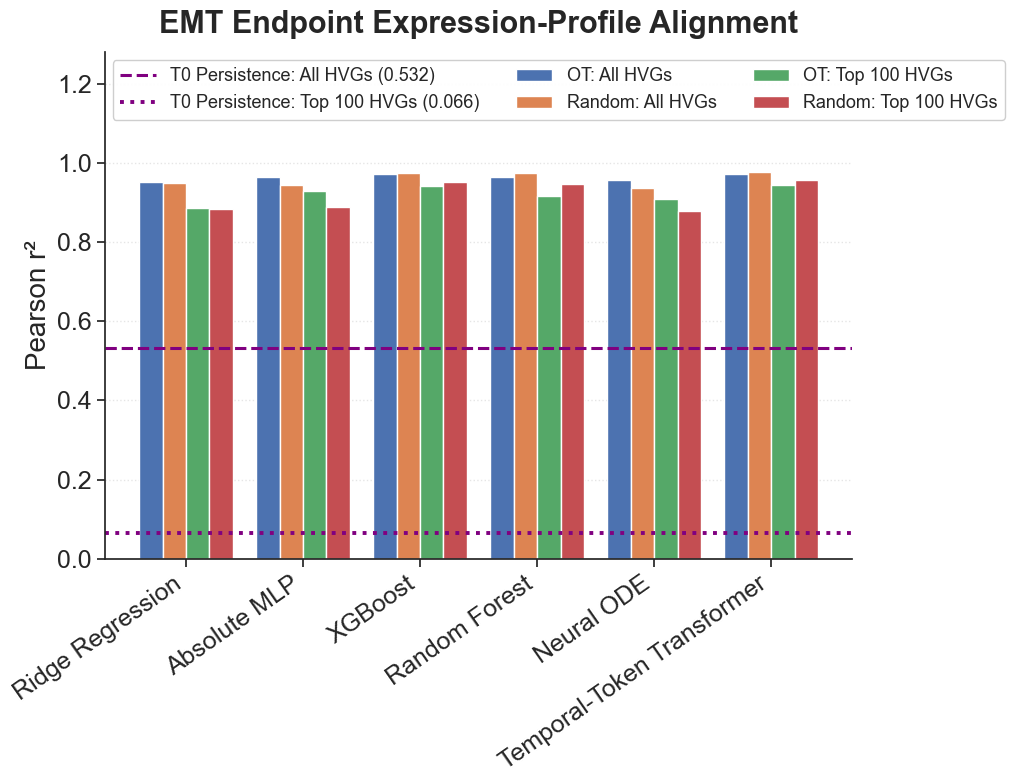

Saved: publication_emt_model_benchmark_endpoint_r2.png


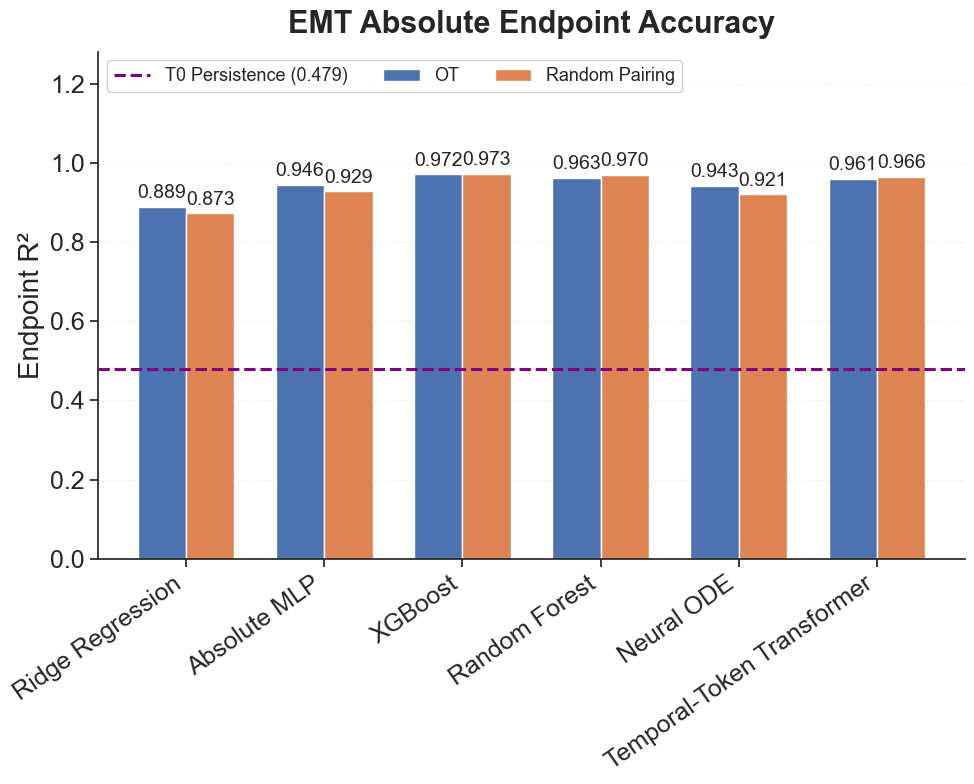

Saved: publication_emt_model_benchmark_w2.png


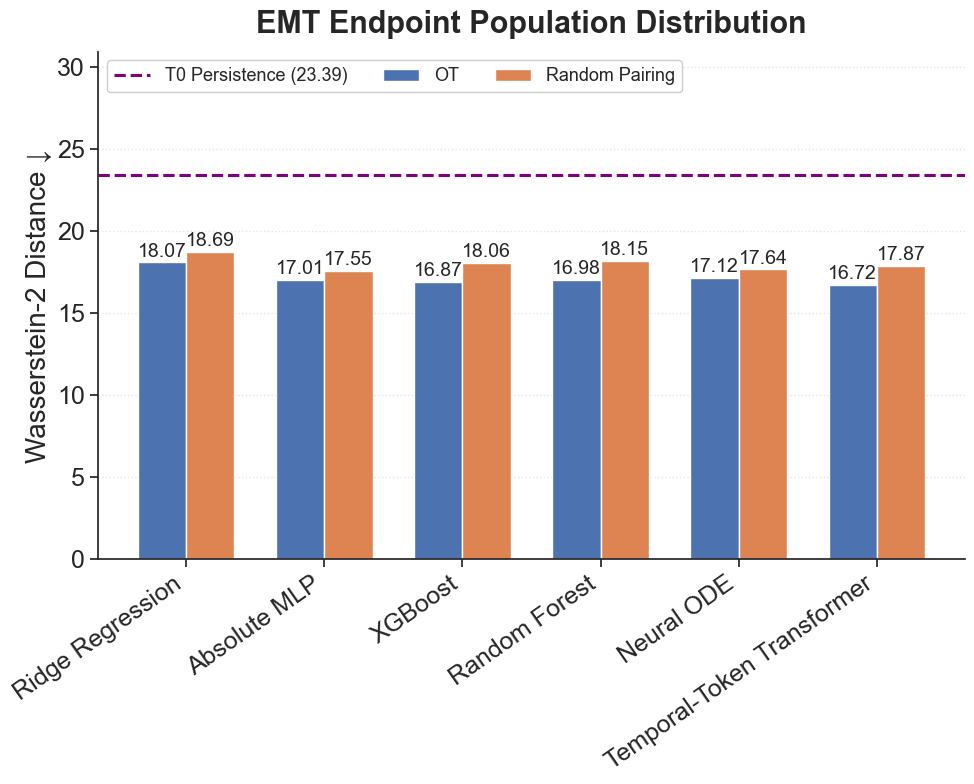

Saved: publication_emt_model_benchmark_diversity.png


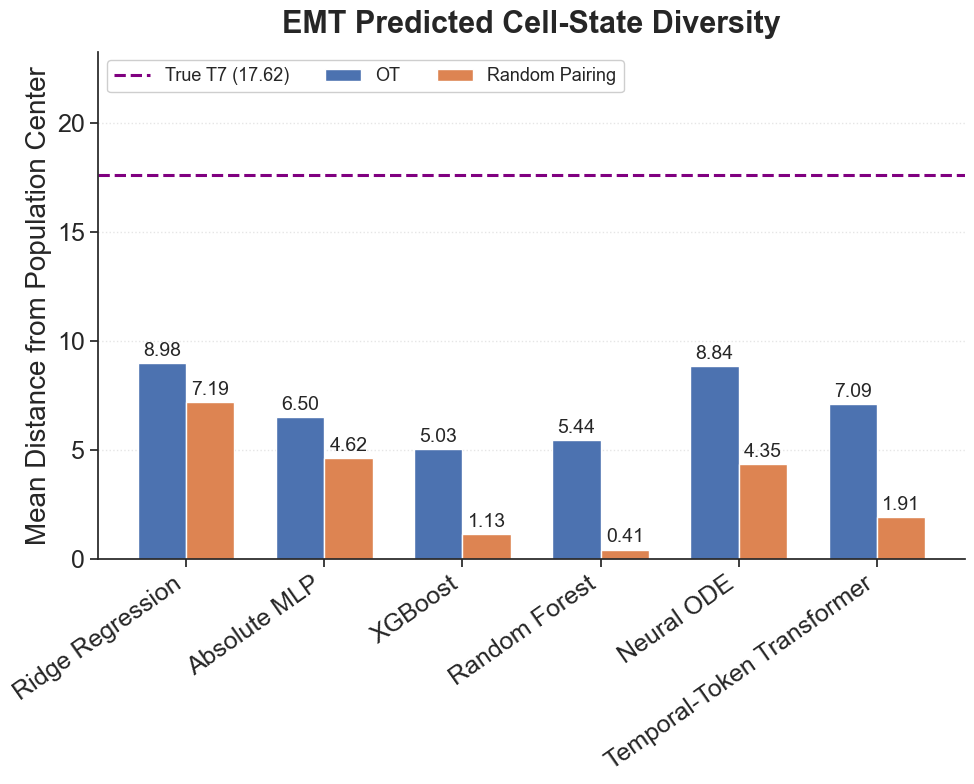


Saved publication figures:
publication_emt_model_benchmark_pearson.png
publication_emt_model_benchmark_endpoint_r2.png
publication_emt_model_benchmark_w2.png
publication_emt_model_benchmark_diversity.png

Saved numeric table:
final_direct_t0_t7_emt_model_metrics.csv

✔ All six final EMT model results assembled
✔ Direct held-out T0 -> T7 benchmark
✔ Common 500-PC representation used for OT/random pairing
✔ Model-specific PCA dimensions used for model training
✔ Ridge Regression = 500 PCs
✔ Absolute MLP = 500 PCs
✔ XGBoost = 500 PCs
✔ Random Forest = 10 PCs
✔ Neural ODE = 50 PCs
✔ Temporal-Token Transformer = 50 PCs
✔ Primary-dataset model architectures/hyperparameters transferred to EMT
✔ EMT OT settings independently selected: reg = 0.01, cap = 2
✔ EMT PCA dimensions independently selected
✔ OT and random branches use identical model inputs within each model
✔ OT and random differ only in target-pairing strategy
✔ Pearson benchmark includes All-HVG and Top-100-HVG results
✔ Top-100 su

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Final Direct T0 -> T7 EMT Model Benchmark ---")

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# =========================================================
# 1. MODEL ORDER
# =========================================================

preferred_order = [
    "Ridge Regression",
    "Absolute MLP",
    "XGBoost",
    "Random Forest",
    "Neural ODE",
    "Temporal-Token Transformer"
]

# =========================================================
# 2. FINAL MODEL-SPECIFIC PCA DIMENSIONS
# =========================================================

final_model_pca_dims = {
    "Ridge Regression": 500,
    "Absolute MLP": 500,
    "XGBoost": 500,
    "Random Forest": 10,
    "Neural ODE": 50,
    "Temporal-Token Transformer": 50
}

print("\nFinal EMT model-specific PCA dimensions:")

for model_name in preferred_order:
    print(f"{model_name}: {final_model_pca_dims[model_name]} PCs")

# =========================================================
# 3. REQUIRED METRICS
# =========================================================

required_keys = [
    "Pearson_r2_All",
    "Random_Pearson_r2_All",
    "Pearson_r2_Top100",
    "Random_Pearson_r2_Top100",
    "Endpoint_R2",
    "Random_Endpoint_R2",
    "W2",
    "Random_W2",
    "Mean_Gene_Variance",
    "Random_Mean_Gene_Variance",
    "Mean_Distance_From_Center",
    "Random_Mean_Distance_From_Center"
]

# =========================================================
# 4. VERIFY FINAL SHARED PAIRING SETUP
#
# OT/random pairing was established once in the common
# 500-PC representation before the train/test split.
# Model-specific truncation occurred afterward.
# =========================================================

assert optimal_pc_count == 500
assert np.allclose(X_train_final, X_train_random_final)
assert not np.allclose(Y_train_final, Y_train_random_final)
assert X_train_final.shape == (1836, 501)
assert Y_train_final.shape == (1836, 500)
assert X_train_random_final.shape == (1836, 501)
assert Y_train_random_final.shape == (1836, 500)
assert X_test_final.shape == (77, 501)

assert target_cap == random_target_cap
assert target_cap == 2

assert "T7" not in set(adata_processed.obs["sample"].unique())
assert not any("T7" in transition for transition in ot_transition_info.keys())
assert not any("T7" in transition for transition in random_pairing_info.keys())
assert len(set(control_test_obs_names) & set(control_train_obs_names)) == 0
assert np.allclose(X_test_final[:, -1], 8.0)

print("\nShared pairing setup verified.")
print("Common pairing PCA dimensions:", optimal_pc_count)
print("Shared OT training rows:", X_train_final.shape[0])
print("Shared random training rows:", X_train_random_final.shape[0])
print("Held-out T0 cells:", X_test_final.shape[0])
print("Direct forecast Δt:", np.unique(X_test_final[:, -1]))
print("Target-use cap:", target_cap)

# =========================================================
# 5. VERIFY MODEL-SPECIFIC TRAINING ARRAYS
# =========================================================

assert ridge_data["pc_count"] == 500
assert mlp_data["pc_count"] == 500
assert xgb_data["pc_count"] == 500
assert rf_data["pc_count"] == 10
assert ode_data["pc_count"] == 50
assert transformer_data["pc_count"] == 50

assert ridge_data["X_train_ot"].shape == (1836, 501)
assert ridge_data["Y_train_ot"].shape == (1836, 500)
assert ridge_data["X_test"].shape == (77, 501)

assert mlp_data["X_train_ot"].shape == (1836, 501)
assert mlp_data["Y_train_ot"].shape == (1836, 500)
assert mlp_data["X_test"].shape == (77, 501)

assert xgb_data["X_train_ot"].shape == (1836, 501)
assert xgb_data["Y_train_ot"].shape == (1836, 500)
assert xgb_data["X_test"].shape == (77, 501)

assert rf_data["X_train_ot"].shape == (1836, 11)
assert rf_data["Y_train_ot"].shape == (1836, 10)
assert rf_data["X_test"].shape == (77, 11)

assert ode_data["X_train_ot"].shape == (1836, 51)
assert ode_data["Y_train_ot"].shape == (1836, 50)
assert ode_data["X_test"].shape == (77, 51)

assert transformer_data["X_train_ot"].shape == (1836, 51)
assert transformer_data["Y_train_ot"].shape == (1836, 50)
assert transformer_data["X_test"].shape == (77, 51)

for data in [
    ridge_data,
    mlp_data,
    xgb_data,
    rf_data,
    ode_data,
    transformer_data
]:
    assert data["X_train_ot"].shape == data["X_train_random"].shape
    assert data["Y_train_ot"].shape == data["Y_train_random"].shape
    assert np.allclose(data["X_train_ot"], data["X_train_random"])
    assert not np.allclose(data["Y_train_ot"], data["Y_train_random"])
    assert np.allclose(data["X_test"][:, -1], 8.0)

print("\nModel-specific training arrays verified.")
print("Ridge Regression: 500 PCs")
print("Absolute MLP: 500 PCs")
print("XGBoost: 500 PCs")
print("Random Forest: 10 PCs")
print("Neural ODE: 50 PCs")
print("Temporal-Token Transformer: 50 PCs")

# =========================================================
# 6. VERIFY TOP-100 HVG DEFINITION
# =========================================================

assert len(top_100_hvg_indices) == 100
assert len(np.unique(top_100_hvg_indices)) == 100
assert np.isfinite(training_gene_variance).all()

print("\nTop-100 training HVGs verified.")
print("Top-100 subset = highest-variance genes among the 2,000 HVGs")
print("Ranking derived without T7")

# =========================================================
# 7. TRUE T7 DIVERSITY
# =========================================================

true_diversity_metrics = cell_diversity_metrics(
    Y_test_true_biological
)

true_gene_variance = true_diversity_metrics[
    "Mean_Gene_Variance"
]

true_distance_from_center = true_diversity_metrics[
    "Mean_Distance_From_Center"
]

print("\nTrue T7 diversity:")
print("Mean gene variance:", true_gene_variance)
print("Mean distance from center:", true_distance_from_center)

# =========================================================
# 8. PERSISTENCE BASELINES
# =========================================================

print("\n--- T0 Persistence Baselines ---")
print("All-HVG Pearson r²:", round(baseline_pearson_r2, 4))
print("Top-100-HVG Pearson r²:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

# =========================================================
# 9. VERIFY ALL SIX FINAL MODEL RESULTS EXIST
# =========================================================

for model_name in preferred_order:
    if model_name not in model_results:
        raise ValueError(
            f"{model_name} is missing from model_results. "
            "Rerun its final EMT model cell."
        )

    missing = [
        key
        for key in required_keys
        if key not in model_results[model_name]
    ]

    if missing:
        raise ValueError(
            f"{model_name} is missing metrics: "
            + ", ".join(missing)
        )

print("\nAll six final EMT model result sets verified.")

# =========================================================
# 10. BUILD LEADERBOARD
# =========================================================

records = []

for model_name in preferred_order:
    results = model_results[model_name]

    ot_distance_error = abs(
        results["Mean_Distance_From_Center"]
        - true_distance_from_center
    )

    random_distance_error = abs(
        results["Random_Mean_Distance_From_Center"]
        - true_distance_from_center
    )

    ot_variance_error = abs(
        results["Mean_Gene_Variance"]
        - true_gene_variance
    )

    random_variance_error = abs(
        results["Random_Mean_Gene_Variance"]
        - true_gene_variance
    )

    records.append({
        "Model": model_name,
        "PCA_Dim": final_model_pca_dims[model_name],
        "OT_Pearson_All": results["Pearson_r2_All"],
        "Random_Pearson_All": results["Random_Pearson_r2_All"],
        "OT_Pearson_Top100_HVG": results["Pearson_r2_Top100"],
        "Random_Pearson_Top100_HVG": results["Random_Pearson_r2_Top100"],
        "OT_Endpoint_R2": results["Endpoint_R2"],
        "Random_Endpoint_R2": results["Random_Endpoint_R2"],
        "OT_W2": results["W2"],
        "Random_W2": results["Random_W2"],
        "OT_Gene_Variance": results["Mean_Gene_Variance"],
        "Random_Gene_Variance": results["Random_Mean_Gene_Variance"],
        "OT_Distance_From_Center": results["Mean_Distance_From_Center"],
        "Random_Distance_From_Center": results["Random_Mean_Distance_From_Center"],
        "OT_Diversity_Error": ot_distance_error,
        "Random_Diversity_Error": random_distance_error,
        "OT_Variance_Error": ot_variance_error,
        "Random_Variance_Error": random_variance_error
    })

df_leaderboard_emt = pd.DataFrame(records)

# =========================================================
# 11. PRINT LEADERBOARD
# =========================================================

print("\n" + "=" * 200)
print("DIRECT HELD-OUT T0 -> T7 EMT FORECASTING LEADERBOARD")
print("=" * 200)
print(
    df_leaderboard_emt.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)
print("=" * 200)

# =========================================================
# 12. BEST OT MODELS
# =========================================================

best_ot_pearson_all = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_Pearson_All"].idxmax()
]

best_ot_pearson_top = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_Pearson_Top100_HVG"].idxmax()
]

best_ot_r2 = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_Endpoint_R2"].idxmax()
]

best_ot_w2 = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_W2"].idxmin()
]

best_ot_diversity = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_Diversity_Error"].idxmin()
]

best_ot_variance = df_leaderboard_emt.loc[
    df_leaderboard_emt["OT_Variance_Error"].idxmin()
]

print("\n--- Best OT Models ---")
print(
    f"Best Pearson r² All HVGs: "
    f"{best_ot_pearson_all['Model']} "
    f"({best_ot_pearson_all['OT_Pearson_All']:.4f})"
)

print(
    f"Best Pearson r² Top 100 HVGs: "
    f"{best_ot_pearson_top['Model']} "
    f"({best_ot_pearson_top['OT_Pearson_Top100_HVG']:.4f})"
)

print(
    f"Best Endpoint R²: "
    f"{best_ot_r2['Model']} "
    f"({best_ot_r2['OT_Endpoint_R2']:.4f})"
)

print(
    f"Best Wasserstein-2: "
    f"{best_ot_w2['Model']} "
    f"({best_ot_w2['OT_W2']:.4f})"
)

print(
    f"Closest cell diversity: "
    f"{best_ot_diversity['Model']} "
    f"(distance error="
    f"{best_ot_diversity['OT_Diversity_Error']:.4f})"
)

print(
    f"Closest gene variance: "
    f"{best_ot_variance['Model']} "
    f"(variance error="
    f"{best_ot_variance['OT_Variance_Error']:.4f})"
)

# =========================================================
# 13. BEST RANDOM MODELS
# =========================================================

best_random_pearson_all = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_Pearson_All"].idxmax()
]

best_random_pearson_top = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_Pearson_Top100_HVG"].idxmax()
]

best_random_r2 = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_Endpoint_R2"].idxmax()
]

best_random_w2 = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_W2"].idxmin()
]

best_random_diversity = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_Diversity_Error"].idxmin()
]

best_random_variance = df_leaderboard_emt.loc[
    df_leaderboard_emt["Random_Variance_Error"].idxmin()
]

print("\n--- Best Capped-Random Models ---")
print(
    f"Best Pearson r² All HVGs: "
    f"{best_random_pearson_all['Model']} "
    f"({best_random_pearson_all['Random_Pearson_All']:.4f})"
)

print(
    f"Best Pearson r² Top 100 HVGs: "
    f"{best_random_pearson_top['Model']} "
    f"({best_random_pearson_top['Random_Pearson_Top100_HVG']:.4f})"
)

print(
    f"Best Endpoint R²: "
    f"{best_random_r2['Model']} "
    f"({best_random_r2['Random_Endpoint_R2']:.4f})"
)

print(
    f"Best Wasserstein-2: "
    f"{best_random_w2['Model']} "
    f"({best_random_w2['Random_W2']:.4f})"
)

print(
    f"Closest cell diversity: "
    f"{best_random_diversity['Model']} "
    f"(distance error="
    f"{best_random_diversity['Random_Diversity_Error']:.4f})"
)

print(
    f"Closest gene variance: "
    f"{best_random_variance['Model']} "
    f"(variance error="
    f"{best_random_variance['Random_Variance_Error']:.4f})"
)

# =========================================================
# 14. COMMON FIGURE SETTINGS
# =========================================================

models = df_leaderboard_emt["Model"].values
x = np.arange(len(models))

# =========================================================
# 15. FIGURE 1 — PEARSON r²
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))
bar_width = 0.20

ax.bar(
    x - 1.5 * bar_width,
    df_leaderboard_emt["OT_Pearson_All"],
    width=bar_width,
    label="OT: All HVGs"
)

ax.bar(
    x - 0.5 * bar_width,
    df_leaderboard_emt["Random_Pearson_All"],
    width=bar_width,
    label="Random: All HVGs"
)

ax.bar(
    x + 0.5 * bar_width,
    df_leaderboard_emt["OT_Pearson_Top100_HVG"],
    width=bar_width,
    label="OT: Top 100 HVGs"
)

ax.bar(
    x + 1.5 * bar_width,
    df_leaderboard_emt["Random_Pearson_Top100_HVG"],
    width=bar_width,
    label="Random: Top 100 HVGs"
)

ax.axhline(
    baseline_pearson_r2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"T0 Persistence: All HVGs ({baseline_pearson_r2:.3f})"
)

ax.axhline(
    baseline_top100_pearson_r2,
    color="purple",
    linestyle=":",
    linewidth=2.8,
    label=f"T0 Persistence: Top 100 HVGs ({baseline_top100_pearson_r2:.3f})"
)

ax.set_title(
    "EMT Endpoint Expression-Profile Alignment",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_ylabel("Pearson r²", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.set_ylim(0, 1.28)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

sns.despine()
plt.tight_layout()

plt.savefig(
    "publication_emt_model_benchmark_pearson.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: publication_emt_model_benchmark_pearson.png")
plt.show()

# =========================================================
# 16. FIGURE 2 — ENDPOINT R²
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))
bar_width = 0.35

bars_ot = ax.bar(
    x - bar_width / 2,
    df_leaderboard_emt["OT_Endpoint_R2"],
    width=bar_width,
    label="OT"
)

bars_random = ax.bar(
    x + bar_width / 2,
    df_leaderboard_emt["Random_Endpoint_R2"],
    width=bar_width,
    label="Random Pairing"
)

ax.axhline(
    baseline_r2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"T0 Persistence ({baseline_r2:.3f})"
)

ax.set_title(
    "EMT Absolute Endpoint Accuracy",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_ylabel("Endpoint R²", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.set_ylim(0, 1.28)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.012,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()

plt.savefig(
    "publication_emt_model_benchmark_endpoint_r2.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: publication_emt_model_benchmark_endpoint_r2.png")
plt.show()

# =========================================================
# 17. FIGURE 3 — WASSERSTEIN-2
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))
bar_width = 0.35

bars_ot = ax.bar(
    x - bar_width / 2,
    df_leaderboard_emt["OT_W2"],
    width=bar_width,
    label="OT"
)

bars_random = ax.bar(
    x + bar_width / 2,
    df_leaderboard_emt["Random_W2"],
    width=bar_width,
    label="Random Pairing"
)

ax.axhline(
    baseline_w2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"T0 Persistence ({baseline_w2:.2f})"
)

w2_max = max(
    df_leaderboard_emt["OT_W2"].max(),
    df_leaderboard_emt["Random_W2"].max(),
    baseline_w2
)

ax.set_ylim(0, w2_max * 1.32)

ax.set_title(
    "EMT Endpoint Population Distribution",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_ylabel("Wasserstein-2 Distance ↓", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.12,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()

plt.savefig(
    "publication_emt_model_benchmark_w2.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: publication_emt_model_benchmark_w2.png")
plt.show()

# =========================================================
# 18. FIGURE 4 — CELL-STATE DIVERSITY
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))
bar_width = 0.35

bars_ot = ax.bar(
    x - bar_width / 2,
    df_leaderboard_emt["OT_Distance_From_Center"],
    width=bar_width,
    label="OT"
)

bars_random = ax.bar(
    x + bar_width / 2,
    df_leaderboard_emt["Random_Distance_From_Center"],
    width=bar_width,
    label="Random Pairing"
)

ax.axhline(
    true_distance_from_center,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"True T7 ({true_distance_from_center:.2f})"
)

diversity_max = max(
    df_leaderboard_emt["OT_Distance_From_Center"].max(),
    df_leaderboard_emt["Random_Distance_From_Center"].max(),
    true_distance_from_center
)

ax.set_ylim(0, diversity_max * 1.32)

ax.set_title(
    "EMT Predicted Cell-State Diversity",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_ylabel(
    "Mean Distance from Population Center",
    fontsize=20
)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.15,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()

plt.savefig(
    "publication_emt_model_benchmark_diversity.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: publication_emt_model_benchmark_diversity.png")
plt.show()

# =========================================================
# 19. SAVE NUMERIC RESULTS
# =========================================================

df_leaderboard_emt.to_csv(
    "final_direct_t0_t7_emt_model_metrics.csv",
    index=False
)

print("\nSaved publication figures:")
print("publication_emt_model_benchmark_pearson.png")
print("publication_emt_model_benchmark_endpoint_r2.png")
print("publication_emt_model_benchmark_w2.png")
print("publication_emt_model_benchmark_diversity.png")

print("\nSaved numeric table:")
print("final_direct_t0_t7_emt_model_metrics.csv")

# =========================================================
# 20. FINAL STATUS
# =========================================================

print("\n✔ All six final EMT model results assembled")
print("✔ Direct held-out T0 -> T7 benchmark")
print("✔ Common 500-PC representation used for OT/random pairing")
print("✔ Model-specific PCA dimensions used for model training")
print("✔ Ridge Regression = 500 PCs")
print("✔ Absolute MLP = 500 PCs")
print("✔ XGBoost = 500 PCs")
print("✔ Random Forest = 10 PCs")
print("✔ Neural ODE = 50 PCs")
print("✔ Temporal-Token Transformer = 50 PCs")
print("✔ Primary-dataset model architectures/hyperparameters transferred to EMT")
print("✔ EMT OT settings independently selected: reg = 0.01, cap = 2")
print("✔ EMT PCA dimensions independently selected")
print("✔ OT and random branches use identical model inputs within each model")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ Pearson benchmark includes All-HVG and Top-100-HVG results")
print("✔ Top-100 subset = 100 most variable genes among training-selected HVGs")
print("✔ T7 excluded from Top-100 HVG ranking")
print("✔ All four benchmark graphs generated separately")
print("✔ Pearson benchmark includes All-HVG and Top-100-HVG T0 persistence baselines")
print("✔ Persistence baselines shown in purple")
print("✔ True T7 diversity shown in purple")
print("✔ Publication figures saved at 300 DPI")
print("✔ T7 remains a sealed final evaluation endpoint")

--- EMT Publication Figures: OT Wasserstein-2 PCA-Dimension Sweep ---
Saved: EMT_Figure_A_OT_PC1_PC2_Cell_Distributions.png


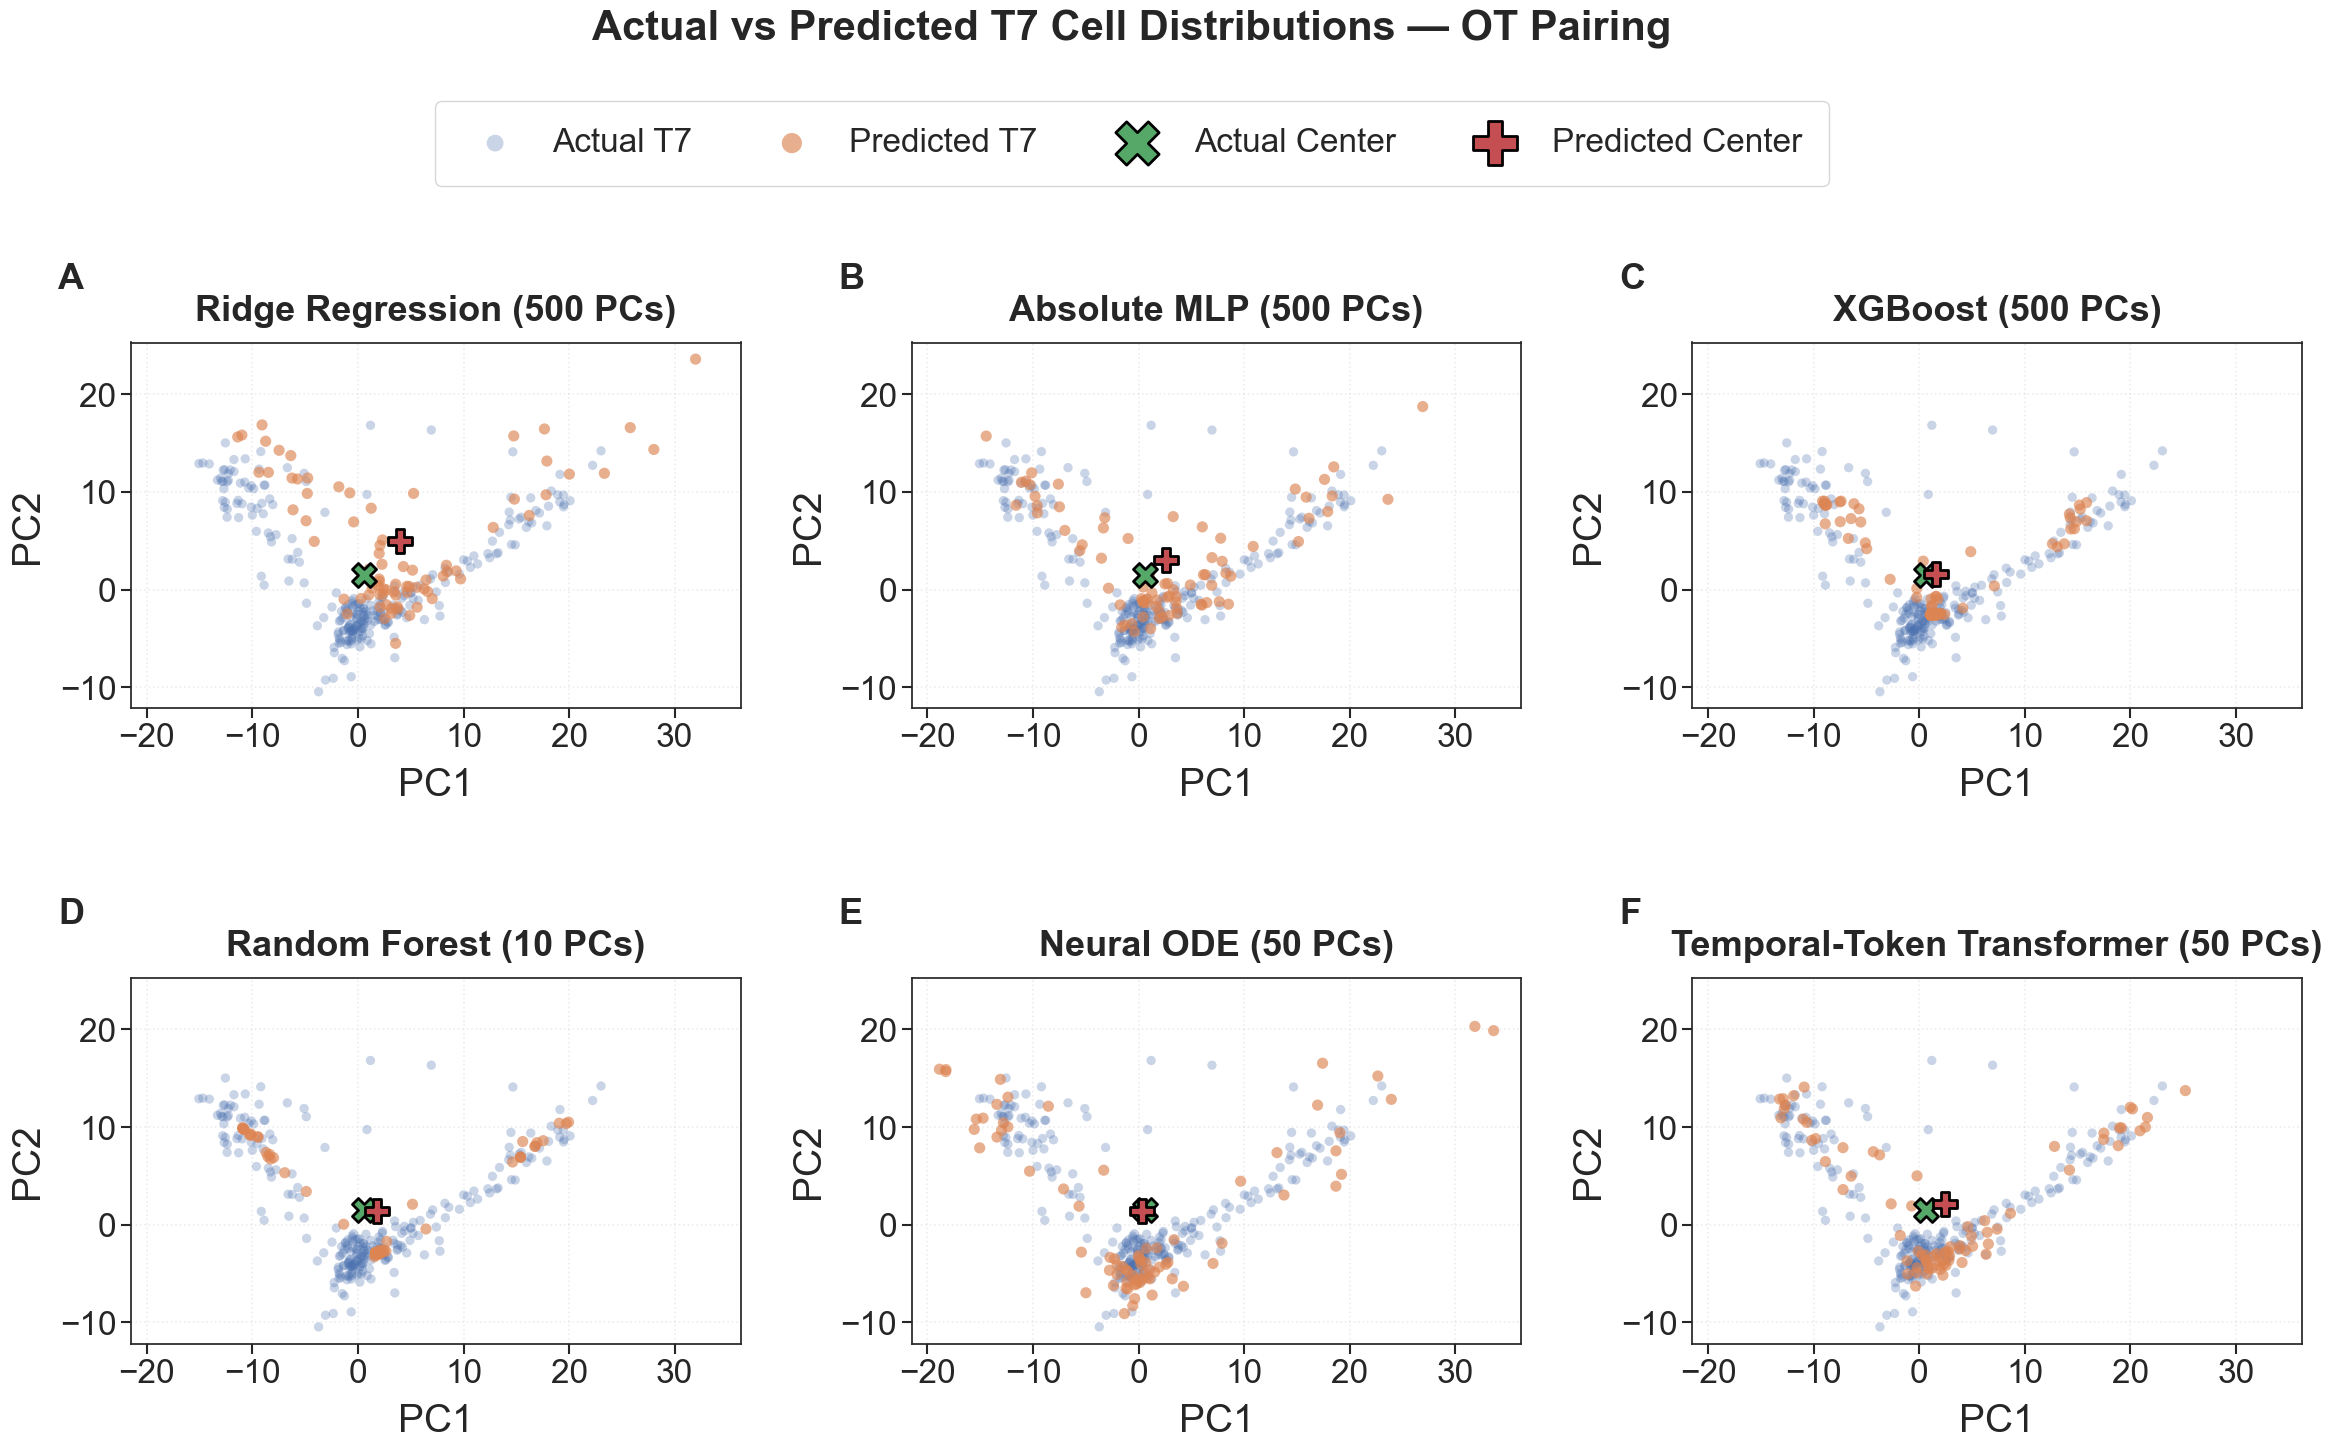

Saved: EMT_Capped_Random_PC1_PC2_Cell_Distributions.png


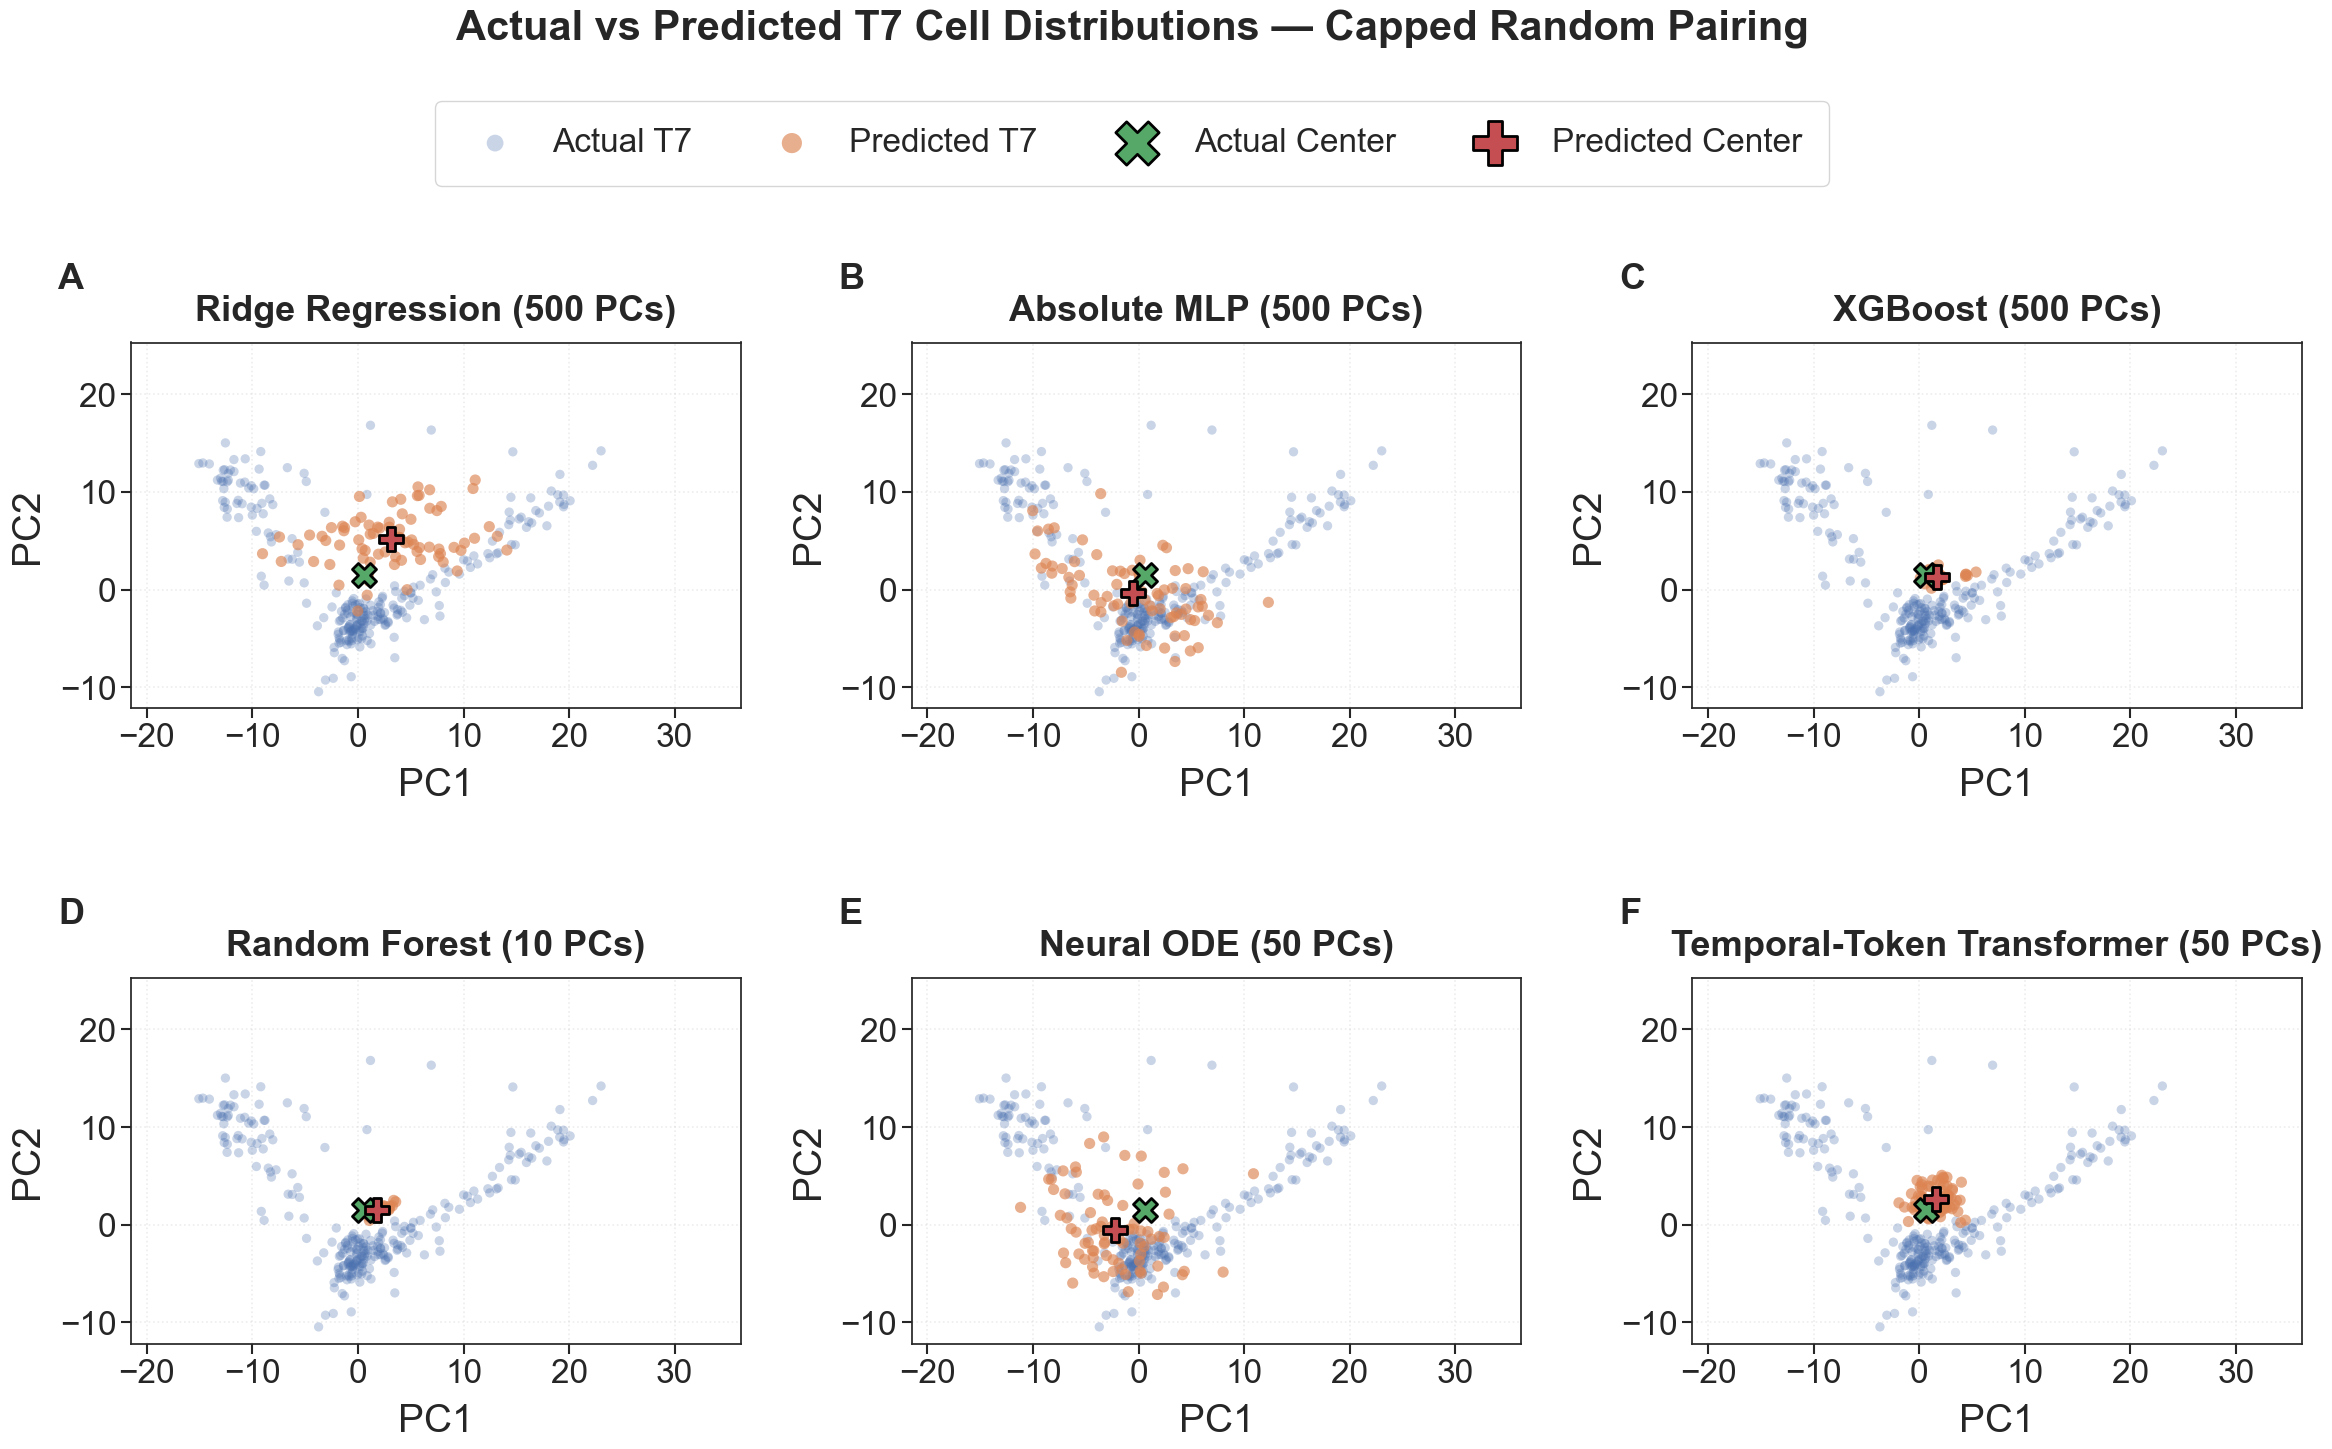

Refitted independent 750-PC basis; original 500-PC predictions remain unchanged.
Fixed OT real-cell pairings retained; no T7 data used for PCA fitting.

2 PCs | positive W2=5.871197 | negative W2=6.692199
Training Ridge Regression at 2 PCs...
  Exact matched-77 PCA-space W2 = 5.683091 | saved 1/56
Training Absolute MLP at 2 PCs...
  Exact matched-77 PCA-space W2 = 4.842354 | saved 2/56
Training XGBoost at 2 PCs...
  Exact matched-77 PCA-space W2 = 4.530648 | saved 3/56
Training Random Forest at 2 PCs...
  Exact matched-77 PCA-space W2 = 4.521273 | saved 4/56
Training Neural ODE at 2 PCs...
  Exact matched-77 PCA-space W2 = 6.679518 | saved 5/56
Training Temporal-Token Transformer at 2 PCs...
  Exact matched-77 PCA-space W2 = 5.712520 | saved 6/56

5 PCs | positive W2=7.533360 | negative W2=14.525300
Training Ridge Regression at 5 PCs...
  Exact matched-77 PCA-space W2 = 9.306565 | saved 7/56
Training Absolute MLP at 5 PCs...
  Exact matched-77 PCA-space W2 = 7.571706 | saved 8/56
Train

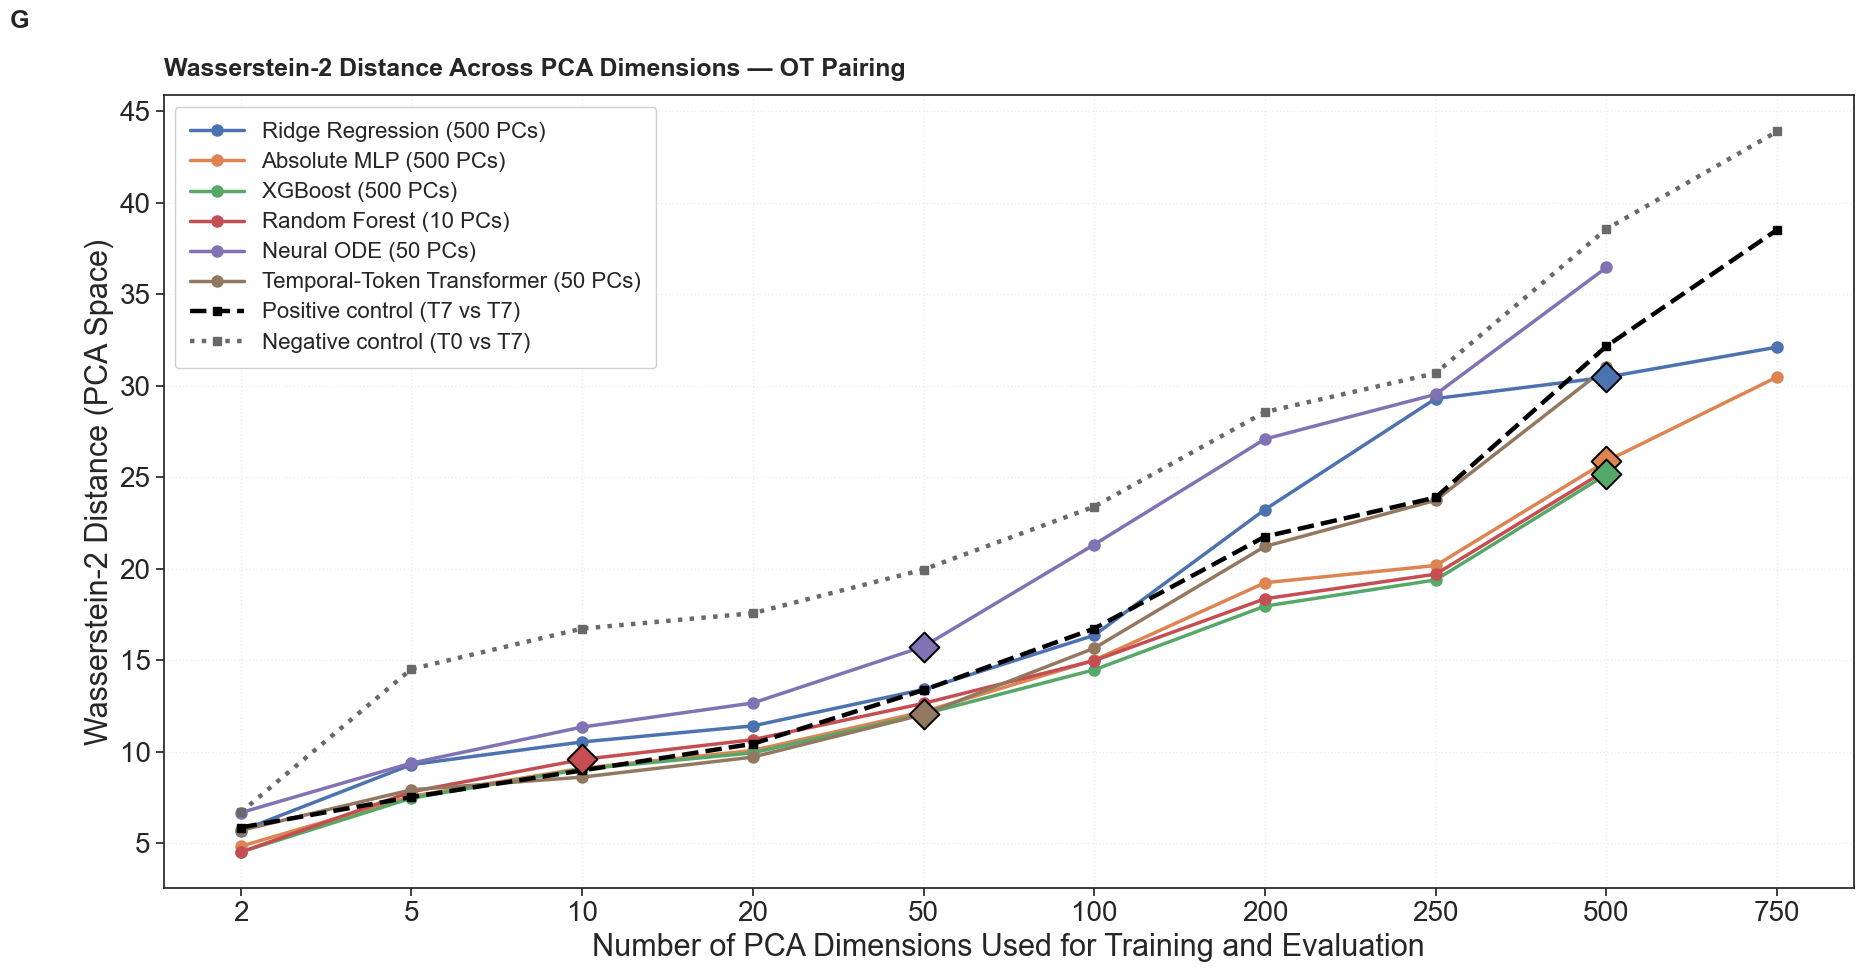


Original selected-dimensional PCA-space W2 (matched 77 cells):
Ridge Regression             | 500 PCs | W2 = 30.471275
Absolute MLP                 | 500 PCs | W2 = 25.884958
XGBoost                      | 500 PCs | W2 = 25.161841
Random Forest                |  10 PCs | W2 = 9.586450
Neural ODE                   |  50 PCs | W2 = 15.757440
Temporal-Token Transformer   |  50 PCs | W2 = 12.047035

Complete: 56 independently trained OT-only configurations.
Figure A: six original selected-model T7 distributions (panels A-F).
Figure G: exact matched-77 PCA-space W2 vs PCA dimensions with controls.
NOTE: Figure A uses the original 500-PC PCA basis; Figure G uses a separately refitted 750-PC basis.
Results: EMT_OT_PCA_Wasserstein2_Sweep_750_Matched77.csv
Controls: EMT_OT_PCA_Wasserstein2_Controls_Matched77.csv


In [35]:
"""EMT publication figures: OT distributions and exact PCA-space W2 sensitivity.
Run in the existing EMT notebook AFTER preprocessing, fixed OT pairing,
train/test construction, and original six model predictions.
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
import torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

print('--- EMT Publication Figures: OT Wasserstein-2 PCA-Dimension Sweep ---')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
SAVE_DPI = 300
A_MAIN_TITLE_SIZE = 30
A_PANEL_TITLE_SIZE = 26
A_AXIS_LABEL_SIZE = 28
A_TICK_SIZE = 24
A_LEGEND_SIZE = 24
A_FIGURE_LABEL_SIZE = 26
B_TITLE_SIZE = 18
B_AXIS_LABEL_SIZE = 22
B_TICK_SIZE = 20
B_LEGEND_SIZE = 16
B_FIGURE_LABEL_SIZE = 18
PC_GRID = [2, 5, 10, 20, 50, 100, 200, 250, 500, 750]
MODEL_CAP = {'Ridge Regression': 750, 'Absolute MLP': 750,
             'XGBoost': 500, 'Random Forest': 500,
             'Neural ODE': 500, 'Temporal-Token Transformer': 500}
ORIGINAL_PCS = {
    'Ridge Regression': 500,
    'Absolute MLP': 500,
    'XGBoost': 500,
    'Random Forest': 10,
    'Neural ODE': 50,
    'Temporal-Token Transformer': 50,
}
MODEL_ORDER = list(ORIGINAL_PCS)
CHECKPOINT = 'EMT_OT_PCA_Wasserstein2_Sweep_750_Matched77.csv'
CONTROL_CHECKPOINT = 'EMT_OT_PCA_Wasserstein2_Controls_Matched77.csv'

# All variables below are defined by the original EMT notebook.
observed_t7 = np.asarray(X_t7_pca, dtype=np.float64)
original_ot = {
    'Ridge Regression': np.asarray(pred_latent_ridge_ot),
    'Absolute MLP': np.asarray(pred_latent_mlp_ot),
    'XGBoost': np.asarray(pred_latent_xgb_ot),
    'Random Forest': np.asarray(pred_latent_rf_ot),
    'Neural ODE': np.asarray(pred_latent_node_ot),
    'Temporal-Token Transformer': np.asarray(pred_latent_tf_ot),
}
original_random = {
    'Ridge Regression': np.asarray(pred_latent_ridge_random),
    'Absolute MLP': np.asarray(pred_latent_mlp_random),
    'XGBoost': np.asarray(pred_latent_xgb_random),
    'Random Forest': np.asarray(pred_latent_rf_random),
    'Neural ODE': np.asarray(pred_latent_node_random),
    'Temporal-Token Transformer': np.asarray(pred_latent_tf_random),
}
assert observed_t7.shape == (256, 500)
assert model_pca_dims == ORIGINAL_PCS
assert len(train_source_idx) == 306 and len(test_source_idx) == 77
assert not np.intersect1d(train_source_idx, test_source_idx).size
assert 'T7' not in set(adata_processed.obs['sample'].unique())
assert not any('T7' in key for key in ot_transition_info)
for name in MODEL_ORDER:
    assert original_ot[name].shape == (77, ORIGINAL_PCS[name])
    assert original_random[name].shape == (77, ORIGINAL_PCS[name])
    assert np.isfinite(original_ot[name]).all()
    assert np.isfinite(original_random[name]).all()

# Figure A: originally trained models; common PC1/PC2 axes for OT and random.
all_xy = np.vstack([observed_t7[:, :2]] +
                   [p[:, :2] for p in original_ot.values()] +
                   [p[:, :2] for p in original_random.values()])
mins, maxs = all_xy.min(axis=0), all_xy.max(axis=0)
padding = np.maximum((maxs - mins) * 0.05, 1e-8)
limits = [(mins[i] - padding[i], maxs[i] + padding[i]) for i in range(2)]
observed_center = observed_t7[:, :2].mean(axis=0)

def plot_distributions(predictions, title, filename, figure_label=None):
    fig, axes = plt.subplots(2, 3, figsize=(24, 15))
    for panel_idx, (ax, name) in enumerate(zip(axes.flat, MODEL_ORDER)):
        ax.text(-0.12, 1.22, chr(65 + panel_idx), transform=ax.transAxes,
                fontsize=A_FIGURE_LABEL_SIZE, fontweight='bold',
                ha='left', va='top', clip_on=False)
        predicted = predictions[name][:, :2]
        predicted_center = predicted.mean(axis=0)
        ax.scatter(observed_t7[:, 0], observed_t7[:, 1], s=45,
                   alpha=0.30, edgecolors='none', label='Actual T7')
        ax.scatter(predicted[:, 0], predicted[:, 1], s=65,
                   alpha=0.65, edgecolors='none', label='Predicted T7')
        ax.scatter(*observed_center, s=300, marker='X', edgecolors='black',
                   linewidths=2, zorder=5, label='Actual Center')
        ax.scatter(*predicted_center, s=300, marker='P', edgecolors='black',
                   linewidths=2, zorder=5, label='Predicted Center')
        ax.set_xlim(*limits[0]); ax.set_ylim(*limits[1])
        ax.set_title(f'{name} ({ORIGINAL_PCS[name]} PCs)',
                     fontsize=A_PANEL_TITLE_SIZE, fontweight='bold', pad=16)
        ax.set_xlabel('PC1', fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
        ax.set_ylabel('PC2', fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
        ax.tick_params(axis='both', which='major', labelsize=A_TICK_SIZE,
                       width=1.5, length=7)
        ax.grid(True, linestyle=':', linewidth=1.2, alpha=0.35)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.935),
               ncol=4, fontsize=A_LEGEND_SIZE, markerscale=1.8,
               frameon=True, borderpad=0.8, labelspacing=0.8,
               handletextpad=0.7, columnspacing=2.0)
    fig.suptitle(title, fontsize=A_MAIN_TITLE_SIZE, fontweight='bold', y=0.985)
    plt.tight_layout(rect=[0.025, 0.02, 0.995, 0.89], h_pad=3.5, w_pad=3.0)
    fig.savefig(filename, dpi=SAVE_DPI, bbox_inches='tight', pad_inches=0.05)
    print('Saved:', filename)
    plt.show()

plot_distributions(original_ot, 'Actual vs Predicted T7 Cell Distributions — OT Pairing',
                   'EMT_Figure_A_OT_PC1_PC2_Cell_Distributions.png', 'A')
plot_distributions(original_random,
                   'Actual vs Predicted T7 Cell Distributions — Capped Random Pairing',
                   'EMT_Capped_Random_PC1_PC2_Cell_Distributions.png')

# A NEW 750-PC PCA basis is required; the original EMT PCA has only 500 PCs.
# Refit using ONLY pre-T7 HVGs and the original training-derived scaling.
# Keep the original 500-PC notebook objects untouched.
assert adata_processed.n_obs == 1869 and adata_t7.n_obs == 256
assert set(adata_processed.obs['sample'].unique()) == set(['T0','T1','T2','T3','T4','T5','T6'])
assert set(adata_t7.obs['sample'].unique()) == {'T7'}
assert np.array_equal(adata_processed.var_names, adata_t7.var_names)
assert len(adata_processed.var_names) == 2000
hvg_names_sweep = list(adata_processed.var_names)

def dense_hvg(obj):
    raw = obj.raw[:, hvg_names_sweep].X
    return np.asarray(raw.toarray() if hasattr(raw, 'toarray') else raw,
                      dtype=np.float64)

pre_t7_log = dense_hvg(adata_processed)
t7_log = dense_hvg(adata_t7)
assert pre_t7_log.shape == (1869, 2000)
assert t7_log.shape == (256, 2000)
assert np.asarray(train_mean).shape == (2000,)
assert np.asarray(train_std).shape == (2000,)
std = np.asarray(train_std, dtype=np.float64).copy()
assert np.all(std > 0)
mean = np.asarray(train_mean, dtype=np.float64)
pre_t7_scaled = np.clip((pre_t7_log - mean) / std, -10, 10)
t7_scaled = np.clip((t7_log - mean) / std, -10, 10)

# The PCA is fitted once on T0-T6, never on T7. Full SVD yields 750
# components from the same fixed fit, enabling nested PCA prefixes.
sweep_pca_750 = PCA(n_components=750, svd_solver='full')
sweep_all_pca = sweep_pca_750.fit_transform(pre_t7_scaled)
sweep_t7_pca = sweep_pca_750.transform(t7_scaled)
assert sweep_all_pca.shape == (1869, 750)
assert sweep_t7_pca.shape == (256, 750)
assert np.isfinite(sweep_all_pca).all() and np.isfinite(sweep_t7_pca).all()

# Preserve EXACT original OT real-cell pairings (target IDs) and outer
# T0 train/test split. Only the coordinates change to the 750-PC basis.
# Do NOT rerun Sinkhorn or recalculate target assignments.
index_by_id = {str(cid): i for i, cid in enumerate(adata_processed.obs_names)}
assert len(index_by_id) == 1869
source_ids = np.asarray(ot_transition_info['T0->T1']['source_ids']).astype(str)
assert len(source_ids) == 383
assert np.array_equal(source_ids, np.asarray(source_obs_names).astype(str))
assert len(train_source_idx) == 306 and len(test_source_idx) == 77
assert not np.intersect1d(train_source_idx, test_source_idx).size
assert all(str(cid) in index_by_id for cid in source_ids)
source_coords = sweep_all_pca[[index_by_id[cid] for cid in source_ids]]

x_blocks, y_blocks = [], []
for stage in ['T1','T2','T3','T4','T5','T6']:
    info = ot_transition_info['T0->' + stage]
    assert np.array_equal(np.asarray(info['source_ids']).astype(str), source_ids)
    paired_ids = np.asarray(info['paired_target_ids']).astype(str)
    assert len(paired_ids) == 383
    assert all(cid in index_by_id for cid in paired_ids)
    target_coords = sweep_all_pca[[index_by_id[cid] for cid in paired_ids]]
    dt = float(info['dt'])
    x_blocks.append(np.column_stack([source_coords[train_source_idx],
                                     np.full(len(train_source_idx), dt)]))
    y_blocks.append(target_coords[train_source_idx])
full_X = np.vstack(x_blocks)
full_Y = np.vstack(y_blocks)
full_test_X = np.column_stack([source_coords[test_source_idx],
                               np.full(len(test_source_idx), float(t7_dt))])
assert full_X.shape == (1836, 751)
assert full_Y.shape == (1836, 750)
assert full_test_X.shape == (77, 751)
assert np.allclose(full_test_X[:, -1], 8.0)
print('Refitted independent 750-PC basis; original 500-PC predictions remain unchanged.')
print('Fixed OT real-cell pairings retained; no T7 data used for PCA fitting.')

class SweepAbsoluteMLP(nn.Module):
    def __init__(self, pc):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(pc + 1, 128), nn.GELU(),
                                 nn.Dropout(0.2), nn.Linear(128, 128),
                                 nn.GELU(), nn.Dropout(0.2), nn.Linear(128, pc))
    def forward(self, x):
        return self.net(x)

class SweepODEFunc(nn.Module):
    def __init__(self, pc):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(pc + 1, 128), nn.GELU(),
                                 nn.Linear(128, 128), nn.GELU(),
                                 nn.Linear(128, pc), nn.Tanh())
    def forward(self, t, x):
        return 2.0 * self.net(torch.cat([x, t], dim=1))

class SweepNeuralODE(nn.Module):
    def __init__(self, pc):
        super().__init__()
        self.func = SweepODEFunc(pc)
    def forward(self, x_init, dt):
        x = x_init
        h = dt / 6
        for step in range(6):
            x = x + h * self.func(h * step, x)
        return x

class SweepTemporalTokenTransformer(nn.Module):
    """Original EMT flattened-token decoder; zero-pad only when pc % 5 != 0."""
    def __init__(self, pc):
        super().__init__()
        self.pc_dim = pc
        self.token_size = 5
        self.num_pc_tokens = (pc + 4) // 5
        self.padded_pc_dim = self.num_pc_tokens * 5
        self.pc_embedding = nn.Linear(5, 32)
        self.time_embedding = nn.Linear(1, 32)
        self.position_embedding = nn.Parameter(
            torch.zeros(1, self.num_pc_tokens + 1, 32))
        layer = nn.TransformerEncoderLayer(d_model=32, nhead=4,
                                           dim_feedforward=128, dropout=0.1,
                                           activation='gelu', batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=1)
        self.decoder = nn.Linear(32 * self.num_pc_tokens, self.pc_dim)
    def forward(self, x):
        pcs = x[:, :self.pc_dim]
        dt = x[:, self.pc_dim:self.pc_dim + 1]
        if self.padded_pc_dim > self.pc_dim:
            pcs = nn.functional.pad(pcs, (0, self.padded_pc_dim - self.pc_dim))
        pc_tokens = pcs.reshape(pcs.shape[0], self.num_pc_tokens, 5)
        tokens = torch.cat([self.time_embedding(dt).unsqueeze(1),
                            self.pc_embedding(pc_tokens)], dim=1)
        encoded = self.transformer(tokens + self.position_embedding)
        flattened = encoded[:, 1:, :].reshape(pcs.shape[0], -1)
        return self.decoder(flattened)

def fit_predict(name, x_train, y_train, x_test, pc):
    if name == 'Ridge Regression':
        model = Ridge(alpha=10.0).fit(x_train, y_train)
        return model.predict(x_test)
    if name == 'XGBoost':
        base = XGBRegressor(n_estimators=30, max_depth=3, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8,
                            random_state=42, n_jobs=1, tree_method='hist',
                            verbosity=0)
        model = MultiOutputRegressor(base, n_jobs=-1)
        model.fit(x_train, y_train)
        return model.predict(x_test)
    if name == 'Random Forest':
        model = RandomForestRegressor(n_estimators=20, max_depth=4,
                                      max_features=0.5, random_state=42,
                                      n_jobs=2)
        model.fit(x_train, y_train)
        return model.predict(x_test)

    torch.manual_seed(42)
    np.random.seed(42)
    xt = torch.tensor(x_train, dtype=torch.float32)
    yt = torch.tensor(y_train, dtype=torch.float32)
    test = torch.tensor(x_test, dtype=torch.float32)
    if name == 'Absolute MLP':
        model = SweepAbsoluteMLP(pc)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
        model.train()
        for epoch in range(120):
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(xt), yt)
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            return model(test).cpu().numpy()

    if name == 'Neural ODE':
        model = SweepNeuralODE(pc)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.002,
                                     weight_decay=1e-3)
        epochs = 60
    elif name == 'Temporal-Token Transformer':
        model = SweepTemporalTokenTransformer(pc)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.002,
                                     weight_decay=1e-5)
        epochs = 30
    else:
        raise ValueError(name)

    model.train()
    for epoch in range(epochs):
        generator = torch.Generator()
        generator.manual_seed(42 + epoch)
        permutation = torch.randperm(len(xt), generator=generator)
        for start in range(0, len(xt), 512):
            idx = permutation[start:start + 512]
            batch_x, batch_y = xt[idx], yt[idx]
            optimizer.zero_grad()
            if name == 'Neural ODE':
                pred = model(batch_x[:, :pc], batch_x[:, pc:pc + 1])
            else:
                pred = model(batch_x)
            loss = nn.functional.mse_loss(pred, batch_y)
            loss.backward(); optimizer.step()
    model.eval()
    with torch.no_grad():
        if name == 'Neural ODE':
            pred = model(test[:, :pc], test[:, pc:pc + 1])
        else:
            pred = model(test)
        return pred.cpu().numpy()

# =========================================================
# 8. SAMPLE-SIZE-MATCHED EXACT W2 CONTROLS AND SWEEP
# =========================================================
# The same 77 actual T7 reference cells are used for all model/control
# comparisons, with a disjoint 77-cell T7 positive-control sample.
W2_SAMPLE_SIZE = len(test_source_idx)  # 77
W2_RANDOM_SEED = 42
w2_rng = np.random.default_rng(W2_RANDOM_SEED)
assert sweep_t7_pca.shape[0] >= 2 * W2_SAMPLE_SIZE
w2_perm = w2_rng.permutation(sweep_t7_pca.shape[0])
w2_reference_indices = w2_perm[:W2_SAMPLE_SIZE]
w2_positive_indices = w2_perm[W2_SAMPLE_SIZE:2 * W2_SAMPLE_SIZE]
assert not np.intersect1d(w2_reference_indices, w2_positive_indices).size
# T0 test coordinates in the independently refitted 750-PC basis.
w2_t0_test = full_test_X[:, :-1]
assert w2_t0_test.shape == (W2_SAMPLE_SIZE, 750)

def exact_w2_pca(first, second):
    first = np.asarray(first, dtype=np.float64)
    second = np.asarray(second, dtype=np.float64)
    assert first.ndim == second.ndim == 2
    assert first.shape == second.shape
    assert first.shape[0] == W2_SAMPLE_SIZE
    assert np.isfinite(first).all() and np.isfinite(second).all()
    weights = np.full(W2_SAMPLE_SIZE, 1.0 / W2_SAMPLE_SIZE)
    cost = ot.dist(first, second, metric='sqeuclidean')
    squared = ot.emd2(weights, weights, cost, numItermax=1000000)
    return float(np.sqrt(max(float(squared), 0.0)))

required_columns = ['Model', 'Pairing', 'PCs', 'Model_PCA_Dim',
                    'Wasserstein_2', 'Selected_PCA_Dimension']
if os.path.exists(CHECKPOINT):
    previous = pd.read_csv(CHECKPOINT)
    assert set(required_columns).issubset(previous.columns)
    assert not previous.duplicated(['Model', 'PCs']).any()
    assert all(int(r.PCs) <= MODEL_CAP[r.Model] for r in previous.itertuples())
    records = previous[required_columns].to_dict('records')
    print(f'Resuming from {len(records)} saved matched-77 configurations.')
else:
    records = []
completed = {(r['Model'], int(r['PCs'])) for r in records}
control_records = []

for pc in PC_GRID:
    x_train = np.column_stack([full_X[:, :pc], full_X[:, -1]])
    y_train = full_Y[:, :pc]
    x_test = np.column_stack([full_test_X[:, :pc], full_test_X[:, -1]])
    actual = sweep_t7_pca[:, :pc]
    assert x_train.shape == (1836, pc + 1)
    assert y_train.shape == (1836, pc)
    assert x_test.shape == (77, pc + 1)
    assert actual.shape == (256, pc)

    reference = actual[w2_reference_indices]
    positive = actual[w2_positive_indices]
    negative = w2_t0_test[:, :pc]
    positive_w2 = exact_w2_pca(reference, positive)
    negative_w2 = exact_w2_pca(reference, negative)
    control_records.extend([
        {'Control': 'Positive control (T7 vs T7)', 'PCs': pc,
         'Wasserstein_2': positive_w2},
        {'Control': 'Negative control (T0 vs T7)', 'PCs': pc,
         'Wasserstein_2': negative_w2},
    ])
    pd.DataFrame(control_records).to_csv(CONTROL_CHECKPOINT, index=False)
    print(f'\n{pc} PCs | positive W2={positive_w2:.6f} | negative W2={negative_w2:.6f}')

    for name in MODEL_ORDER:
        if pc > MODEL_CAP[name]:
            continue
        if (name, pc) in completed:
            print(f'Skipping completed: {name} / {pc} PCs')
            continue
        print(f'Training {name} at {pc} PCs...')
        prediction = np.asarray(fit_predict(name, x_train, y_train, x_test, pc),
                                dtype=np.float64)
        assert prediction.shape == (W2_SAMPLE_SIZE, pc)
        assert np.isfinite(prediction).all()
        w2 = exact_w2_pca(reference, prediction)
        records.append({'Model': name, 'Pairing': 'OT', 'PCs': pc,
                        'Model_PCA_Dim': ORIGINAL_PCS[name],
                        'Wasserstein_2': w2,
                        'Selected_PCA_Dimension': pc == ORIGINAL_PCS[name]})
        completed.add((name, pc))
        pd.DataFrame(records, columns=required_columns).to_csv(CHECKPOINT, index=False)
        print(f'  Exact matched-77 PCA-space W2 = {w2:.6f} | saved {len(records)}/56')

results = pd.DataFrame(records, columns=required_columns)
assert len(results) == 56, f'Expected 56 configurations, got {len(results)}'
assert not results.duplicated(['Model', 'PCs']).any()
for name in MODEL_ORDER:
    assert sorted(results.loc[results['Model'] == name, 'PCs'].tolist()) == [
        k for k in PC_GRID if k <= MODEL_CAP[name]]
results = results.sort_values(['PCs', 'Model']).reset_index(drop=True)
results.to_csv(CHECKPOINT, index=False)
controls = pd.DataFrame(control_records)
assert len(controls) == 2 * len(PC_GRID)
controls.to_csv(CONTROL_CHECKPOINT, index=False)

# =========================================================
# 9. FIGURE G — W2 VS PCA DIMENSIONS WITH BOTH CONTROLS
# =========================================================
fig, ax = plt.subplots(figsize=(19, 10))
position = {pc: i for i, pc in enumerate(PC_GRID)}
for name in MODEL_ORDER:
    subset = results.loc[results['Model'] == name].sort_values('PCs')
    line, = ax.plot([position[int(pc)] for pc in subset['PCs']],
                    subset['Wasserstein_2'], marker='o', linewidth=2.5,
                    markersize=8, label=f'{name} ({ORIGINAL_PCS[name]} PCs)')
    selected = subset.loc[subset['PCs'] == ORIGINAL_PCS[name]].iloc[0]
    ax.scatter(position[ORIGINAL_PCS[name]], selected['Wasserstein_2'],
               s=230, marker='D', color=line.get_color(), edgecolors='black',
               linewidths=1.4, zorder=6)

for control_name, color, linestyle in [
    ('Positive control (T7 vs T7)', 'black', '--'),
    ('Negative control (T0 vs T7)', 'dimgray', ':'),
]:
    subset = controls.loc[controls['Control'] == control_name].sort_values('PCs')
    ax.plot([position[int(pc)] for pc in subset['PCs']],
            subset['Wasserstein_2'], label=control_name, color=color,
            linestyle=linestyle, linewidth=3.2, marker='s', markersize=6,
            zorder=4)

ax.set_title('Wasserstein-2 Distance Across PCA Dimensions — OT Pairing',
             fontsize=B_TITLE_SIZE, fontweight='bold', loc='left', pad=14)
ax.set_xlabel('Number of PCA Dimensions Used for Training and Evaluation',
              fontsize=B_AXIS_LABEL_SIZE)
ax.set_ylabel('Wasserstein-2 Distance (PCA Space)', fontsize=B_AXIS_LABEL_SIZE)
ax.set_xticks(np.arange(len(PC_GRID)))
ax.set_xticklabels(PC_GRID, fontsize=B_TICK_SIZE)
ax.tick_params(axis='y', which='major', labelsize=B_TICK_SIZE)
ax.grid(True, linestyle=':', alpha=0.35)
ax.legend(loc='upper left', fontsize=B_LEGEND_SIZE,
          frameon=True, framealpha=0.92, facecolor='white',
          borderpad=0.7, labelspacing=0.45, handlelength=2.4)
fig.text(0.01, 0.99, 'G', fontsize=B_FIGURE_LABEL_SIZE,
         fontweight='bold', va='top', ha='left')
plt.tight_layout(rect=[0.04, 0.02, 0.99, 0.96])
fig.savefig('EMT_Figure_G_OT_PCA_Wasserstein2_Sweep.png',
            dpi=SAVE_DPI, bbox_inches='tight', pad_inches=0.05)
print('Saved: EMT_Figure_G_OT_PCA_Wasserstein2_Sweep.png')
plt.show()

print('\nOriginal selected-dimensional PCA-space W2 (matched 77 cells):')
for name in MODEL_ORDER:
    row = results.loc[(results['Model'] == name) &
                      (results['PCs'] == ORIGINAL_PCS[name])].iloc[0]
    print(f'{name:28s} | {ORIGINAL_PCS[name]:3d} PCs | W2 = {row["Wasserstein_2"]:.6f}')
print('\nComplete: 56 independently trained OT-only configurations.')
print('Figure A: six original selected-model T7 distributions (panels A-F).')
print('Figure G: exact matched-77 PCA-space W2 vs PCA dimensions with controls.')
print('NOTE: Figure A uses the original 500-PC PCA basis; Figure G uses a separately refitted 750-PC basis.')
print('Results:', CHECKPOINT)
print('Controls:', CONTROL_CHECKPOINT)


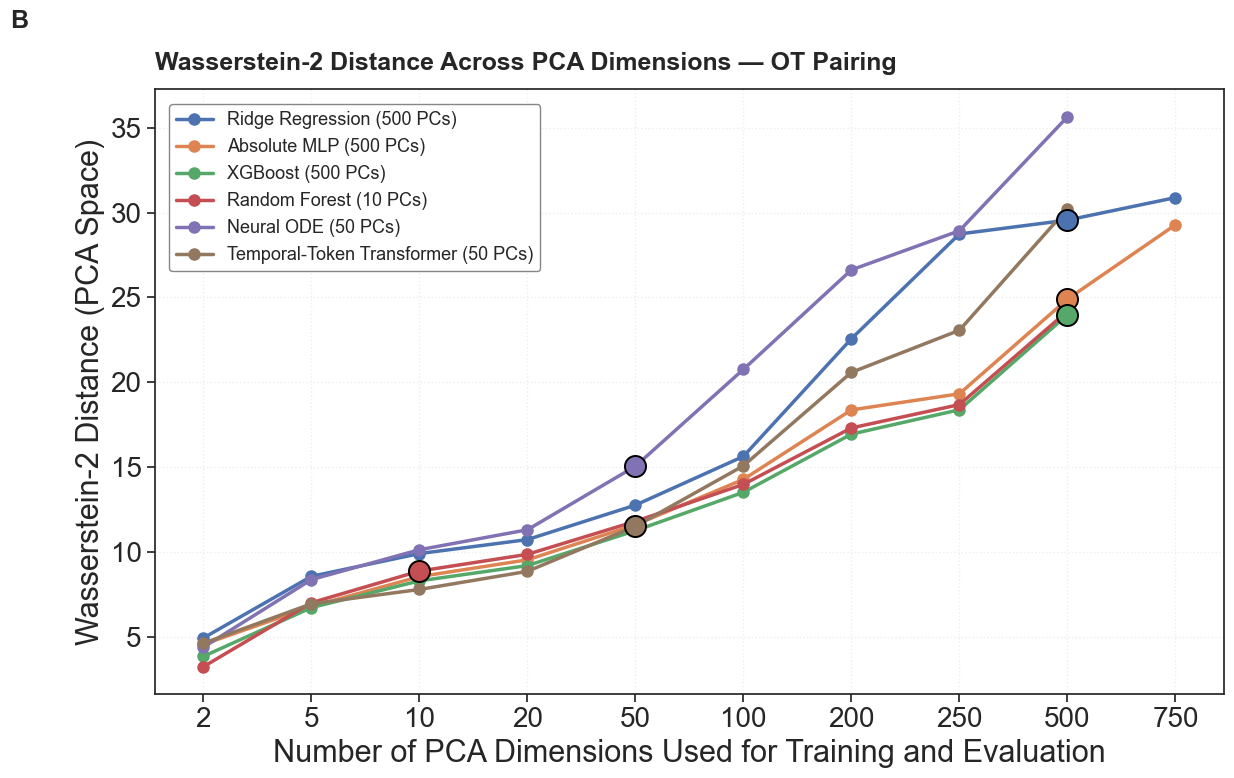

EMT Figure B regenerated with circular markers.
No models were retrained.


: 

In [ ]:

# =========================================================
# EMT FIGURE B — WASSERSTEIN-2 VS PCA DIMENSIONS
# Replot only: circular markers instead of diamonds
# No model retraining
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Exact checkpoint filename from the EMT sweep
CHECKPOINT = "EMT_OT_PCA_Wasserstein2_Sweep_750.csv"
SAVE_DPI = 300

PC_GRID = [2, 5, 10, 20, 50, 100, 200, 250, 500, 750]

ORIGINAL_PCS = {
    "Ridge Regression": 500,
    "Absolute MLP": 500,
    "XGBoost": 500,
    "Random Forest": 10,
    "Neural ODE": 50,
    "Temporal-Token Transformer": 50,
}

MODEL_ORDER = list(ORIGINAL_PCS)

# Load saved Wasserstein results
results = pd.read_csv(CHECKPOINT)

assert len(results) == 56, (
    f"Expected 56 configurations, found {len(results)}"
)

# =========================================================
# CREATE FIGURE B
# =========================================================

fig, ax = plt.subplots(figsize=(16, 8))

position = {
    pc: i for i, pc in enumerate(PC_GRID)
}

for name in MODEL_ORDER:

    subset = results.loc[
        results["Model"] == name
    ].sort_values("PCs")

    x_positions = [
        position[int(pc)] for pc in subset["PCs"]
    ]

    line, = ax.plot(
        x_positions,
        subset["Wasserstein_2"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=f"{name} ({ORIGINAL_PCS[name]} PCs)"
    )

    # Highlight original selected dimension with a larger circle
    selected_pc = ORIGINAL_PCS[name]

    selected = subset.loc[
        subset["PCs"] == selected_pc
    ].iloc[0]

    ax.scatter(
        position[selected_pc],
        selected["Wasserstein_2"],
        s=230,
        marker="o",
        color=line.get_color(),
        edgecolors="black",
        linewidths=1.4,
        zorder=6
    )

# =========================================================
# PUBLICATION FORMATTING
# =========================================================

ax.set_title(
    "Wasserstein-2 Distance Across PCA Dimensions — OT Pairing",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel(
    "Number of PCA Dimensions Used for Training and Evaluation",
    fontsize=22
)

ax.set_ylabel(
    "Wasserstein-2 Distance (PCA Space)",
    fontsize=22
)

ax.set_xticks(np.arange(len(PC_GRID)))
ax.set_xticklabels(PC_GRID, fontsize=20)

ax.tick_params(axis="y", labelsize=20)

ax.grid(
    True,
    linestyle=":",
    alpha=0.35
)


# Legend inside the graph, upper-left corner
ax.legend(
    loc="upper left",
    fontsize=13,
    frameon=True,
    framealpha=0.95,
    edgecolor="gray",
    borderaxespad=0.8
)


fig.text(
    0.01, 0.99, "B",
    fontsize=18,
    fontweight="bold",
    va="top"
)

plt.tight_layout(rect=[0.04, 0.02, 0.78, 0.96])

# Overwrite original EMT Figure B
plt.savefig(
    "EMT_Figure_B_OT_PCA_Wasserstein2_Sweep.png",
    dpi=SAVE_DPI,
    bbox_inches="tight"
)

plt.show()

print("EMT Figure B regenerated with circular markers.")
print("No models were retrained.")


EMT TRAINING-ONLY SIX-MODEL PCA SWEEP
Models: Ridge + MLP + XGBoost + Random Forest + Neural ODE + Transformer
Model hyperparameters: transferred unchanged from primary dataset
Selection: model-specific Top-100 HVG T6 validation Pearson r²
Fixed EMT OT settings: reg=0.01, cap=2
Ridge / MLP evaluated through 1000 PCs
XGBoost / Random Forest / Neural ODE / Transformer stop at 750 PCs
T7 / Day 8 remains completely untouched
PCA dimensions: [10, 25, 50, 100, 250, 500, 750, 1000]
Heavy-model dimensions: [10, 25, 50, 100, 250, 500, 750]
Fixed Sinkhorn reg: 0.01
Fixed target cap: 2

T0 cells: 383
T7 / Day 8 present: False

Outer T0 split:
Final-training T0 cells: 306
Final-test T0 cells: 77

PCA-sweep inner split:
Inner training T0 cells: 244
Inner validation T0 cells: 62
Final held-out T0 cells: 77
✓ Final T0 test cells excluded from sweep model training/validation
✓ Inner train / validation split is disjoint
✓ T7 / Day 8 absent

Biological matrix: (1869, 2000)
HVG count: 2000

Standardizati

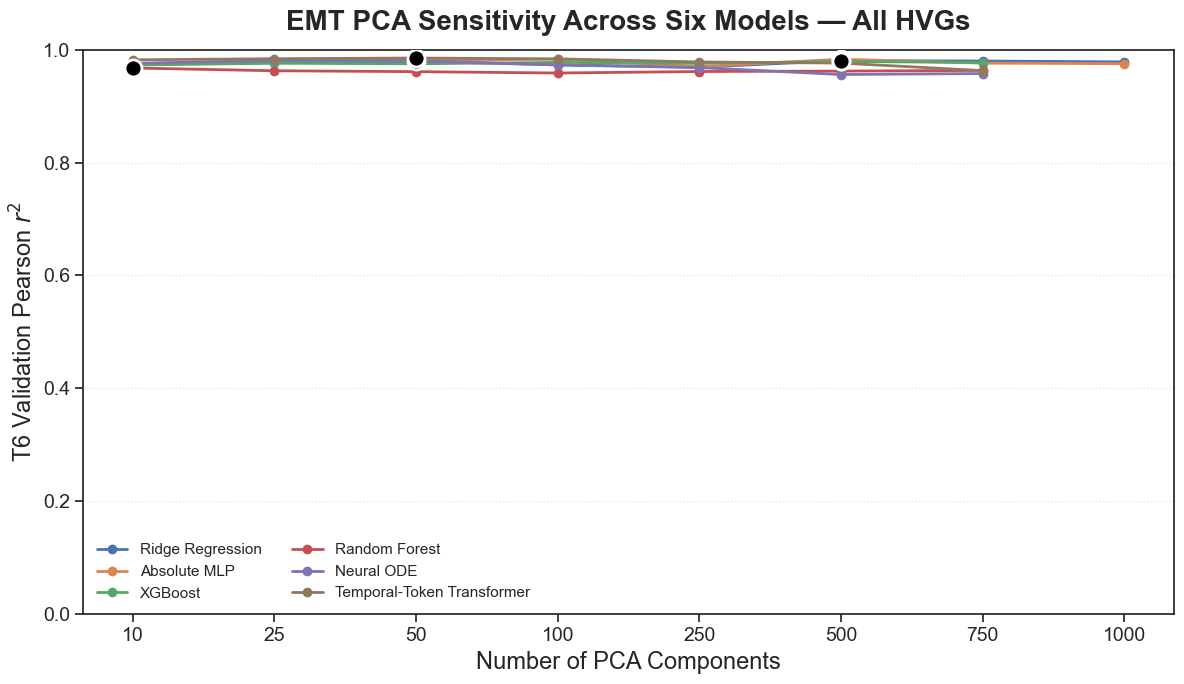

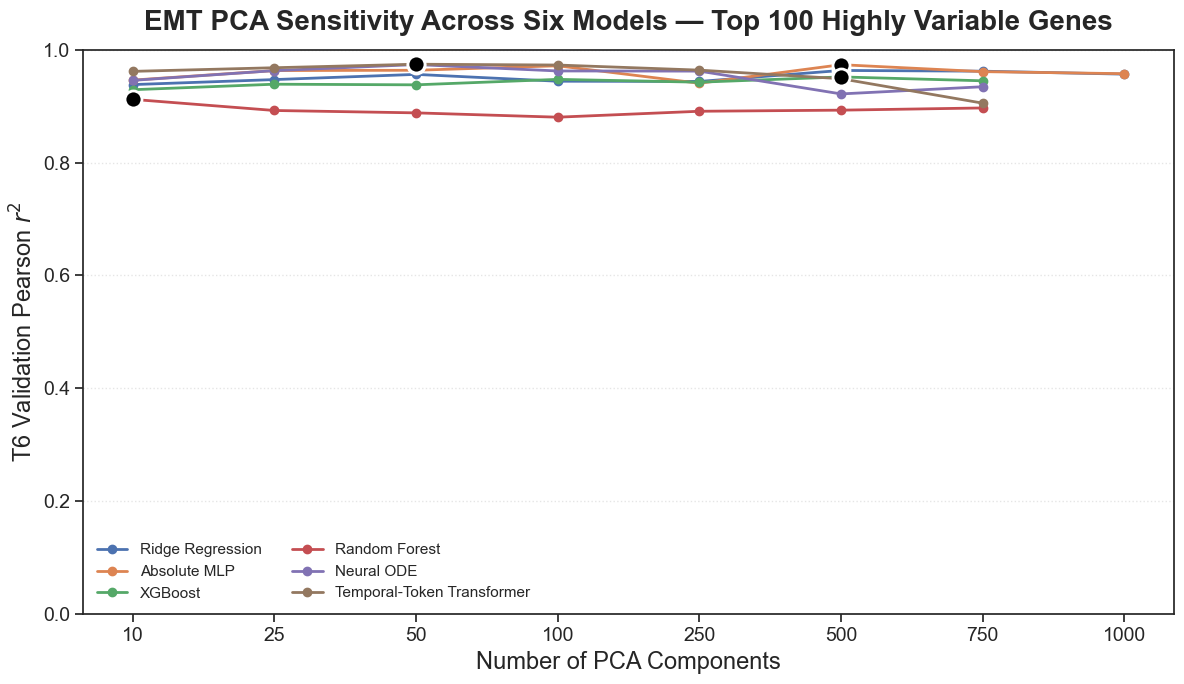

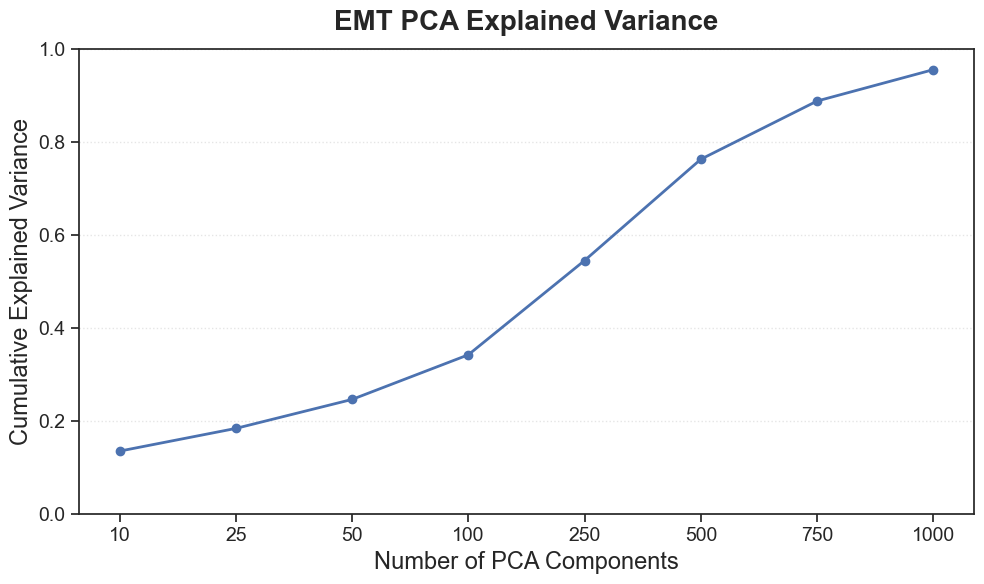


Saved:
EMT_six_model_pca_sweep_reg001_cap2.csv
EMT_six_model_pca_sweep_allHVG.png
EMT_six_model_pca_sweep_top100.png
EMT_pca_sweep_explained_variance.png

EMT PCA SWEEP LEAKAGE AUDIT
T6 used in standardization fitting: False
T6 used in PCA fitting: False
T7 / Day 8 present in sweep cohort: False
Final T0 test cells used for model training: False
Final T0 test cells used for validation: False
Top-100 genes selected using T6: False
Top-100 genes selected using T7: False

✔ EMT OT regularization fixed at 0.01
✔ EMT target-use cap fixed at 2
✔ OT hyperparameters are not retuned during PCA sweep
✔ Primary-dataset model architectures/hyperparameters transferred to EMT
✔ Ridge: alpha=10
✔ MLP: 2×128 GELU, dropout=0.2, lr=0.003, 120 epochs
✔ XGBoost: 30 trees, depth=3, lr=0.05, subsample=0.8, colsample=0.8
✔ Random Forest: 20 trees, depth=4, max_features=0.5
✔ Neural ODE: 2×128 GELU, Tanh×2, 6 Euler steps, lr=0.002, wd=1e-3, 60 epochs, batch=512
✔ Transformer: token size=5, d_model=32, 4 head

In [ ]:
# =========================================================
# EMT TRAINING-ONLY SIX-MODEL PCA SWEEP
#
# OT SETTINGS FIXED FROM EMT OT HYPERPARAMETER SWEEP:
#   Sinkhorn regularization = 0.01
#   Target-use cap = 2
#
# MODEL CONFIGURATIONS:
#   Same architectures / training hyperparameters as primary dataset
#
# PCA SELECTION:
#   Independently for each model
#   Primary criterion = Top-100 HVG T6 validation Pearson r²
#
# T7 / DAY 8 REMAINS COMPLETELY SEALED
# =========================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
import torch
import torch.nn as nn

from scipy.stats import pearsonr
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

print("=" * 90)
print("EMT TRAINING-ONLY SIX-MODEL PCA SWEEP")
print("Models: Ridge + MLP + XGBoost + Random Forest + Neural ODE + Transformer")
print("Model hyperparameters: transferred unchanged from primary dataset")
print("Selection: model-specific Top-100 HVG T6 validation Pearson r²")
print("Fixed EMT OT settings: reg=0.01, cap=2")
print("Ridge / MLP evaluated through 1000 PCs")
print("XGBoost / Random Forest / Neural ODE / Transformer stop at 750 PCs")
print("T7 / Day 8 remains completely untouched")
print("=" * 90)


# =========================================================
# 1. SETTINGS
# =========================================================

pca_dimensions = [10, 25, 50, 100, 250, 500, 750, 1000]
heavy_model_dimensions = [10, 25, 50, 100, 250, 500, 750]

sweep_training_stages = ["T1", "T2", "T3", "T4", "T5"]
sweep_validation_stage = "T6"

sweep_time_mapping = {
    "T0": 0.0,
    "T1": 4 / 24,
    "T2": 1.0,
    "T3": 3.0,
    "T4": 4.0,
    "T5": 5.0,
    "T6": 6.0,
    "T7": 8.0
}

sweep_reg = 0.01
sweep_cap = 2
seed = 42

print("PCA dimensions:", pca_dimensions)
print("Heavy-model dimensions:", heavy_model_dimensions)
print("Fixed Sinkhorn reg:", sweep_reg)
print("Fixed target cap:", sweep_cap)


# =========================================================
# 2. VERIFY EMT DATASET
# =========================================================

samples = np.asarray(adata_processed.obs["sample"])

assert "T7" not in set(samples)
assert np.sum(samples == "T0") == 383

print("\nT0 cells:", np.sum(samples == "T0"))
print("T7 / Day 8 present:", "T7" in set(samples))


# =========================================================
# 3. CREATE OUTER 80/20 T0 SPLIT
#
# 383 total T0 cells
# 306 final-training T0 cells
# 77 final-test T0 cells
# =========================================================

all_source_idx = np.arange(np.sum(samples == "T0"))

train_source_idx, test_source_idx = train_test_split(all_source_idx, test_size=0.20, random_state=42)

train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

print("\nOuter T0 split:")
print("Final-training T0 cells:", len(train_source_idx))
print("Final-test T0 cells:", len(test_source_idx))

assert len(train_source_idx) == 306
assert len(test_source_idx) == 77
assert len(set(train_source_idx) & set(test_source_idx)) == 0


# =========================================================
# 4. CREATE INNER PCA-SWEEP TRAIN / VALIDATION SPLIT
#
# Only the 306 outer-training T0 cells are split here.
# =========================================================

sweep_train_source_idx, sweep_val_source_idx = train_test_split(train_source_idx, test_size=0.20, random_state=123)

sweep_train_source_idx = np.sort(sweep_train_source_idx)
sweep_val_source_idx = np.sort(sweep_val_source_idx)

print("\nPCA-sweep inner split:")
print("Inner training T0 cells:", len(sweep_train_source_idx))
print("Inner validation T0 cells:", len(sweep_val_source_idx))
print("Final held-out T0 cells:", len(test_source_idx))

assert len(sweep_train_source_idx) == 244
assert len(sweep_val_source_idx) == 62
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0
assert len(set(sweep_train_source_idx) & set(sweep_val_source_idx)) == 0
assert len(sweep_train_source_idx) + len(sweep_val_source_idx) == len(train_source_idx)

print("✓ Final T0 test cells excluded from sweep model training/validation")
print("✓ Inner train / validation split is disjoint")
print("✓ T7 / Day 8 absent")


# =========================================================
# 5. BIOLOGICAL EXPRESSION MATRIX
# =========================================================

hvg_names = list(adata_processed.var_names)

X_bio_all = adata_processed.raw[:, hvg_names].X
X_bio_all = X_bio_all.toarray() if hasattr(X_bio_all, "toarray") else np.asarray(X_bio_all)
X_bio_all = np.asarray(X_bio_all, dtype=np.float64)

assert X_bio_all.shape[1] == 2000

print("\nBiological matrix:", X_bio_all.shape)
print("HVG count:", len(hvg_names))


# =========================================================
# 6. TRAINING-ONLY STANDARDIZATION
#
# Fit only T0-T5.
# T6 = validation only.
# T7 = absent.
# =========================================================

fit_stages = ["T0", "T1", "T2", "T3", "T4", "T5"]

standardization_mask = np.isin(samples, fit_stages)
X_standardization_fit = X_bio_all[standardization_mask]

sweep_mean = X_standardization_fit.mean(axis=0)
sweep_std = X_standardization_fit.std(axis=0)
sweep_std[sweep_std == 0] = 1.0

X_scaled_all = (X_bio_all - sweep_mean) / sweep_std
X_scaled_all = np.clip(X_scaled_all, -10, 10)

print("\nStandardization fitting matrix:", X_standardization_fit.shape)


# =========================================================
# 7. PCA FIT COHORT
#
# PCA sees T0-T5 only.
# =========================================================

pca_fit_mask = np.isin(samples, fit_stages)
X_pca_fit = X_scaled_all[pca_fit_mask]

print("PCA fitting matrix:", X_pca_fit.shape)


# =========================================================
# 8. T6 VALIDATION TRUTH
# =========================================================

t6_mask = samples == sweep_validation_stage
Y_t6_true = X_bio_all[t6_mask]
true_t6_profile = Y_t6_true.mean(axis=0)

print("T6 validation biological matrix:", Y_t6_true.shape)


# =========================================================
# 9. TOP-100 HVGs
#
# Ranked only from T0-T5 training-fit expression variance.
# =========================================================

training_gene_variance = np.var(X_standardization_fit, axis=0, ddof=1)
sweep_top100_idx = np.argsort(training_gene_variance)[-100:]

print("Top-100 genes selected by training-only T0-T5 expression variance.")
print("T6 used for Top-100 selection:", False)
print("T7 used for Top-100 selection:", False)


# =========================================================
# 10. PEARSON r²
# =========================================================

def sweep_pearson_r2(x, y):
    r = pearsonr(np.asarray(x), np.asarray(y))[0]
    return float(r ** 2)


# =========================================================
# 11. CAPPED OT PAIRING
# =========================================================

def sweep_capped_ot(gamma, target_cap=2):
    gamma = np.asarray(gamma, dtype=np.float64)
    n_source, n_target = gamma.shape

    if n_target * target_cap < n_source:
        raise ValueError(f"Target capacity too small: {n_target} × {target_cap} < {n_source}")

    assigned = np.full(n_source, -1, dtype=int)
    usage = np.zeros(n_target, dtype=int)

    confidence = gamma.max(axis=1)
    source_order = np.argsort(confidence)[::-1]

    for src_idx in source_order:
        target_order = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in target_order:
            if usage[tgt_idx] < target_cap:
                assigned[src_idx] = tgt_idx
                usage[tgt_idx] += 1
                break

    if np.any(assigned < 0):
        raise RuntimeError("OT pairing failed.")

    return assigned


# =========================================================
# 12. MLP
#
# SAME AS PRIMARY DATASET:
# 2 × 128 GELU
# dropout = 0.2
# Adam lr = 0.003
# epochs = 120
# =========================================================

class SweepMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)


def train_sweep_mlp(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = SweepMLP(X_train.shape[1], Y_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    Y_tensor = torch.tensor(Y_train, dtype=torch.float32)

    model.train()

    for epoch in range(120):
        optimizer.zero_grad()
        pred = model(X_tensor)
        loss = loss_fn(pred, Y_tensor)
        loss.backward()
        optimizer.step()

    return model


# =========================================================
# 13. NEURAL ODE
#
# SAME AS PRIMARY DATASET:
# PC state + time -> 128 GELU -> 128 GELU -> PC derivative
# bounded derivative = Tanh × 2
# Euler integration = 6 steps
# Adam lr = 0.002
# weight decay = 1e-3
# epochs = 60
# batch size = 512
# =========================================================

class SweepODEFunc(nn.Module):
    def __init__(self, pc_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(pc_dim + 1, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, pc_dim),
            nn.Tanh()
        )

    def forward(self, dt, state):
        return 2.0 * self.net(torch.cat([state, dt], dim=1))


class SweepNeuralODE(nn.Module):
    def __init__(self, pc_dim, euler_steps=6):
        super().__init__()
        self.pc_dim = pc_dim
        self.euler_steps = euler_steps
        self.func = SweepODEFunc(pc_dim)

    def forward(self, x):
        state = x[:, :self.pc_dim]
        total_dt = x[:, self.pc_dim:self.pc_dim + 1]
        step_dt = total_dt / self.euler_steps

        for _ in range(self.euler_steps):
            state = state + self.func(step_dt, state) * step_dt

        return state


def train_sweep_neural_ode(X_train, Y_train, pc_dim, seed=42):
    torch.manual_seed(seed)

    model = SweepNeuralODE(pc_dim=pc_dim, euler_steps=6)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-3)
    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    Y_tensor = torch.tensor(Y_train, dtype=torch.float32)

    dataset = torch.utils.data.TensorDataset(X_tensor, Y_tensor)
    generator = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(dataset, batch_size=512, shuffle=True, generator=generator)

    model.train()

    for epoch in range(60):
        for X_batch, Y_batch in loader:
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = loss_fn(pred, Y_batch)
            loss.backward()
            optimizer.step()

    return model


# =========================================================
# 14. TEMPORAL-TOKEN TRANSFORMER
#
# SAME AS PRIMARY DATASET:
# token size = 5
# d_model = 32
# heads = 4
# FF = 128
# layers = 1
# dropout = 0.1
# GELU
# Adam lr = 0.002
# weight decay = 1e-5
# epochs = 30
# batch size = 512
# =========================================================

class SweepTimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim, output_dim, token_size=5, d_model=32, num_heads=4, ff_dim=128, num_layers=1, dropout=0.1):
        super().__init__()

        self.input_dim = input_dim
        self.token_size = token_size
        self.num_tokens = int(np.ceil(input_dim / token_size))
        self.padded_dim = self.num_tokens * token_size

        self.token_projection = nn.Linear(token_size, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(self.num_tokens * d_model, output_dim)

    def forward(self, x):
        if x.shape[1] < self.padded_dim:
            padding = torch.zeros(x.shape[0], self.padded_dim - x.shape[1], dtype=x.dtype, device=x.device)
            x = torch.cat([x, padding], dim=1)

        x = x.reshape(x.shape[0], self.num_tokens, self.token_size)
        x = self.token_projection(x)
        x = self.transformer_encoder(x)
        x = x.reshape(x.shape[0], -1)
        return self.output_projection(x)


def train_sweep_transformer(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = SweepTimeSeriesTransformer(
        input_dim=X_train.shape[1],
        output_dim=Y_train.shape[1],
        token_size=5,
        d_model=32,
        num_heads=4,
        ff_dim=128,
        num_layers=1,
        dropout=0.1
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-5)
    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    Y_tensor = torch.tensor(Y_train, dtype=torch.float32)

    dataset = torch.utils.data.TensorDataset(X_tensor, Y_tensor)
    generator = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(dataset, batch_size=512, shuffle=True, generator=generator)

    model.train()

    for epoch in range(30):
        for X_batch, Y_batch in loader:
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = loss_fn(pred, Y_batch)
            loss.backward()
            optimizer.step()

    return model


# =========================================================
# 15. STORAGE
# =========================================================

sweep_records = []


# =========================================================
# 16. MAIN EMT PCA SWEEP
# =========================================================

for pc_dim in pca_dimensions:

    print("\n" + "=" * 85)
    print(f"PCA DIMENSION: {pc_dim}")
    print("=" * 85)

    # =====================================================
    # A. FIT PCA — T0-T5 ONLY
    # =====================================================

    pca = PCA(n_components=pc_dim, random_state=seed)
    pca.fit(X_pca_fit)

    X_pca_all = pca.transform(X_scaled_all)
    explained_variance = float(pca.explained_variance_ratio_.sum())

    print("Explained variance:", round(explained_variance, 4))

    # =====================================================
    # B. FULL T0 SOURCE POPULATION
    # =====================================================

    t0_mask = samples == "T0"
    L0 = np.asarray(X_pca_all[t0_mask], dtype=np.float64)

    assert len(L0) == 383

    # =====================================================
    # C. BUILD OT MAPPINGS
    #
    # Fixed EMT-selected settings:
    # reg = 0.01
    # cap = 2
    # =====================================================

    ot_info = {}

    for stage in sweep_training_stages:
        target_mask = samples == stage
        Lt = np.asarray(X_pca_all[target_mask], dtype=np.float64)

        M = ot.dist(L0, Lt, metric="sqeuclidean")

        if M.max() > 0:
            M /= M.max()

        a = np.ones(len(L0), dtype=np.float64) / len(L0)
        b = np.ones(len(Lt), dtype=np.float64) / len(Lt)

        gamma = ot.sinkhorn(a, b, M, reg=sweep_reg, numItermax=5000, stopThr=1e-9)

        pair_idx = sweep_capped_ot(gamma, target_cap=sweep_cap)
        ot_info[stage] = Lt[pair_idx]

        del M, gamma, Lt
        gc.collect()

    # =====================================================
    # D. BUILD INNER TRAINING ARRAYS
    # =====================================================

    X_blocks = []
    Y_blocks = []

    for stage in sweep_training_stages:
        dt = sweep_time_mapping[stage] - sweep_time_mapping["T0"]

        source = L0[sweep_train_source_idx]
        target = ot_info[stage][sweep_train_source_idx]

        X_block = np.hstack([source, np.full((len(sweep_train_source_idx), 1), dt)])

        X_blocks.append(X_block)
        Y_blocks.append(target)

    X_train_sweep = np.vstack(X_blocks)
    Y_train_sweep = np.vstack(Y_blocks)

    print("Sweep training inputs:", X_train_sweep.shape)
    print("Sweep training targets:", Y_train_sweep.shape)

    # =====================================================
    # E. DIRECT HELD-OUT T0 -> T6 VALIDATION
    # =====================================================

    t6_dt = sweep_time_mapping["T6"] - sweep_time_mapping["T0"]

    X_val = np.hstack([
        L0[sweep_val_source_idx],
        np.full((len(sweep_val_source_idx), 1), t6_dt)
    ])

    print("Validation input:", X_val.shape)

    # =====================================================
    # F. INVERSE PCA HELPER
    # =====================================================

    def inverse_sweep(latent):
        scaled = pca.inverse_transform(latent)
        biological = scaled * sweep_std + sweep_mean
        return np.clip(biological, 0, None)

    # =====================================================
    # G. RIDGE
    #
    # SAME AS PRIMARY DATASET:
    # alpha = 10
    # =====================================================

    ridge = Ridge(alpha=10.0)
    ridge.fit(X_train_sweep, Y_train_sweep)

    ridge_latent = ridge.predict(X_val)
    ridge_bio = inverse_sweep(ridge_latent)
    ridge_profile = ridge_bio.mean(axis=0)

    ridge_all = sweep_pearson_r2(true_t6_profile, ridge_profile)
    ridge_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], ridge_profile[sweep_top100_idx])

    print(f"Ridge:        All={ridge_all:.4f} | Top100={ridge_top:.4f}")

    del ridge, ridge_latent, ridge_bio, ridge_profile
    gc.collect()

    # =====================================================
    # H. MLP
    # =====================================================

    mlp = train_sweep_mlp(X_train_sweep, Y_train_sweep, seed=seed)
    mlp.eval()

    with torch.no_grad():
        mlp_latent = mlp(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

    mlp_bio = inverse_sweep(mlp_latent)
    mlp_profile = mlp_bio.mean(axis=0)

    mlp_all = sweep_pearson_r2(true_t6_profile, mlp_profile)
    mlp_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], mlp_profile[sweep_top100_idx])

    print(f"MLP:          All={mlp_all:.4f} | Top100={mlp_top:.4f}")

    del mlp, mlp_latent, mlp_bio, mlp_profile
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # =====================================================
    # I. XGBOOST
    #
    # SAME AS PRIMARY DATASET:
    # trees = 30
    # depth = 3
    # lr = 0.05
    # subsample = 0.8
    # colsample_bytree = 0.8
    #
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    xgb_all = np.nan
    xgb_top = np.nan

    if pc_dim <= 750:
        base_xgb = XGBRegressor(
            n_estimators=30,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=seed,
            n_jobs=1,
            tree_method="hist"
        )

        xgb = MultiOutputRegressor(base_xgb, n_jobs=-1)
        xgb.fit(X_train_sweep, Y_train_sweep)

        xgb_latent = xgb.predict(X_val)
        xgb_bio = inverse_sweep(xgb_latent)
        xgb_profile = xgb_bio.mean(axis=0)

        xgb_all = sweep_pearson_r2(true_t6_profile, xgb_profile)
        xgb_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], xgb_profile[sweep_top100_idx])

        print(f"XGBoost:      All={xgb_all:.4f} | Top100={xgb_top:.4f}")

        del xgb, base_xgb, xgb_latent, xgb_bio, xgb_profile
        gc.collect()

    else:
        print("XGBoost: skipped at 1000 PCs")

    # =====================================================
    # J. HEAVY MODELS DEFAULT TO NaN
    # =====================================================

    rf_all = np.nan
    rf_top = np.nan
    neural_all = np.nan
    neural_top = np.nan
    transformer_all = np.nan
    transformer_top = np.nan

    # =====================================================
    # K. RANDOM FOREST
    #
    # SAME AS PRIMARY DATASET:
    # trees = 20
    # depth = 4
    # max_features = 0.5
    #
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        rf = RandomForestRegressor(
            n_estimators=20,
            max_depth=4,
            max_features=0.5,
            random_state=seed,
            n_jobs=-1
        )

        rf.fit(X_train_sweep, Y_train_sweep)

        rf_latent = rf.predict(X_val)
        rf_bio = inverse_sweep(rf_latent)
        rf_profile = rf_bio.mean(axis=0)

        rf_all = sweep_pearson_r2(true_t6_profile, rf_profile)
        rf_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], rf_profile[sweep_top100_idx])

        print(f"RandomForest: All={rf_all:.4f} | Top100={rf_top:.4f}")

        del rf, rf_latent, rf_bio, rf_profile
        gc.collect()

    else:
        print("RandomForest: skipped at 1000 PCs")

    # =====================================================
    # L. NEURAL ODE
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        neural_ode = train_sweep_neural_ode(X_train_sweep, Y_train_sweep, pc_dim=pc_dim, seed=seed)
        neural_ode.eval()

        with torch.no_grad():
            neural_latent = neural_ode(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

        neural_bio = inverse_sweep(neural_latent)
        neural_profile = neural_bio.mean(axis=0)

        neural_all = sweep_pearson_r2(true_t6_profile, neural_profile)
        neural_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], neural_profile[sweep_top100_idx])

        print(f"NeuralODE:    All={neural_all:.4f} | Top100={neural_top:.4f}")

        del neural_ode, neural_latent, neural_bio, neural_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    else:
        print("NeuralODE: skipped at 1000 PCs")

    # =====================================================
    # M. TRANSFORMER
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        transformer = train_sweep_transformer(X_train_sweep, Y_train_sweep, seed=seed)
        transformer.eval()

        with torch.no_grad():
            transformer_latent = transformer(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

        transformer_bio = inverse_sweep(transformer_latent)
        transformer_profile = transformer_bio.mean(axis=0)

        transformer_all = sweep_pearson_r2(true_t6_profile, transformer_profile)
        transformer_top = sweep_pearson_r2(true_t6_profile[sweep_top100_idx], transformer_profile[sweep_top100_idx])

        print(f"Transformer:  All={transformer_all:.4f} | Top100={transformer_top:.4f}")

        del transformer, transformer_latent, transformer_bio, transformer_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    else:
        print("Transformer: skipped at 1000 PCs")

    # =====================================================
    # N. SAVE RESULT
    # =====================================================

    sweep_records.append({
        "PCA_Dim": pc_dim,
        "Explained_Variance": explained_variance,

        "Ridge_All": ridge_all,
        "MLP_All": mlp_all,
        "XGBoost_All": xgb_all,
        "RandomForest_All": rf_all,
        "NeuralODE_All": neural_all,
        "Transformer_All": transformer_all,

        "Ridge_Top100": ridge_top,
        "MLP_Top100": mlp_top,
        "XGBoost_Top100": xgb_top,
        "RandomForest_Top100": rf_top,
        "NeuralODE_Top100": neural_top,
        "Transformer_Top100": transformer_top
    })

    pd.DataFrame(sweep_records).to_csv("EMT_six_model_pca_sweep_reg001_cap2.csv", index=False)

    del X_pca_all, L0, ot_info, X_train_sweep, Y_train_sweep
    del X_val, X_blocks, Y_blocks, pca
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# =========================================================
# 17. BUILD FINAL SWEEP TABLE
# =========================================================

df_pca_confirmation = pd.DataFrame(sweep_records)


# =========================================================
# 18. MODEL -> RESULT COLUMN MAPPINGS
# =========================================================

all_columns = {
    "Ridge": "Ridge_All",
    "MLP": "MLP_All",
    "XGBoost": "XGBoost_All",
    "RandomForest": "RandomForest_All",
    "NeuralODE": "NeuralODE_All",
    "Transformer": "Transformer_All"
}

top_columns = {
    "Ridge": "Ridge_Top100",
    "MLP": "MLP_Top100",
    "XGBoost": "XGBoost_Top100",
    "RandomForest": "RandomForest_Top100",
    "NeuralODE": "NeuralODE_Top100",
    "Transformer": "Transformer_Top100"
}

display_names = {
    "Ridge": "Ridge Regression",
    "MLP": "Absolute MLP",
    "XGBoost": "XGBoost",
    "RandomForest": "Random Forest",
    "NeuralODE": "Neural ODE",
    "Transformer": "Temporal-Token Transformer"
}


# =========================================================
# 19. SELECT MODEL-SPECIFIC PCA DIMENSIONS
#
# PRIMARY CRITERION:
# Maximum Top-100 T6 validation Pearson r² for each model.
# =========================================================

selected_pca_dimensions = {}
selected_model_results = {}

print("\n" + "=" * 90)
print("MODEL-SPECIFIC EMT PCA SELECTION")
print("Criterion: maximum Top-100 HVG T6 validation Pearson r²")
print("=" * 90)

for model_key, top_column in top_columns.items():
    all_column = all_columns[model_key]
    valid = df_pca_confirmation.dropna(subset=[top_column])

    best_idx = valid[top_column].idxmax()
    best_row = df_pca_confirmation.loc[best_idx]
    selected_dim = int(best_row["PCA_Dim"])

    selected_pca_dimensions[model_key] = selected_dim

    selected_model_results[model_key] = {
        "PCA_Dim": selected_dim,
        "Top100": float(best_row[top_column]),
        "All": float(best_row[all_column])
    }

    print(
        f"{display_names[model_key]}: "
        f"{selected_dim} PCs | "
        f"Top100={best_row[top_column]:.4f} | "
        f"All={best_row[all_column]:.4f}"
    )


# =========================================================
# 20. PRINT FULL TABLE
# =========================================================

print("\n" + "=" * 190)
print("EMT SIX-MODEL PCA SWEEP RESULTS")
print("=" * 190)

print(df_pca_confirmation.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# =========================================================
# 21. PUBLICATION FIGURE — ALL HVGs
#
# Equal categorical spacing between PCA dimensions.
# Each model's selected PCA dimension is highlighted.
# =========================================================

plot_x = np.arange(len(pca_dimensions))
fig, ax = plt.subplots(figsize=(10, 8))

model_plot_columns = {
    "Ridge Regression": ("Ridge", "Ridge_All"),
    "Absolute MLP": ("MLP", "MLP_All"),
    "XGBoost": ("XGBoost", "XGBoost_All"),
    "Random Forest": ("RandomForest", "RandomForest_All"),
    "Neural ODE": ("NeuralODE", "NeuralODE_All"),
    "Temporal-Token Transformer": ("Transformer", "Transformer_All")
}

for model_name, (model_key, column) in model_plot_columns.items():
    values = df_pca_confirmation[column].to_numpy(dtype=float)
    valid_mask = ~np.isnan(values)

    ax.plot(plot_x[valid_mask], values[valid_mask], marker="o", linewidth=2, markersize=6, label=model_name)

    selected_dim = selected_pca_dimensions[model_key]
    selected_position = pca_dimensions.index(selected_dim)
    selected_value = df_pca_confirmation.loc[df_pca_confirmation["PCA_Dim"] == selected_dim, column].iloc[0]

    ax.scatter(selected_position, selected_value, s=150, color="black", edgecolor="white", linewidth=2, zorder=10)

ax.set_title("EMT PCA Sensitivity Across Six Models — All HVGs", fontsize=20, fontweight="bold", pad=14)
ax.set_xlabel("Number of PCA Components", fontsize=17)
ax.set_ylabel("T6 Validation Pearson $r^2$", fontsize=17)
ax.set_xticks(plot_x)
ax.set_xticklabels(pca_dimensions, fontsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False, fontsize=11, ncol=2)

plt.tight_layout()
plt.savefig("EMT_six_model_pca_sweep_allHVG.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# 22. PUBLICATION FIGURE — TOP 100 HVGs
#
# PRIMARY PCA-SELECTION FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))

model_plot_columns_top = {
    "Ridge Regression": ("Ridge", "Ridge_Top100"),
    "Absolute MLP": ("MLP", "MLP_Top100"),
    "XGBoost": ("XGBoost", "XGBoost_Top100"),
    "Random Forest": ("RandomForest", "RandomForest_Top100"),
    "Neural ODE": ("NeuralODE", "NeuralODE_Top100"),
    "Temporal-Token Transformer": ("Transformer", "Transformer_Top100")
}

for model_name, (model_key, column) in model_plot_columns_top.items():
    values = df_pca_confirmation[column].to_numpy(dtype=float)
    valid_mask = ~np.isnan(values)

    ax.plot(plot_x[valid_mask], values[valid_mask], marker="o", linewidth=2, markersize=6, label=model_name)

    selected_dim = selected_pca_dimensions[model_key]
    selected_position = pca_dimensions.index(selected_dim)
    selected_value = df_pca_confirmation.loc[df_pca_confirmation["PCA_Dim"] == selected_dim, column].iloc[0]

    ax.scatter(selected_position, selected_value, s=150, color="black", edgecolor="white", linewidth=2, zorder=10)

ax.set_title("EMT PCA Sensitivity Across Six Models — Top 100 Highly Variable Genes", fontsize=20, fontweight="bold", pad=14)
ax.set_xlabel("Number of PCA Components", fontsize=17)
ax.set_ylabel("T6 Validation Pearson $r^2$", fontsize=17)
ax.set_xticks(plot_x)
ax.set_xticklabels(pca_dimensions, fontsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False, fontsize=11, ncol=2)

plt.tight_layout()
plt.savefig("EMT_six_model_pca_sweep_top100.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# 23. EXPLAINED VARIANCE FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(plot_x, df_pca_confirmation["Explained_Variance"], marker="o", linewidth=2)

ax.set_title("EMT PCA Explained Variance", fontsize=20, fontweight="bold", pad=14)
ax.set_xlabel("Number of PCA Components", fontsize=17)
ax.set_ylabel("Cumulative Explained Variance", fontsize=17)
ax.set_xticks(plot_x)
ax.set_xticklabels(pca_dimensions, fontsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("EMT_pca_sweep_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# 24. SAVE FINAL TABLE
# =========================================================

df_pca_confirmation.to_csv("EMT_six_model_pca_sweep_reg001_cap2.csv", index=False)

print("\nSaved:")
print("EMT_six_model_pca_sweep_reg001_cap2.csv")
print("EMT_six_model_pca_sweep_allHVG.png")
print("EMT_six_model_pca_sweep_top100.png")
print("EMT_pca_sweep_explained_variance.png")


# =========================================================
# 25. FINAL LEAKAGE AUDIT
# =========================================================

print("\n" + "=" * 85)
print("EMT PCA SWEEP LEAKAGE AUDIT")
print("=" * 85)

print("T6 used in standardization fitting:", "T6" in set(samples[standardization_mask]))
print("T6 used in PCA fitting:", "T6" in set(samples[pca_fit_mask]))
print("T7 / Day 8 present in sweep cohort:", "T7" in set(samples))
print("Final T0 test cells used for model training:", len(set(test_source_idx) & set(sweep_train_source_idx)) > 0)
print("Final T0 test cells used for validation:", len(set(test_source_idx) & set(sweep_val_source_idx)) > 0)
print("Top-100 genes selected using T6:", False)
print("Top-100 genes selected using T7:", False)

assert "T6" not in set(samples[standardization_mask])
assert "T6" not in set(samples[pca_fit_mask])
assert "T7" not in set(samples)
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0


# =========================================================
# 26. FINAL STATUS
# =========================================================

print("\n✔ EMT OT regularization fixed at 0.01")
print("✔ EMT target-use cap fixed at 2")
print("✔ OT hyperparameters are not retuned during PCA sweep")
print("✔ Primary-dataset model architectures/hyperparameters transferred to EMT")
print("✔ Ridge: alpha=10")
print("✔ MLP: 2×128 GELU, dropout=0.2, lr=0.003, 120 epochs")
print("✔ XGBoost: 30 trees, depth=3, lr=0.05, subsample=0.8, colsample=0.8")
print("✔ Random Forest: 20 trees, depth=4, max_features=0.5")
print("✔ Neural ODE: 2×128 GELU, Tanh×2, 6 Euler steps, lr=0.002, wd=1e-3, 60 epochs, batch=512")
print("✔ Transformer: token size=5, d_model=32, 4 heads, 1 layer, FF=128, dropout=0.1, GELU, lr=0.002, wd=1e-5, 30 epochs, batch=512")
print("✔ T0-T5 used for standardization and PCA fitting")
print("✔ T1-T5 used as supervised forecasting targets")
print("✔ T6 used only as PCA-selection validation endpoint")
print("✔ T7 / Day 8 completely absent from the sweep")
print("✔ Top-100 genes selected by training-only T0-T5 expression variance")
print("✔ PCA dimensions tested: 10, 25, 50, 100, 250, 500, 750, 1000")
print("✔ Ridge evaluated through 1000 PCs")
print("✔ MLP evaluated through 1000 PCs")
print("✔ XGBoost evaluated only through 750 PCs")
print("✔ Random Forest evaluated only through 750 PCs")
print("✔ Neural ODE evaluated only through 750 PCs")
print("✔ Transformer evaluated only through 750 PCs")
print("✔ 1000-PC values for XGBoost / RF / ODE / Transformer left as NaN")
print("✔ PCA dimension selected independently for every model")
print("✔ PCA selection criterion = maximum Top-100 T6 validation Pearson r²")
print("✔ All-HVG performance retained as a secondary metric")
print("✔ Sinkhorn maximum iterations = 5000")
print("✔ Sinkhorn convergence threshold = 1e-9")

print("\nFINAL MODEL-SPECIFIC EMT PCA DIMENSIONS:")

for model_key in ["Ridge", "MLP", "XGBoost", "RandomForest", "NeuralODE", "Transformer"]:
    result = selected_model_results[model_key]
    print(
        f"{display_names[model_key]}: "
        f"{result['PCA_Dim']} PCs | "
        f"Top100={result['Top100']:.4f} | "
        f"All={result['All']:.4f}"
    )

EMT TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP
Models: XGBoost + MLP
Fixed PCA: 500 PCs
Training transitions: T0 -> T1/T2/T3/T4/T5
Validation endpoint: T6
Final T7 remains completely untouched
Fixed PCA dimensions: 500
Sinkhorn regularization values: [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0]
Target-use caps: [1, 2, 3, 5]

Outer final-training T0 cells: 306
Outer final-test T0 cells: 77

Inner training T0 cells: 244
Inner validation T0 cells: 62
Final T0 test cells: 77
✓ Outer final-test cells excluded
✓ Inner train/validation split created
✓ T7 absent

Biological expression matrix: (1869, 2000)
HVG count: 2000
Standardization fitting matrix: (1598, 2000)
Explained variance at 500 PCs: 0.7637
T0 source population: (383, 500)
T6 truth: (271, 2000)
Validation input: (62, 501)
Top-100 genes selected by training-only variance across T0-T5.

--- reg=1e-05 | cap=1 ---
Skipping: cap=1 infeasible for T1

--- reg=1e-05 | cap=2 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9714 | MLP All=0.9675 | Mean=0.9695
XGBoost Top100=0.9386 | MLP Top100=0.9440 | Mean=0.9413

--- reg=1e-05 | cap=3 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9396 | MLP All=0.9111 | Mean=0.9254
XGBoost Top100=0.8562 | MLP Top100=0.8149 | Mean=0.8355

--- reg=1e-05 | cap=5 ---


...

Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9698 | MLP All=0.9348 | Mean=0.9523
XGBoost Top100=0.9336 | MLP Top100=0.8715 | Mean=0.9026

--- reg=0.0001 | cap=3 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: overflow encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9532 | MLP All=0.9384 | Mean=0.9458
XGBoost Top100=0.8901 | MLP Top100=0.8894 | Mean=0.8897

--- reg=0.0001 | cap=5 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: overflow encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9489 | MLP All=0.8957 | Mean=0.9223
XGBoost Top100=0.8892 | MLP Top100=0.8251 | Mean=0.8572

--- reg=0.001 | cap=1 ---
Skipping: cap=1 infeasible for T1

--- reg=0.001 | cap=2 ---
Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9844 | MLP All=0.9732 | Mean=0.9788
XGBoost Top100=0.9693 | MLP Top100=0.9539 | Mean=0.9616

--- reg=0.001 | cap=3 ---
Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9839 | MLP All=0.9757 | Mean=0.9798
XGBoost Top100=0.9680 | MLP Top100=0.9588 | Mean=0.9634

--- reg=0.001 | cap=5 ---
Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9839 | MLP All=0.9757 | Mean=0.9798
XGBoost Top100=0.9680 | MLP Top100=0.9588 | Mean=0.9634

--- reg=0.01 | cap=1 ---
Skipping: cap=1 infeasible for T1

--- reg=0.01 | cap=2 ---
Training inputs: (1220, 501)
Training targets: (1220, 500)
XGBoost All=0.9841 | MLP All=0.9830 | Mean=0.9835
XGB

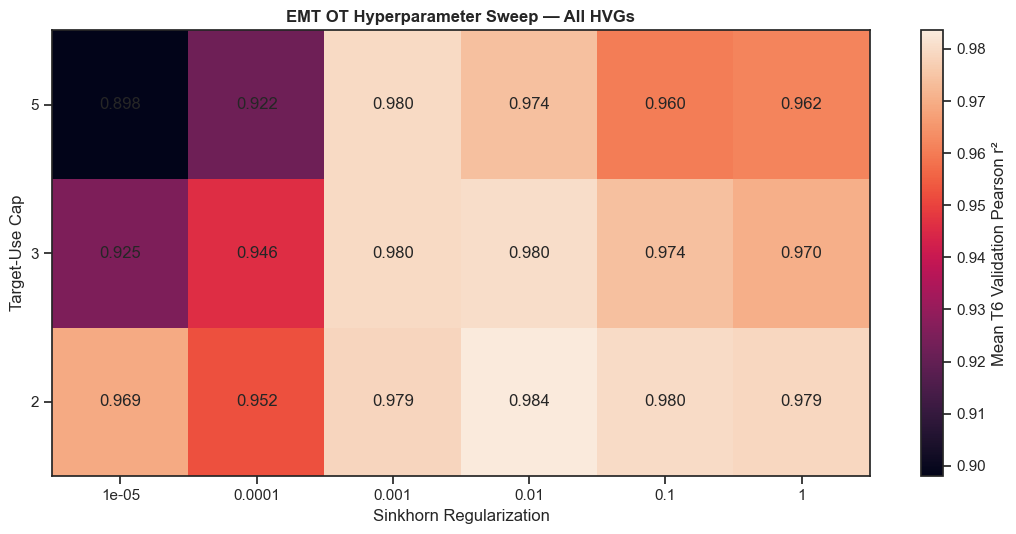

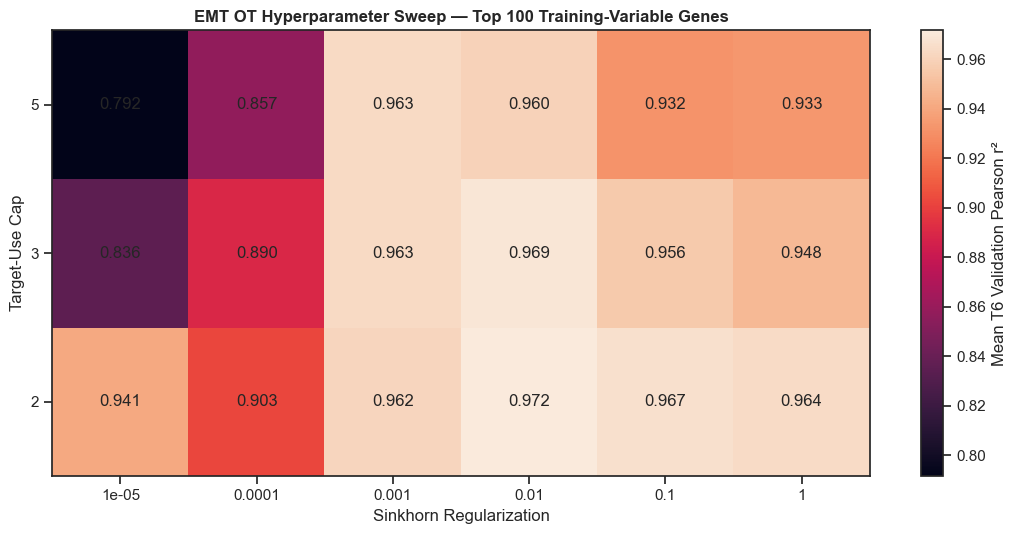

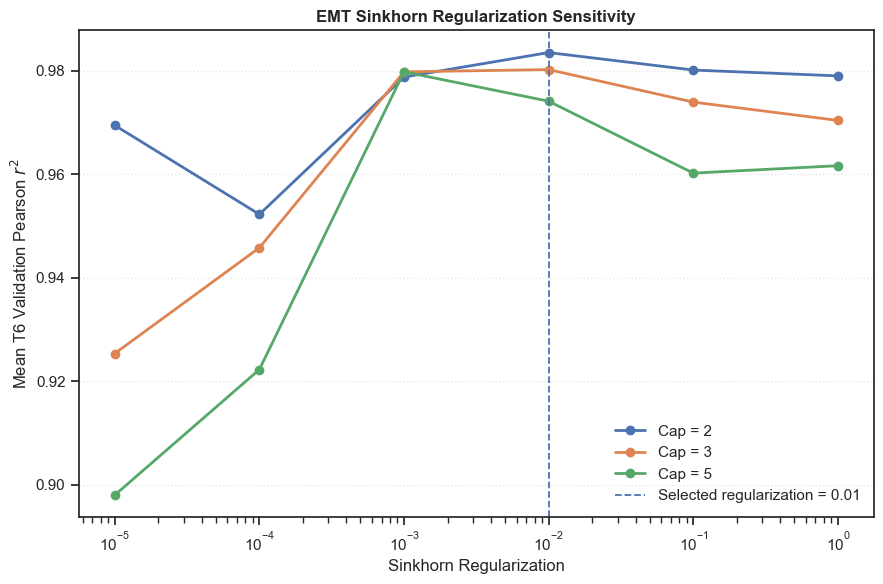


Saved:
EMT_multimodel_ot_hyperparameter_sweep_500PC.csv
EMT_publication_ot_sweep_allHVG_500PC.png
EMT_publication_ot_sweep_top100_500PC.png
EMT_publication_ot_sweep_regularization_500PC.png

EMT OT HYPERPARAMETER SWEEP LEAKAGE AUDIT
T6 used for standardization/PCA fitting: False
T7 present in sweep cohort: False
Final T0 test cells used for sweep training: False
Final T0 test cells used for sweep validation: False
Top-100 genes selected using T6: False
Top-100 genes selected using T7: False

✔ Outer 80/20 T0 split recreated inside this block
✔ Inner training/validation split recreated inside this block
✔ 244 T0 cells used for sweep model training
✔ 62 T0 cells used for T6 validation
✔ 77 final T0 test cells untouched
✔ PCA locked at 500 PCs
✔ PCA fit only on T0-T5
✔ XGBoost and MLP used for OT hyperparameter selection
✔ 6 Sinkhorn regularization values tested
✔ 4 target-use caps considered
✔ Up to 24 OT configurations considered
✔ Primary selection uses mean All-HVG Pearson r²
✔ Top-1

In [14]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
import torch
import torch.nn as nn

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from scipy.stats import pearsonr

print("=" * 90)
print("EMT TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP")
print("Models: XGBoost + MLP")
print("Fixed PCA: 500 PCs")
print("Training transitions: T0 -> T1/T2/T3/T4/T5")
print("Validation endpoint: T6")
print("Final T7 remains completely untouched")
print("=" * 90)

# =========================================================
# 1. SETTINGS
# =========================================================

pc_dim = 500
reg_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
cap_values = [1, 2, 3, 5]

train_stages = ["T1", "T2", "T3", "T4", "T5"]
validation_stage = "T6"

time_mapping = {
    "T0": 0.0,
    "T1": 4 / 24,
    "T2": 1.0,
    "T3": 3.0,
    "T4": 4.0,
    "T5": 5.0,
    "T6": 6.0,
    "T7": 8.0
}

seed = 42

print("Fixed PCA dimensions:", pc_dim)
print("Sinkhorn regularization values:", reg_values)
print("Target-use caps:", cap_values)

# =========================================================
# 2. DATASET + OUTER T0 SPLIT
# =========================================================

samples = np.asarray(adata_processed.obs["sample"])
control_mask = samples == "T0"

assert np.sum(control_mask) == 383
assert "T7" not in set(samples)

all_source_idx = np.arange(np.sum(control_mask))

train_source_idx, test_source_idx = train_test_split(
    all_source_idx,
    test_size=0.20,
    random_state=42
)

train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

assert len(train_source_idx) == 306
assert len(test_source_idx) == 77
assert len(set(train_source_idx) & set(test_source_idx)) == 0

print("\nOuter final-training T0 cells:", len(train_source_idx))
print("Outer final-test T0 cells:", len(test_source_idx))

# =========================================================
# 3. INNER TRAIN / VALIDATION SPLIT
# =========================================================

sweep_train_source_idx, sweep_val_source_idx = train_test_split(
    train_source_idx,
    test_size=0.20,
    random_state=123
)

sweep_train_source_idx = np.sort(sweep_train_source_idx)
sweep_val_source_idx = np.sort(sweep_val_source_idx)

print("\nInner training T0 cells:", len(sweep_train_source_idx))
print("Inner validation T0 cells:", len(sweep_val_source_idx))
print("Final T0 test cells:", len(test_source_idx))

assert len(sweep_train_source_idx) == 244
assert len(sweep_val_source_idx) == 62
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0
assert len(set(sweep_train_source_idx) & set(sweep_val_source_idx)) == 0
assert len(sweep_train_source_idx) + len(sweep_val_source_idx) == len(train_source_idx)

print("✓ Outer final-test cells excluded")
print("✓ Inner train/validation split created")
print("✓ T7 absent")

# =========================================================
# 4. BIOLOGICAL EXPRESSION
# =========================================================

hvg_names = list(adata_processed.var_names)

X_bio_all = adata_processed.raw[:, hvg_names].X
X_bio_all = X_bio_all.toarray() if hasattr(X_bio_all, "toarray") else np.asarray(X_bio_all)
X_bio_all = np.asarray(X_bio_all, dtype=np.float64)

assert X_bio_all.shape[1] == 2000

print("\nBiological expression matrix:", X_bio_all.shape)
print("HVG count:", len(hvg_names))

# =========================================================
# 5. TRAINING-ONLY STANDARDIZATION
#
# T6 = validation only
# T7 = absent
# =========================================================

fit_stages = ["T0", "T1", "T2", "T3", "T4", "T5"]
fit_mask = np.isin(samples, fit_stages)

X_fit_bio = X_bio_all[fit_mask]

sweep_mean = X_fit_bio.mean(axis=0)
sweep_std = X_fit_bio.std(axis=0)
sweep_std[sweep_std == 0] = 1.0

X_scaled_all = (X_bio_all - sweep_mean) / sweep_std
X_scaled_all = np.clip(X_scaled_all, -10, 10)

print("Standardization fitting matrix:", X_fit_bio.shape)

# =========================================================
# 6. FIT LOCKED 500-PC PCA
#
# PCA is fit only on T0-T5.
# T6 is transform-only validation.
# T7 is absent.
# =========================================================

pca_ot_sweep = PCA(n_components=pc_dim, random_state=seed)
pca_ot_sweep.fit(X_scaled_all[fit_mask])

X_all_pca = pca_ot_sweep.transform(X_scaled_all)
explained_variance = float(pca_ot_sweep.explained_variance_ratio_.sum())

print("Explained variance at 500 PCs:", round(explained_variance, 4))

# =========================================================
# 7. T0 SOURCE
# =========================================================

L0 = np.asarray(X_all_pca[control_mask], dtype=np.float64)

assert len(L0) == 383

print("T0 source population:", L0.shape)

# =========================================================
# 8. T6 VALIDATION INPUT + TRUTH
# =========================================================

t6_mask = samples == validation_stage

Y_t6_true = X_bio_all[t6_mask]
true_profile = Y_t6_true.mean(axis=0)

t6_dt = time_mapping["T6"] - time_mapping["T0"]
X_val = np.hstack([
    L0[sweep_val_source_idx],
    np.full((len(sweep_val_source_idx), 1), t6_dt)
])

print("T6 truth:", Y_t6_true.shape)
print("Validation input:", X_val.shape)

# =========================================================
# 9. TOP-100 TRAINING-VARIANCE GENES
#
# Ranked only from T0-T5 biological expression.
# T6 and T7 are excluded.
# =========================================================

training_gene_variance = np.var(X_fit_bio, axis=0, ddof=1)
top100_idx = np.argsort(training_gene_variance)[-100:]

assert len(top100_idx) == 100

print("Top-100 genes selected by training-only variance across T0-T5.")

# =========================================================
# 10. PEARSON r²
# =========================================================

def hp_pearson_r2(x, y):
    r = pearsonr(np.asarray(x), np.asarray(y))[0]
    return float(r ** 2)

# =========================================================
# 11. CAPPED OT PAIRING
# =========================================================

def hp_capped_ot(gamma, cap):
    gamma = np.asarray(gamma, dtype=np.float64)
    n_source, n_target = gamma.shape

    if n_target * cap < n_source:
        raise ValueError("Target capacity too small.")

    assigned = np.full(n_source, -1, dtype=int)
    usage = np.zeros(n_target, dtype=int)
    source_order = np.argsort(gamma.max(axis=1))[::-1]

    for src_idx in source_order:
        target_order = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in target_order:
            if usage[tgt_idx] < cap:
                assigned[src_idx] = tgt_idx
                usage[tgt_idx] += 1
                break

    if np.any(assigned < 0):
        raise RuntimeError("OT pairing failed.")

    return assigned

# =========================================================
# 12. MLP
# =========================================================

class OTSweepMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)

def train_ot_sweep_mlp(X, Y, seed=42):
    torch.manual_seed(seed)

    model = OTSweepMLP(X.shape[1], Y.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

    X_tensor = torch.tensor(X, dtype=torch.float32)
    Y_tensor = torch.tensor(Y, dtype=torch.float32)

    model.train()

    for epoch in range(120):
        optimizer.zero_grad()
        prediction = model(X_tensor)
        loss = nn.functional.mse_loss(prediction, Y_tensor)
        loss.backward()
        optimizer.step()

    return model

# =========================================================
# 13. STORAGE
# =========================================================

ot_hp_results = []

# =========================================================
# 14. REG × CAP SWEEP
# =========================================================

for reg in reg_values:

    for cap_value in cap_values:

        print(f"\n--- reg={reg} | cap={cap_value} ---")

        X_blocks = []
        Y_blocks = []
        valid_setting = True

        # =================================================
        # BUILD OT TRAINING PAIRS
        # =================================================

        for stage in train_stages:
            target_mask = samples == stage
            Lt = np.asarray(X_all_pca[target_mask], dtype=np.float64)

            if len(Lt) * cap_value < len(L0):
                print(f"Skipping: cap={cap_value} infeasible for {stage}")
                valid_setting = False
                break

            M = ot.dist(L0, Lt, metric="sqeuclidean")
            M /= M.max() if M.max() > 0 else 1

            a = np.ones(len(L0), dtype=np.float64) / len(L0)
            b = np.ones(len(Lt), dtype=np.float64) / len(Lt)

            gamma = ot.sinkhorn(
                a,
                b,
                M,
                reg=reg,
                numItermax=5000,
                stopThr=1e-9
            )

            pair_idx = hp_capped_ot(gamma, cap_value)
            paired_targets = Lt[pair_idx]

            source_train = L0[sweep_train_source_idx]
            target_train = paired_targets[sweep_train_source_idx]

            dt = time_mapping[stage] - time_mapping["T0"]

            X_block = np.hstack([
                source_train,
                np.full((len(sweep_train_source_idx), 1), dt)
            ])

            X_blocks.append(X_block)
            Y_blocks.append(target_train)

            del M, gamma, Lt, pair_idx, paired_targets
            gc.collect()

        if not valid_setting:
            del X_blocks, Y_blocks
            gc.collect()
            continue

        X_hp = np.vstack(X_blocks)
        Y_hp = np.vstack(Y_blocks)

        print("Training inputs:", X_hp.shape)
        print("Training targets:", Y_hp.shape)

        assert X_hp.shape[1] == 501
        assert Y_hp.shape[1] == 500

        # =================================================
        # 15. XGBOOST
        # =================================================

        base_xgb = XGBRegressor(
            n_estimators=50,
            max_depth=3,
            learning_rate=0.05,
            random_state=seed,
            n_jobs=1,
            tree_method="hist"
        )

        xgb_model = MultiOutputRegressor(base_xgb, n_jobs=-1)
        xgb_model.fit(X_hp, Y_hp)

        pred_xgb_latent = xgb_model.predict(X_val)

        # =================================================
        # 16. MLP
        # =================================================

        mlp_model = train_ot_sweep_mlp(X_hp, Y_hp, seed=seed)
        mlp_model.eval()

        with torch.no_grad():
            pred_mlp_latent = mlp_model(
                torch.tensor(X_val, dtype=torch.float32)
            ).cpu().numpy()

        # =================================================
        # 17. INVERSE PCA
        # =================================================

        pred_xgb_scaled = pca_ot_sweep.inverse_transform(pred_xgb_latent)
        pred_mlp_scaled = pca_ot_sweep.inverse_transform(pred_mlp_latent)

        pred_xgb_bio = pred_xgb_scaled * sweep_std + sweep_mean
        pred_mlp_bio = pred_mlp_scaled * sweep_std + sweep_mean

        pred_xgb_bio = np.clip(pred_xgb_bio, 0, None)
        pred_mlp_bio = np.clip(pred_mlp_bio, 0, None)

        # =================================================
        # 18. VALIDATION PROFILES
        # =================================================

        xgb_profile = pred_xgb_bio.mean(axis=0)
        mlp_profile = pred_mlp_bio.mean(axis=0)

        # =================================================
        # 19. ALL-HVG SCORES
        # =================================================

        xgb_all = hp_pearson_r2(true_profile, xgb_profile)
        mlp_all = hp_pearson_r2(true_profile, mlp_profile)
        mean_all = np.mean([xgb_all, mlp_all])

        # =================================================
        # 20. TOP-100 SCORES
        # =================================================

        xgb_top = hp_pearson_r2(
            true_profile[top100_idx],
            xgb_profile[top100_idx]
        )

        mlp_top = hp_pearson_r2(
            true_profile[top100_idx],
            mlp_profile[top100_idx]
        )

        mean_top = np.mean([xgb_top, mlp_top])

        # =================================================
        # 21. SAVE RESULT
        # =================================================

        ot_hp_results.append({
            "Reg": reg,
            "Target_Cap": cap_value,
            "XGBoost_All": xgb_all,
            "MLP_All": mlp_all,
            "Mean_All": mean_all,
            "XGBoost_Top100": xgb_top,
            "MLP_Top100": mlp_top,
            "Mean_Top100": mean_top
        })

        print(f"XGBoost All={xgb_all:.4f} | MLP All={mlp_all:.4f} | Mean={mean_all:.4f}")
        print(f"XGBoost Top100={xgb_top:.4f} | MLP Top100={mlp_top:.4f} | Mean={mean_top:.4f}")

        pd.DataFrame(ot_hp_results).to_csv(
            "EMT_multimodel_ot_hyperparameter_sweep_500PC.csv",
            index=False
        )

        del X_blocks, Y_blocks, X_hp, Y_hp
        del base_xgb, xgb_model, pred_xgb_latent, pred_xgb_scaled, pred_xgb_bio, xgb_profile
        del mlp_model, pred_mlp_latent, pred_mlp_scaled, pred_mlp_bio, mlp_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# =========================================================
# 22. RESULTS TABLE
# =========================================================

df_ot_hp = pd.DataFrame(ot_hp_results)

if len(df_ot_hp) == 0:
    raise RuntimeError("No feasible OT hyperparameter configurations were evaluated.")

print("\n" + "=" * 120)
print("EMT MULTI-MODEL OT HYPERPARAMETER SWEEP RESULTS")
print("=" * 120)

print(
    df_ot_hp
    .sort_values("Mean_All", ascending=False)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# =========================================================
# 23. BEST SETTING
# =========================================================

best_hp = df_ot_hp.loc[df_ot_hp["Mean_All"].idxmax()]

best_reg = float(best_hp["Reg"])
best_cap = int(best_hp["Target_Cap"])

print("\n" + "=" * 70)
print("SELECTED EMT OT HYPERPARAMETERS")
print("=" * 70)

print("Best regularization:", best_reg)
print("Best target cap:", best_cap)
print("Mean All-HVG Pearson r²:", round(best_hp["Mean_All"], 4))
print("Mean Top-100 Pearson r²:", round(best_hp["Mean_Top100"], 4))
print("XGBoost All-HVG Pearson r²:", round(best_hp["XGBoost_All"], 4))
print("MLP All-HVG Pearson r²:", round(best_hp["MLP_All"], 4))

# =========================================================
# 24. GRAPH 1 — ALL-HVG HEATMAP
# =========================================================

heat_all = df_ot_hp.pivot(
    index="Target_Cap",
    columns="Reg",
    values="Mean_All"
)

fig, ax = plt.subplots(figsize=(11, 5.5))

image_all = ax.imshow(
    heat_all.values,
    aspect="auto",
    origin="lower"
)

ax.set_xticks(np.arange(len(heat_all.columns)))
ax.set_xticklabels([f"{x:g}" for x in heat_all.columns])

ax.set_yticks(np.arange(len(heat_all.index)))
ax.set_yticklabels([str(x) for x in heat_all.index])

for i in range(len(heat_all.index)):
    for j in range(len(heat_all.columns)):
        value = heat_all.iloc[i, j]

        if np.isfinite(value):
            ax.text(
                j,
                i,
                f"{value:.3f}",
                ha="center",
                va="center"
            )

cbar = fig.colorbar(image_all, ax=ax)
cbar.set_label("Mean T6 Validation Pearson r²")

ax.set_title("EMT OT Hyperparameter Sweep — All HVGs", fontweight="bold")
ax.set_xlabel("Sinkhorn Regularization")
ax.set_ylabel("Target-Use Cap")

plt.tight_layout()
plt.savefig(
    "EMT_publication_ot_sweep_allHVG_500PC.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# =========================================================
# 25. GRAPH 2 — TOP-100 HEATMAP
# =========================================================

heat_top = df_ot_hp.pivot(
    index="Target_Cap",
    columns="Reg",
    values="Mean_Top100"
)

fig, ax = plt.subplots(figsize=(11, 5.5))

image_top = ax.imshow(
    heat_top.values,
    aspect="auto",
    origin="lower"
)

ax.set_xticks(np.arange(len(heat_top.columns)))
ax.set_xticklabels([f"{x:g}" for x in heat_top.columns])

ax.set_yticks(np.arange(len(heat_top.index)))
ax.set_yticklabels([str(x) for x in heat_top.index])

for i in range(len(heat_top.index)):
    for j in range(len(heat_top.columns)):
        value = heat_top.iloc[i, j]

        if np.isfinite(value):
            ax.text(
                j,
                i,
                f"{value:.3f}",
                ha="center",
                va="center"
            )

cbar = fig.colorbar(image_top, ax=ax)
cbar.set_label("Mean T6 Validation Pearson r²")

ax.set_title(
    "EMT OT Hyperparameter Sweep — Top 100 Training-Variable Genes",
    fontweight="bold"
)

ax.set_xlabel("Sinkhorn Regularization")
ax.set_ylabel("Target-Use Cap")

plt.tight_layout()
plt.savefig(
    "EMT_publication_ot_sweep_top100_500PC.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# =========================================================
# 26. GRAPH 3 — REGULARIZATION SENSITIVITY
# =========================================================

fig, ax = plt.subplots(figsize=(9, 6))

for cap_value in cap_values:
    sub = df_ot_hp[
        df_ot_hp["Target_Cap"] == cap_value
    ].sort_values("Reg")

    if len(sub) == 0:
        continue

    ax.plot(
        sub["Reg"],
        sub["Mean_All"],
        marker="o",
        linewidth=2,
        label=f"Cap = {cap_value}"
    )

ax.axvline(
    best_reg,
    linestyle="--",
    linewidth=1.3,
    label=f"Selected regularization = {best_reg:g}"
)

ax.set_xscale("log")
ax.set_title("EMT Sinkhorn Regularization Sensitivity", fontweight="bold")
ax.set_xlabel("Sinkhorn Regularization")
ax.set_ylabel("Mean T6 Validation Pearson $r^2$")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    "EMT_publication_ot_sweep_regularization_500PC.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# =========================================================
# 27. SAVE FINAL TABLE
# =========================================================

df_ot_hp.to_csv(
    "EMT_multimodel_ot_hyperparameter_sweep_500PC.csv",
    index=False
)

print("\nSaved:")
print("EMT_multimodel_ot_hyperparameter_sweep_500PC.csv")
print("EMT_publication_ot_sweep_allHVG_500PC.png")
print("EMT_publication_ot_sweep_top100_500PC.png")
print("EMT_publication_ot_sweep_regularization_500PC.png")

# =========================================================
# 28. LEAKAGE AUDIT
# =========================================================

print("\n" + "=" * 85)
print("EMT OT HYPERPARAMETER SWEEP LEAKAGE AUDIT")
print("=" * 85)

print("T6 used for standardization/PCA fitting:", "T6" in set(samples[fit_mask]))
print("T7 present in sweep cohort:", "T7" in set(samples))
print(
    "Final T0 test cells used for sweep training:",
    len(set(test_source_idx) & set(sweep_train_source_idx)) > 0
)
print(
    "Final T0 test cells used for sweep validation:",
    len(set(test_source_idx) & set(sweep_val_source_idx)) > 0
)
print("Top-100 genes selected using T6:", False)
print("Top-100 genes selected using T7:", False)

assert "T6" not in set(samples[fit_mask])
assert "T7" not in set(samples)
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0

# =========================================================
# 29. FINAL STATUS
# =========================================================

print("\n✔ Outer 80/20 T0 split recreated inside this block")
print("✔ Inner training/validation split recreated inside this block")
print("✔ 244 T0 cells used for sweep model training")
print("✔ 62 T0 cells used for T6 validation")
print("✔ 77 final T0 test cells untouched")
print("✔ PCA locked at 500 PCs")
print("✔ PCA fit only on T0-T5")
print("✔ XGBoost and MLP used for OT hyperparameter selection")
print(f"✔ {len(reg_values)} Sinkhorn regularization values tested")
print(f"✔ {len(cap_values)} target-use caps considered")
print(f"✔ Up to {len(reg_values) * len(cap_values)} OT configurations considered")
print("✔ Primary selection uses mean All-HVG Pearson r²")
print("✔ Top-100 performance retained as secondary metric")
print("✔ Top-100 genes selected by training-only T0-T5 variance")
print("✔ T6 excluded from standardization and PCA fitting")
print("✔ T6 used only as validation truth")
print("✔ T7 completely sealed")
print(f"✔ Selected EMT OT regularization = {best_reg:g}")
print(f"✔ Selected EMT target-use cap = {best_cap}")

Selected OT hyperparameters from Top-100 HVGs:
Regularization: 0.01
Target-use cap: 2
XGBoost Top-100 Pearson r²: 0.9698
MLP Top-100 Pearson r²: 0.9733
Mean Top-100 Pearson r²: 0.9716


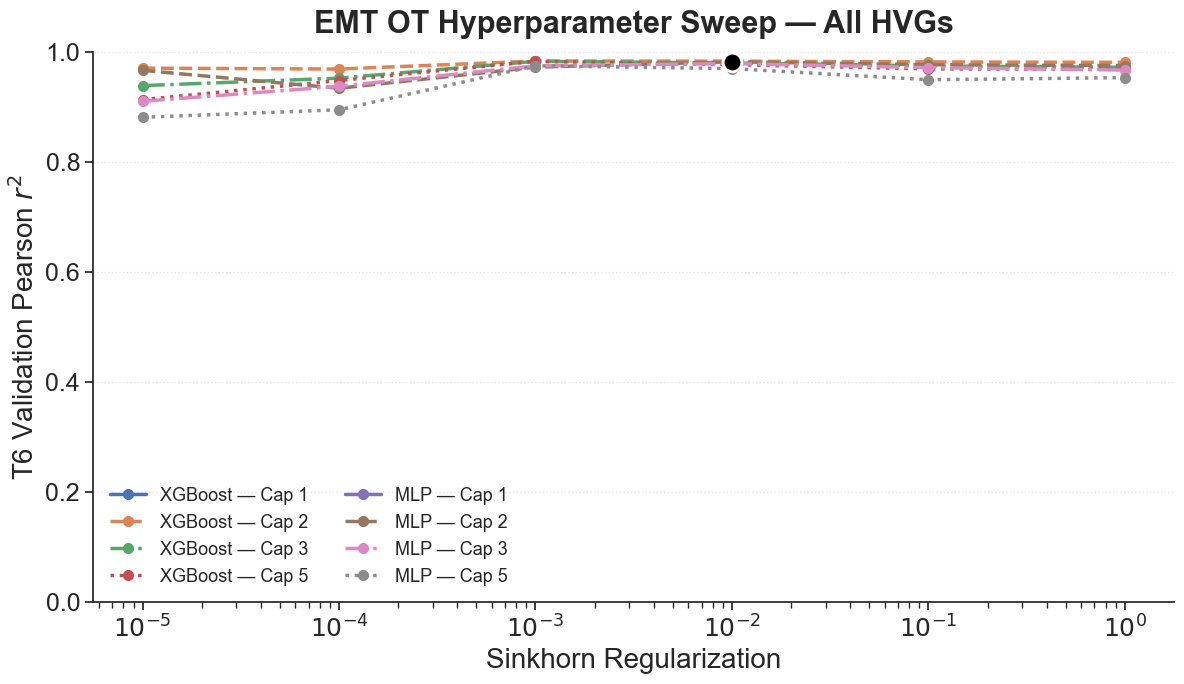

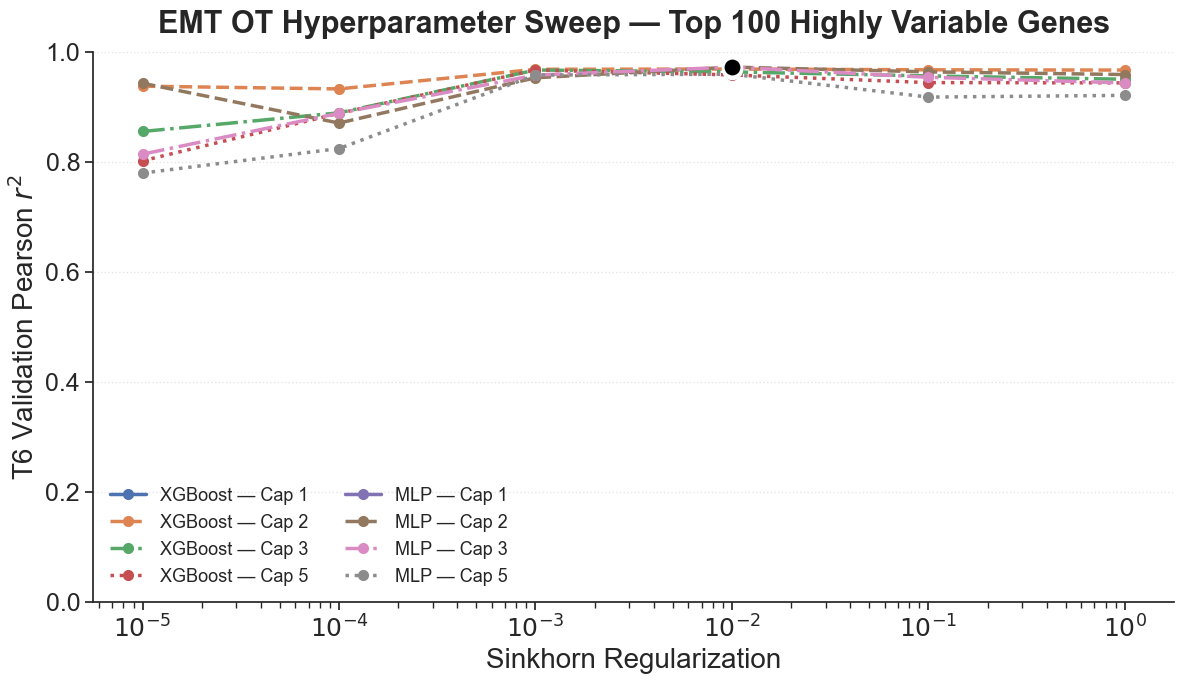

Saved:
EMT_publication_ot_sweep_allHVG_500PC.png
EMT_publication_ot_sweep_top100_500PC.png

Selected Sinkhorn regularization: 0.01
Selected target-use cap: 2
Selected mean Top-100 Pearson r²: 0.9716

✔ OT setting selected from Top-100 HVG performance
✔ Selection = highest mean Top-100 Pearson r² across XGBoost and MLP
✔ Selected setting highlighted with larger black dots
✔ All-HVG graph retained
✔ Top-100 HVG graph retained
✔ No OT recalculation
✔ No model retraining
✔ T6 validation endpoint
✔ T7 / Day 8 remains sealed
✔ 300 DPI


In [ ]:
# =========================================================
# EMT OT HYPERPARAMETER SWEEP — GRAPHING ONLY
# EXISTING df_ot_hp RESULTS
# FIXED 500-PC REPRESENTATION
# SELECTION BASED ON TOP-100 HVGs
# =========================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

reg_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
cap_values = [1, 2, 3, 5]

linestyles = {1: "-", 2: "--", 3: "-.", 5: ":"}

# =========================================================
# SELECT BEST OT SETTING USING TOP-100 HVGs
# =========================================================

df_ot_hp["Top100_Mean"] = df_ot_hp[["XGBoost_Top100", "MLP_Top100"]].mean(axis=1)

best_idx = df_ot_hp["Top100_Mean"].idxmax()
best_row = df_ot_hp.loc[best_idx]

best_reg = best_row["Reg"]
best_cap = int(best_row["Target_Cap"])

print("Selected OT hyperparameters from Top-100 HVGs:")
print(f"Regularization: {best_reg}")
print(f"Target-use cap: {best_cap}")
print(f"XGBoost Top-100 Pearson r²: {best_row['XGBoost_Top100']:.4f}")
print(f"MLP Top-100 Pearson r²: {best_row['MLP_Top100']:.4f}")
print(f"Mean Top-100 Pearson r²: {best_row['Top100_Mean']:.4f}")

# =========================================================
# ALL HVGs
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))

for model_name, column in {"XGBoost": "XGBoost_All", "MLP": "MLP_All"}.items():
    for cap_value in cap_values:
        sub = df_ot_hp[df_ot_hp["Target_Cap"] == cap_value].sort_values("Reg")
        ax.plot(
            sub["Reg"],
            sub[column],
            marker="o",
            linewidth=2.5,
            markersize=7,
            linestyle=linestyles[cap_value],
            label=f"{model_name} — Cap {cap_value}"
        )

# Highlight Top-100-selected OT setting with larger black dots
for column in ["XGBoost_All", "MLP_All"]:
    ax.scatter(
        best_reg,
        best_row[column],
        s=180,
        color="black",
        edgecolor="white",
        linewidth=2.0,
        zorder=10
    )

ax.set_xscale("log")

ax.set_title(
    "EMT OT Hyperparameter Sweep — All HVGs",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Sinkhorn Regularization", fontsize=20)
ax.set_ylabel("T6 Validation Pearson $r^2$", fontsize=20)

ax.set_xticks(reg_values)
ax.set_xticklabels(
    [r"$10^{-5}$", r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^{0}$"],
    fontsize=18
)

ax.tick_params(axis="y", labelsize=18)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(frameon=False, ncol=2, fontsize=13)

sns.despine()
plt.tight_layout()

plt.savefig(
    "EMT_publication_ot_sweep_allHVG_500PC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# TOP 100 HIGHLY VARIABLE GENES
# =========================================================

fig, ax = plt.subplots(figsize=(10, 8))

for model_name, column in {"XGBoost": "XGBoost_Top100", "MLP": "MLP_Top100"}.items():
    for cap_value in cap_values:
        sub = df_ot_hp[df_ot_hp["Target_Cap"] == cap_value].sort_values("Reg")
        ax.plot(
            sub["Reg"],
            sub[column],
            marker="o",
            linewidth=2.5,
            markersize=7,
            linestyle=linestyles[cap_value],
            label=f"{model_name} — Cap {cap_value}"
        )

# Highlight selected OT setting with larger black dots
for column in ["XGBoost_Top100", "MLP_Top100"]:
    ax.scatter(
        best_reg,
        best_row[column],
        s=180,
        color="black",
        edgecolor="white",
        linewidth=2.0,
        zorder=10
    )

ax.set_xscale("log")

ax.set_title(
    "EMT OT Hyperparameter Sweep — Top 100 Highly Variable Genes",
    fontsize=22,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Sinkhorn Regularization", fontsize=20)
ax.set_ylabel("T6 Validation Pearson $r^2$", fontsize=20)

ax.set_xticks(reg_values)
ax.set_xticklabels(
    [r"$10^{-5}$", r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^{0}$"],
    fontsize=18
)

ax.tick_params(axis="y", labelsize=18)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(frameon=False, ncol=2, fontsize=13)

sns.despine()
plt.tight_layout()

plt.savefig(
    "EMT_publication_ot_sweep_top100_500PC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# STATUS
# =========================================================

print("Saved:")
print("EMT_publication_ot_sweep_allHVG_500PC.png")
print("EMT_publication_ot_sweep_top100_500PC.png")

print(f"\nSelected Sinkhorn regularization: {best_reg}")
print(f"Selected target-use cap: {best_cap}")
print(f"Selected mean Top-100 Pearson r²: {best_row['Top100_Mean']:.4f}")

print("\n✔ OT setting selected from Top-100 HVG performance")
print("✔ Selection = highest mean Top-100 Pearson r² across XGBoost and MLP")
print("✔ Selected setting highlighted with larger black dots")
print("✔ All-HVG graph retained")
print("✔ Top-100 HVG graph retained")
print("✔ No OT recalculation")
print("✔ No model retraining")
print("✔ T6 validation endpoint")
print("✔ T7 / Day 8 remains sealed")
print("✔ 300 DPI")